# Final Pipeline — Advanced Computer Vision & Deep Learning — Ford

## Setup & imports

In [1]:
# %pip install seaborn

In [2]:
import os, sys, json, random, platform, time
import numpy as np, torch, torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
import pandas as pd                               
from pathlib import Path
from collections import Counter, OrderedDict
from PIL import Image
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split as tts
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from scipy.stats import pearsonr, spearmanr, binomtest, wilcoxon

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

try:
    import google.colab                  
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    PLANTVILLAGE_ROOT = '/content/drive/MyDrive/CV_Project/PlantVillage'
    PLANTDOC_ROOT     = '/content/drive/MyDrive/CV_Project/PlantDoc'
    OUTPUT_ROOT       = '/content/drive/MyDrive/CV_Project/outputs'
else:                                          
    PLANTVILLAGE_ROOT = '../CV_Project_Data/PlantVillage'
    PLANTDOC_ROOT     = '../CV_Project_Data/PlantDoc'
    OUTPUT_ROOT       = 'outputs'

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')                # Apple-silicon GPU for local runs
else:
    device = torch.device('cpu')
if platform.system() == 'Darwin':
    torch.multiprocessing.set_start_method('fork', force=True)   # macOS 'spawn' can't pickle notebook-defined Datasets
print(f'Device: {device}  |  Colab: {IN_COLAB}')

Device: mps  |  Colab: False


In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
else:
    print(f'Running locally - data read from {Path(PLANTVILLAGE_ROOT).resolve().parent}')

Running locally - data read from /Users/michael/Desktop/Fall2026 Projects/CV_Project/CV_Project_Data


## Dataset structure

In [4]:
pv_root = Path(PLANTVILLAGE_ROOT) / 'Plant_leave_diseases_dataset_without_augmentation'

SKIP = {'Background_without_leaves'}
pv_classes = sorted([d.name for d in pv_root.iterdir() if d.is_dir() and d.name not in SKIP])
pv_counts = {c: len(list((pv_root / c).glob('*'))) for c in pv_classes}
num_classes = len(pv_classes)

print(f'PlantVillage: {num_classes} classes, {sum(pv_counts.values()):,} total images')
print(f'Smallest class: {min(pv_counts, key=pv_counts.get)} ({min(pv_counts.values())} imgs)')
print(f'Largest class:  {max(pv_counts, key=pv_counts.get)} ({max(pv_counts.values())} imgs)')

pd_root = Path(PLANTDOC_ROOT)
if pd_root.exists():
    print('PlantDoc subfolders:', [d.name for d in pd_root.iterdir() if d.is_dir()])
else:
    print('PlantDoc not found yet - only needed for cross-domain eval later.')

PlantVillage: 38 classes, 54,305 total images
Smallest class: Potato___healthy (152 imgs)
Largest class:  Orange___Haunglongbing_(Citrus_greening) (5507 imgs)
PlantDoc subfolders: ['PlantDoc-Dataset-master', 'PlantDoc-Object-Detection-Dataset-master']


## Class distribution

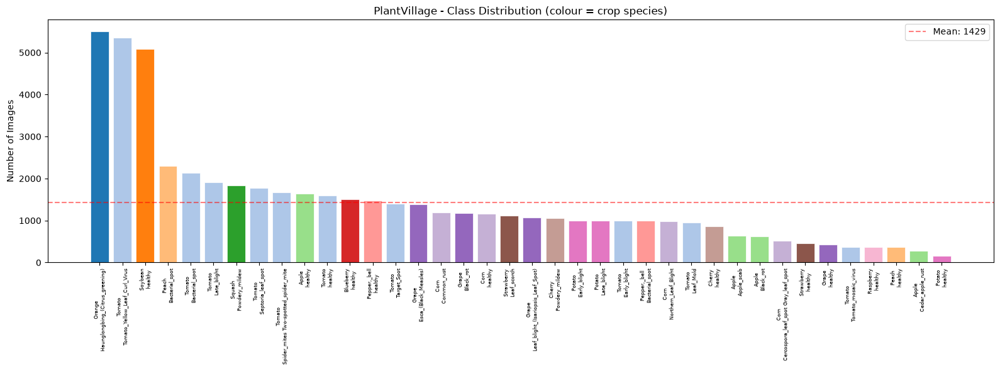


Imbalance ratio (max/min): 36.2x


In [5]:
sorted_cls = sorted(pv_counts.items(), key=lambda x: x[1], reverse=True)
names, counts = zip(*sorted_cls)
names, counts = list(names), list(counts)

species_colors, palette = {}, plt.cm.tab20(np.linspace(0, 1, 20))
cidx = 0
colors = []
for n in names:
    sp = n.split('___')[0]
    if sp not in species_colors:
        species_colors[sp] = palette[cidx % 20]; cidx += 1
    colors.append(species_colors[sp])

fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(range(len(counts)), counts, color=colors, edgecolor='white', linewidth=0.5)
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace('___', '\n') for n in names], rotation=90, fontsize=6)
ax.set_ylabel('Number of Images')
ax.set_title('PlantVillage - Class Distribution (colour = crop species)')
ax.axhline(np.mean(counts), color='red', ls='--', alpha=.5, label=f'Mean: {np.mean(counts):.0f}')
ax.legend(); plt.tight_layout()
plt.show()

print(f'\nImbalance ratio (max/min): {max(counts)/min(counts):.1f}x')

## Healthy vs diseased samples

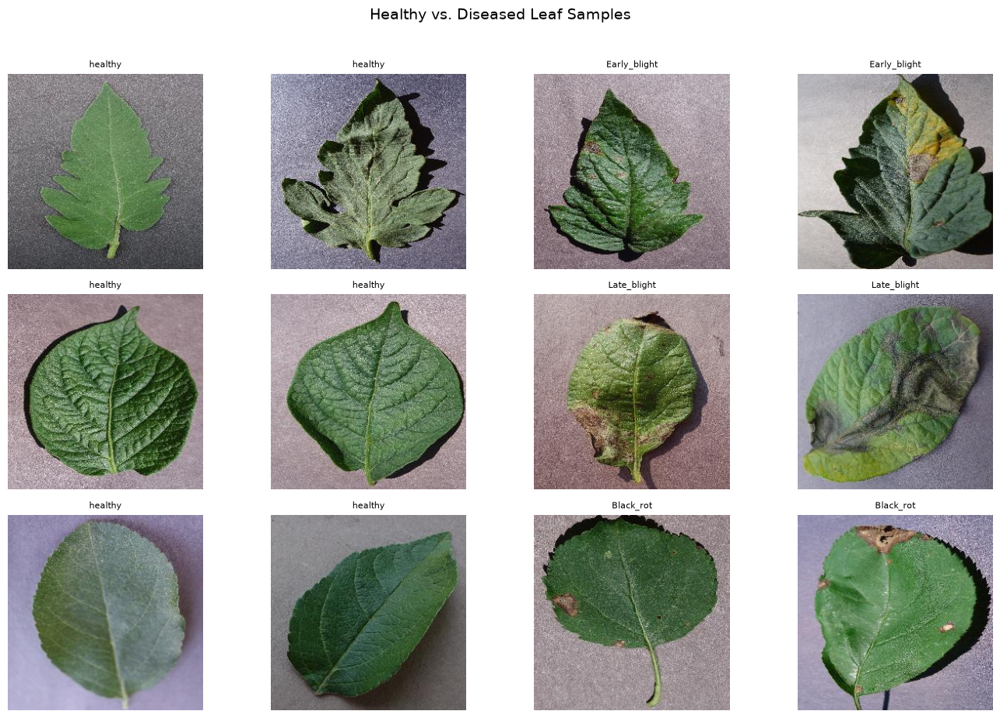

In [6]:
pairs = [
    ('Tomato___healthy',    'Tomato___Early_blight'),
    ('Potato___healthy',    'Potato___Late_blight'),
    ('Apple___healthy',     'Apple___Black_rot'),
]

fig, axes = plt.subplots(len(pairs), 4, figsize=(14, 3*len(pairs)))
fig.suptitle('Healthy vs. Diseased Leaf Samples', fontsize=14, y=1.02)
for row, (h_cls, d_cls) in enumerate(pairs):
    h_imgs = sorted((pv_root / h_cls).glob('*'))[:2]
    d_imgs = sorted((pv_root / d_cls).glob('*'))[:2]
    for col, p in enumerate(h_imgs + d_imgs):
        axes[row, col].imshow(Image.open(p))
        axes[row, col].set_title(
            (h_cls if col < 2 else d_cls).split('___')[1], fontsize=8)
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

## Lab vs field backgrounds

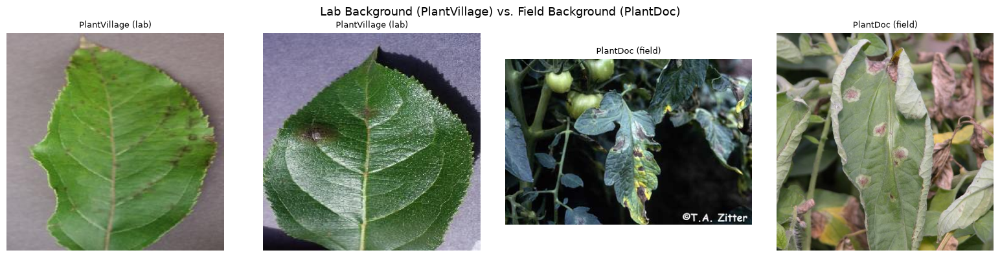

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle('Lab Background (PlantVillage) vs. Field Background (PlantDoc)', fontsize=13)

pv_imgs = sorted((pv_root / pv_classes[0]).glob('*'))[:2]
for i, p in enumerate(pv_imgs):
    axes[i].imshow(Image.open(p))
    axes[i].set_title('PlantVillage (lab)', fontsize=9)
    axes[i].axis('off')

pd_imgs = list(Path(PLANTDOC_ROOT).rglob('*.jpg')) + list(Path(PLANTDOC_ROOT).rglob('*.JPG'))
if len(pd_imgs) >= 2:
    for i, p in enumerate(pd_imgs[:2]):
        axes[i+2].imshow(Image.open(p))
        axes[i+2].set_title('PlantDoc (field)', fontsize=9)
        axes[i+2].axis('off')
else:
    for i in [2, 3]:
        axes[i].text(0.5, 0.5, 'PlantDoc not loaded yet', ha='center', va='center', fontsize=10)
        axes[i].axis('off')

plt.tight_layout()
plt.show()

## Resolution check

In [8]:
from PIL import Image
from pathlib import Path
from collections import Counter

widths, heights = [], []
for cls_dir in sorted(pv_root.iterdir()):
    if not cls_dir.is_dir() or cls_dir.name in SKIP:
        continue
    for img_path in list(cls_dir.glob('*'))[:50]:
        try:
            w, h = Image.open(img_path).size
            widths.append(w); heights.append(h)
        except Exception:
            pass

res_counts = Counter(zip(widths, heights))
print(f'Images sampled: {len(widths)}')
print(f'Unique resolutions: {len(res_counts)}')
for (w, h), n in res_counts.most_common(5):
    print(f'  {w}×{h}: {n} images ({n/len(widths)*100:.1f}%)')

if len(res_counts) == 1:
    print('\nAll 256x256 — uniform downscale to 224x224, no aspect ratio issues.')
else:
    print(f'\nAspect ratio range: {min(w/h for w,h in res_counts):.2f} – {max(w/h for w,h in res_counts):.2f}')

Images sampled: 1900
Unique resolutions: 1
  256×256: 1900 images (100.0%)

All 256x256 — uniform downscale to 224x224, no aspect ratio issues.


## Preprocessing transforms

In [9]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

raw_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

print('train:', train_transform)
print('eval: ', eval_transform)

train: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.05, 0.05))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
eval:  Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## Augmentation examples

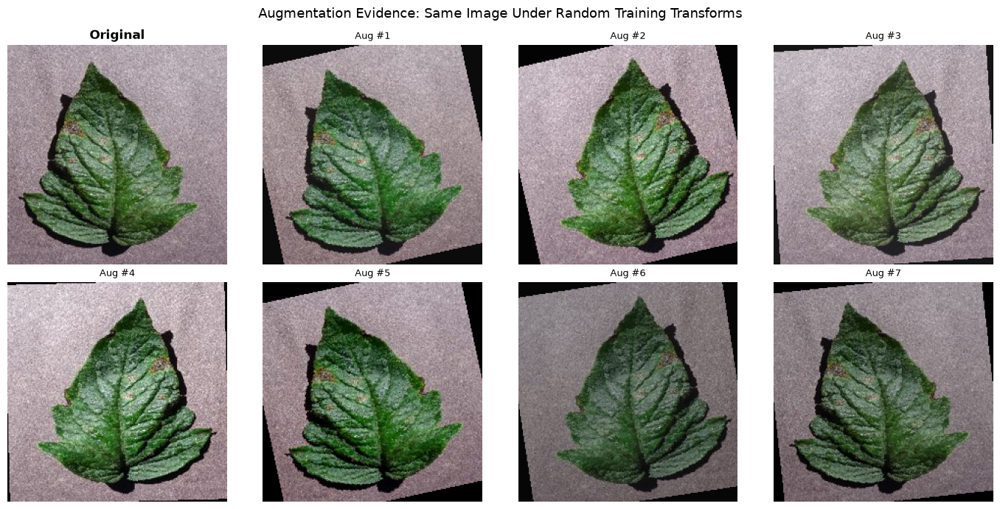

In [10]:
sample_path = sorted((pv_root / 'Tomato___Early_blight').glob('*'))[0]
orig = Image.open(sample_path).resize((224, 224))

display_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
])

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle('Augmentation Evidence: Same Image Under Random Training Transforms', fontsize=13)
axes[0, 0].imshow(orig)
axes[0, 0].set_title('Original', fontweight='bold')
axes[0, 0].axis('off')
for i in range(7):
    r, c = divmod(i + 1, 4)
    axes[r, c].imshow(display_aug(orig))
    axes[r, c].set_title(f'Aug #{i+1}', fontsize=9)
    axes[r, c].axis('off')
plt.tight_layout()
plt.show()

## Channel stats vs ImageNet

In [11]:
print('Computing channel stats (may take a few minutes from Drive)...')
raw_ds = ImageFolder(str(pv_root), transform=raw_transform)
loader = DataLoader(raw_ds, batch_size=64, shuffle=True, num_workers=2)

ch_sum, ch_sq, n_px, n_batch = torch.zeros(3), torch.zeros(3), 0, 0
for imgs, _ in loader:
    b, c, h, w = imgs.shape
    ch_sum += imgs.sum(dim=[0, 2, 3])
    ch_sq  += (imgs ** 2).sum(dim=[0, 2, 3])
    n_px   += b * h * w
    n_batch += 1
    if n_batch >= 50:
        break

ds_mean = ch_sum / n_px
ds_std  = (ch_sq / n_px - ds_mean ** 2).sqrt()
in_mean = torch.tensor([0.485, 0.456, 0.406])
in_std  = torch.tensor([0.229, 0.224, 0.225])

print(f"{'':18} {'R':>8} {'G':>8} {'B':>8}")
print(f"{'Dataset mean':18} {ds_mean[0]:.4f}   {ds_mean[1]:.4f}   {ds_mean[2]:.4f}")
print(f"{'ImageNet mean':18} {in_mean[0]:.4f}   {in_mean[1]:.4f}   {in_mean[2]:.4f}")
print(f"{'Dataset std':18} {ds_std[0]:.4f}   {ds_std[1]:.4f}   {ds_std[2]:.4f}")
print(f"{'ImageNet std':18} {in_std[0]:.4f}   {in_std[1]:.4f}   {in_std[2]:.4f}")

Computing channel stats (may take a few minutes from Drive)...
                          R        G        B
Dataset mean       0.4663   0.4889   0.4115
ImageNet mean      0.4850   0.4560   0.4060
Dataset std        0.1964   0.1719   0.2144
ImageNet std       0.2290   0.2240   0.2250


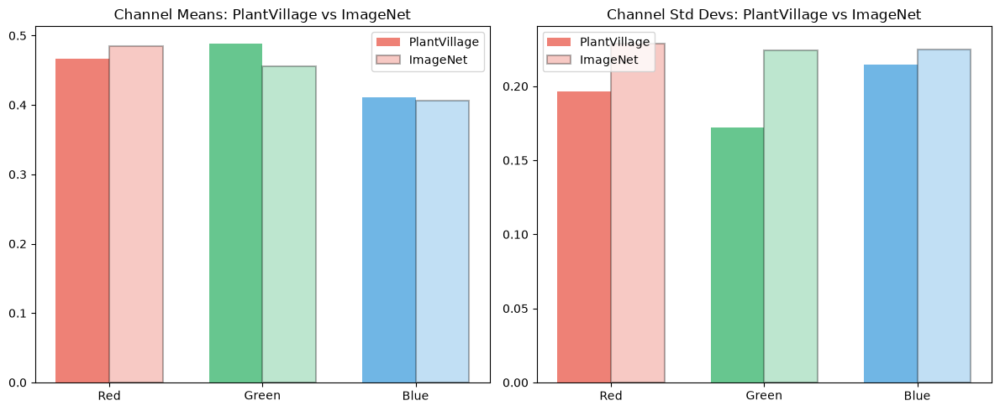

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x, w = np.arange(3), 0.35
ch_names = ['Red', 'Green', 'Blue']
ch_colors = ['#e74c3c', '#27ae60', '#3498db']

for ax, ds_vals, in_vals, title in [
    (axes[0], ds_mean.numpy(), in_mean.numpy(), 'Channel Means'),
    (axes[1], ds_std.numpy(),  in_std.numpy(),  'Channel Std Devs'),
]:
    ax.bar(x - w/2, ds_vals, w, label='PlantVillage', color=ch_colors, alpha=0.7)
    ax.bar(x + w/2, in_vals, w, label='ImageNet', color=ch_colors, alpha=0.3, edgecolor='black', lw=1.5)
    ax.set_xticks(x)
    ax.set_xticklabels(ch_names)
    ax.set_title(f'{title}: PlantVillage vs ImageNet')
    ax.legend()

plt.tight_layout()
plt.show()

stats = {'dataset_mean': ds_mean.tolist(), 'dataset_std': ds_std.tolist(),
         'imagenet_mean': in_mean.tolist(), 'imagenet_std': in_std.tolist(),
         'images_sampled': n_batch * 64}

## Pixel histograms before/after normalisation

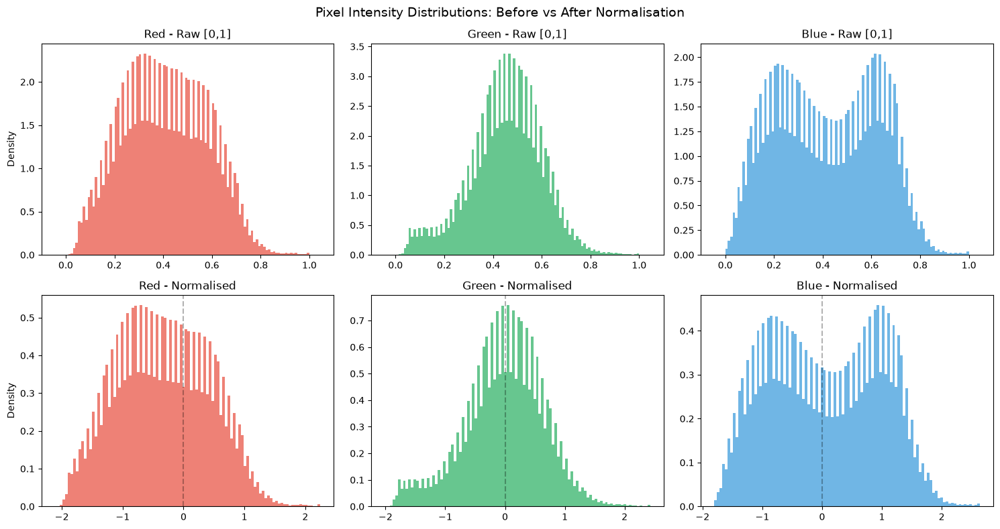

In [13]:
raw_ds2 = ImageFolder(str(pv_root), transform=raw_transform)
norm_ds = ImageFolder(str(pv_root), transform=eval_transform)

raw_imgs  = torch.stack([raw_ds2[i][0] for i in range(500)])
norm_imgs = torch.stack([norm_ds[i][0] for i in range(500)])

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Pixel Intensity Distributions: Before vs After Normalisation', fontsize=14)
ch_names  = ['Red', 'Green', 'Blue']
ch_colors = ['#e74c3c', '#27ae60', '#3498db']

for c in range(3):
    axes[0, c].hist(raw_imgs[:, c].flatten().numpy(), bins=100, color=ch_colors[c], alpha=0.7, density=True)
    axes[0, c].set_title(f'{ch_names[c]} - Raw [0,1]')
    axes[0, c].set_xlim(-0.1, 1.1)
    axes[1, c].hist(norm_imgs[:, c].flatten().numpy(), bins=100, color=ch_colors[c], alpha=0.7, density=True)
    axes[1, c].set_title(f'{ch_names[c]} - Normalised')
    axes[1, c].axvline(0, color='black', ls='--', alpha=0.3)
axes[0, 0].set_ylabel('Density')
axes[1, 0].set_ylabel('Density')

plt.tight_layout()
plt.show()

## Train/val/test split

In [14]:
from sklearn.model_selection import train_test_split

full_ds = ImageFolder(str(pv_root))

# Filter out Background_without_leaves
bg_name = 'Background_without_leaves'
if bg_name in full_ds.class_to_idx:
    bg_label = full_ds.class_to_idx[bg_name]
    keep = [i for i, (_, lbl) in enumerate(full_ds.samples) if lbl != bg_label]
else:
    keep = list(range(len(full_ds)))
    bg_label = None

# Remap labels to 0..37 with no gaps
filtered_classes = [c for c in full_ds.classes if c != bg_name]
old_to_new = {}
new_label = 0
for old_label, cls_name in enumerate(full_ds.classes):
    if cls_name != bg_name:
        old_to_new[old_label] = new_label
        new_label += 1

all_targets = [old_to_new[full_ds.targets[i]] for i in keep]
all_idx     = list(range(len(keep)))

train_idx, temp_idx = train_test_split(
    all_idx, test_size=0.30,
    stratify=[all_targets[i] for i in all_idx], random_state=SEED)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50,
    stratify=[all_targets[i] for i in temp_idx], random_state=SEED)

print(f'Filtered classes: {len(filtered_classes)}  (removed {bg_name})')
print(f'Train: {len(train_idx)}  Val: {len(val_idx)}  Test: {len(test_idx)}')
print(f'Total: {len(train_idx)+len(val_idx)+len(test_idx)}')
print(f'Label range: {min(all_targets)} – {max(all_targets)}  '
      f'({max(all_targets)-min(all_targets)+1} classes)')

# Wrapper to remap ImageFolder labels to contiguous 0..37
class RemappedSubset(torch.utils.data.Dataset):
    def __init__(self, dataset, indices, label_map):
        self.dataset = dataset
        self.indices = indices
        self.label_map = label_map
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, idx):
        img, lbl = self.dataset[self.indices[idx]]
        return img, self.label_map[lbl]

label_map = {old: new for old, new in zip(
    [full_ds.class_to_idx[c] for c in filtered_classes],
    range(num_classes)
)}

Filtered classes: 38  (removed Background_without_leaves)
Train: 38013  Val: 8146  Test: 8146
Total: 54305
Label range: 0 – 37  (38 classes)


## Split verification

Max class-proportion deviation in Train: 0.001%
Max class-proportion deviation in Val: 0.009%
Max class-proportion deviation in Test: 0.009%


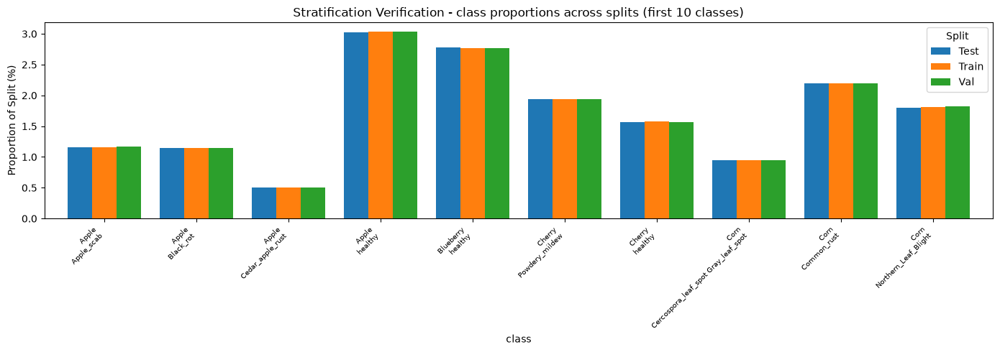

In [15]:
records = []
for name, idxs in [('Train', train_idx), ('Val', val_idx), ('Test', test_idx)]:
    for i in idxs:
        records.append({'split': name, 'class': filtered_classes[all_targets[i]]})
df = pd.DataFrame(records)

props = df.groupby(['split', 'class']).size().unstack(level=0, fill_value=0)
props_pct = props.div(props.sum(axis=0), axis=1) * 100

overall_pct = pd.Series(Counter(all_targets)).sort_index() / len(all_targets) * 100
for s in ['Train', 'Val', 'Test']:
    dev = np.abs(props_pct[s].values - overall_pct.values).max()
    print(f'Max class-proportion deviation in {s}: {dev:.3f}%')

# Only plot classes that actually exist in the filtered data
sample_cls = filtered_classes[:10]
fig, ax = plt.subplots(figsize=(14, 5))
props_pct.loc[sample_cls].plot(kind='bar', ax=ax, width=0.8)
ax.set_ylabel('Proportion of Split (%)')
ax.set_title('Stratification Verification - class proportions across splits (first 10 classes)')
ax.set_xticklabels([c.replace('___', '\n') for c in sample_cls], rotation=45, ha='right', fontsize=7)
ax.legend(title='Split')
plt.tight_layout()
plt.show()

## Loaders and class weights

In [16]:
train_ds = ImageFolder(str(pv_root), transform=train_transform)
eval_ds  = ImageFolder(str(pv_root), transform=eval_transform)

# Remap labels so Background_without_leaves gap is closed (0-37 contiguous)
train_sub = RemappedSubset(train_ds, [keep[i] for i in train_idx], label_map)
val_sub   = RemappedSubset(eval_ds,  [keep[i] for i in val_idx], label_map)
test_sub  = RemappedSubset(eval_ds,  [keep[i] for i in test_idx], label_map)

train_tgts   = [all_targets[i] for i in train_idx]
cls_counts   = Counter(train_tgts)
total_train  = len(train_tgts)
class_weights = torch.tensor(
    [total_train / (num_classes * cls_counts.get(c, 1)) for c in range(num_classes)],
    dtype=torch.float32)

print(f'Class weights range: {class_weights.min():.2f} - {class_weights.max():.2f}')

train_loader = DataLoader(train_sub, batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_sub,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_sub,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

imgs, labels = next(iter(train_loader))
print(f'Sanity check - batch: {imgs.shape}, labels: {labels.shape}')
print(f'Label range in batch: {labels.min().item()}-{labels.max().item()} (expected within 0-{num_classes-1})')

Class weights range: 0.26 - 9.44


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1097: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Sanity check - batch: torch.Size([32, 3, 224, 224]), labels: torch.Size([32])
Label range in batch: 0-37 (expected within 0-37)


## Leakage checks

In [17]:
# verify no overlap between splits
assert set(train_idx).isdisjoint(set(val_idx)), 'train/val overlap!'
assert set(train_idx).isdisjoint(set(test_idx)), 'train/test overlap!'
assert set(val_idx).isdisjoint(set(test_idx)), 'val/test overlap!'
assert len(train_idx) + len(val_idx) + len(test_idx) == len(all_idx), 'missing samples'

# confirm augmentation is train-only
print('train transform:', type(train_transform.transforms[1]).__name__)  # RandomHorizontalFlip
print('eval transform: ', type(eval_transform.transforms[0]).__name__)   # Resize (no aug)
print('No leakage — splits are disjoint, augmentation is train-only.')

train transform: RandomHorizontalFlip
eval transform:  Resize
No leakage — splits are disjoint, augmentation is train-only.


## Model candidates

## Architecture definitions

In [18]:
class BaselineCNN(nn.Module):
    """Simple 3-block CNN. No skip connections, no pretraining."""
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.5), nn.Linear(128, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

def make_resnet50(nc):
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    m.fc = nn.Linear(m.fc.in_features, nc)
    return m

def make_efficientnet(nc):
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, nc)
    return m

def make_vit(nc):
    m = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)
    m.heads.head = nn.Linear(m.heads.head.in_features, nc)
    return m

## Augmentation ablation

With Augmentation:  val_loss epoch 3 = 2.101
Without Augmentation:  val_loss epoch 3 = 1.921


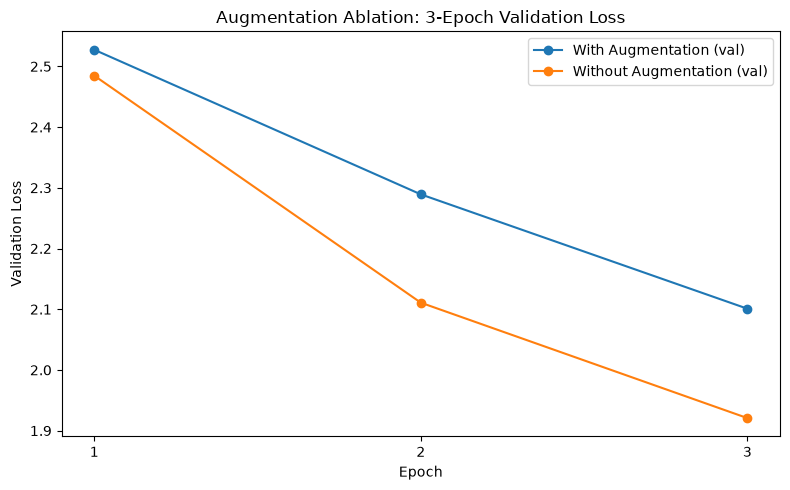


Val loss gap at epoch 3: -0.180
No clear benefit yet at 3 epochs.


In [19]:
quick_train = RemappedSubset(train_ds, [keep[i] for i in train_idx[:2000]], label_map)
quick_val   = RemappedSubset(eval_ds,  [keep[i] for i in val_idx[:500]], label_map)
noaug_train = RemappedSubset(eval_ds,  [keep[i] for i in train_idx[:2000]], label_map)

results = {}
for label, t_set in [('With Augmentation', quick_train),
                      ('Without Augmentation', noaug_train)]:
    loader_t = DataLoader(t_set, batch_size=32, shuffle=True, num_workers=2)
    loader_v = DataLoader(quick_val, batch_size=32, shuffle=False, num_workers=2)

    model = BaselineCNN(num_classes).to(device)
    opt   = torch.optim.Adam(model.parameters(), lr=1e-3)
    crit  = nn.CrossEntropyLoss()

    train_losses, val_losses = [], []
    for epoch in range(3):
        model.train()
        running = 0.0
        for imgs, lbls in loader_t:
            imgs, lbls = imgs.to(device), lbls.to(device)
            opt.zero_grad()
            loss = crit(model(imgs), lbls)
            loss.backward(); opt.step()
            running += loss.item()
        train_losses.append(running / len(loader_t))

        model.eval()
        val_run = 0.0
        with torch.no_grad():
            for imgs, lbls in loader_v:
                imgs, lbls = imgs.to(device), lbls.to(device)
                val_run += crit(model(imgs), lbls).item()
        val_losses.append(val_run / len(loader_v))

    results[label] = {'train': train_losses, 'val': val_losses}
    print(f'{label}:  val_loss epoch 3 = {val_losses[-1]:.3f}')

fig, ax = plt.subplots(figsize=(8, 5))
for label, data in results.items():
    style = '-o' if 'With' in label else '--s'
    ax.plot(range(1, 4), data['val'], style, label=f'{label} (val)')
ax.set_xlabel('Epoch'); ax.set_ylabel('Validation Loss')
ax.set_title('Augmentation Ablation: 3-Epoch Validation Loss')
ax.legend(); ax.set_xticks([1, 2, 3])
plt.tight_layout()
plt.show()

diff = results['Without Augmentation']['val'][-1] - results['With Augmentation']['val'][-1]
print(f'\nVal loss gap at epoch 3: {diff:+.3f}')
if diff > 0:
    print('Augmented training has lower val loss, augmentation is helping.')
else:
    print('No clear benefit yet at 3 epochs.')

## Parameter counts

In [20]:
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

candidates = OrderedDict()
candidates['Baseline CNN']    = BaselineCNN(num_classes)
candidates['ResNet-50']       = make_resnet50(num_classes)
candidates['EfficientNet-B0'] = make_efficientnet(num_classes)
candidates['ViT-B/16']        = make_vit(num_classes)

# GFLOPs at 224x224 input, ResNet/EfficientNet/ViT from torchvision model docs;
# Baseline CNN estimated via manual calculation (3 conv layers, ~0.2 GFLOPs)
lit_flops = {'Baseline CNN': 0.2, 'ResNet-50': 4.1, 'EfficientNet-B0': 0.4, 'ViT-B/16': 17.6}

rows = []
for name, model in candidates.items():
    total, trainable = count_params(model)
    rows.append({
        'Model': name,
        'Total Params': f'{total/1e6:.1f}M',
        'Trainable': f'{trainable/1e6:.1f}M',
        'GFLOPs': f'{lit_flops[name]:.1f}',
        'Pretrained': 'No' if name == 'Baseline CNN' else 'Yes (ImageNet)',
    })

comp_df = pd.DataFrame(rows)
print(comp_df.to_string(index=False))

          Model Total Params Trainable GFLOPs     Pretrained
   Baseline CNN         0.1M      0.1M    0.2             No
      ResNet-50        23.6M     23.6M    4.1 Yes (ImageNet)
EfficientNet-B0         4.1M      4.1M    0.4 Yes (ImageNet)
       ViT-B/16        85.8M     85.8M   17.6 Yes (ImageNet)


## Published baselines

In [21]:
lit = pd.DataFrame([
    {'Model': 'Baseline CNN (3-block)',  'Reported Acc': '—',
     'Source': '—',                      'Notes': 'No published match; custom 0.10M-param network'},
    {'Model': 'ResNet-50 (fine-tuned)',  'Reported Acc': 'up to 99.75%',
     'Source': 'Too et al. 2019',        'Notes': 'DenseNet best; ResNet-50 tested, individual number in full paper'},
    {'Model': 'EfficientNet-B0',         'Reported Acc': '—',
     'Source': 'Atila et al. 2021',      'Notes': 'B5/B4 best at 99.91%; B0 number not in abstract'},
    {'Model': 'ViT (various sizes)',     'Reported Acc': '—',
     'Source': '—',                      'Notes': 'Citation not verified; dropped'},
])
print(lit.to_string(index=False))

                 Model Reported Acc            Source                                                            Notes
Baseline CNN (3-block)            —                 —                   No published match; custom 0.10M-param network
ResNet-50 (fine-tuned) up to 99.75%   Too et al. 2019 DenseNet best; ResNet-50 tested, individual number in full paper
       EfficientNet-B0            — Atila et al. 2021                  B5/B4 best at 99.91%; B0 number not in abstract
   ViT (various sizes)            —                 —                                   Citation not verified; dropped


## Reasoning

In [22]:
# Selected: Baseline CNN + ResNet-50
# Baseline CNN (0.10M params):
#   It is used here as a lower bound. It has no skip connections and no
#   pretraining. It is expected to rely on background shortcuts. This is
#   testable via Grad-CAM on PlantDoc. It is also shallow enough that its
#   attention should be diffuse. This means attention will not be
#   disease-focused.
#
# ResNet-50 (25.6M params, 22.14M trainable after freezing):
#   Fine-tuning works here because the frozen early layers retain general
#   ImageNet features (edges, textures) that transfer to plant leaves. Only
#   the later layers and the new 38-class head are trained on PlantVillage.
#   Too et al. (2019) used a similar setup. The clean residual blocks
#   produce a single unambiguous Grad-CAM target layer, which is
#   layer4[-1]. Training runs at about 8-9 minutes per epoch on MPS
#   (Apple M-series). This means it fits the compute budget.
#
# Rejected:
#   EfficientNet-B0 was rejected because compound scaling produces multiple
#   candidate Grad-CAM layers with no clear "last conv." This is the wrong
#   tool for attention faithfulness analysis.
#
#   ViT-B/16 was rejected because the research question specifically
#   targets CNN attention mechanisms. This means transformer self-attention
#   is out of scope. With ResNet-50 at 99.7%, a different backbone has
#   under 0.3 points of accuracy to gain, so the cost of training
#   additional models is not justified.
print('Selected: Baseline CNN + ResNet-50')

Selected: Baseline CNN + ResNet-50


## Comparison chart

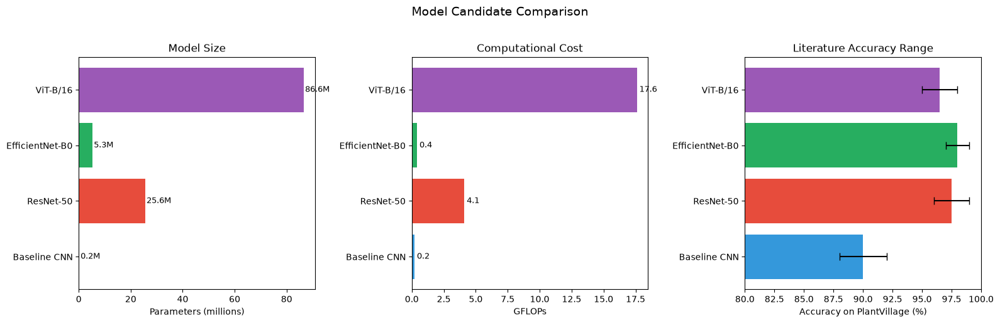

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Model Candidate Comparison', fontsize=14, y=1.02)

model_names = ['Baseline CNN', 'ResNet-50', 'EfficientNet-B0', 'ViT-B/16']
colors = ['#3498db', '#e74c3c', '#27ae60', '#9b59b6']

params = [0.2, 25.6, 5.3, 86.6]
axes[0].barh(model_names, params, color=colors)
axes[0].set_xlabel('Parameters (millions)')
axes[0].set_title('Model Size')
for i, v in enumerate(params):
    axes[0].text(v + 0.5, i, f'{v}M', va='center', fontsize=9)

flops = [0.2, 4.1, 0.4, 17.6]
axes[1].barh(model_names, flops, color=colors)
axes[1].set_xlabel('GFLOPs')
axes[1].set_title('Computational Cost')
for i, v in enumerate(flops):
    axes[1].text(v + 0.2, i, f'{v}', va='center', fontsize=9)

acc_low  = [88, 96, 97, 95]
acc_high = [92, 99, 99, 98]
acc_mid  = [(l+h)/2 for l, h in zip(acc_low, acc_high)]
xerr = [[(m-l) for m, l in zip(acc_mid, acc_low)],
        [(h-m) for m, h in zip(acc_mid, acc_high)]]
axes[2].barh(model_names, acc_mid, xerr=xerr, color=colors, capsize=4)
axes[2].set_xlabel('Accuracy on PlantVillage (%)')
axes[2].set_title('Literature Accuracy Range')
axes[2].set_xlim(80, 100)

plt.tight_layout()
plt.show()

## Verification

In [24]:
baseline = BaselineCNN(num_classes).to(device)
resnet   = make_resnet50(num_classes).to(device)

dummy = torch.randn(1, 3, 224, 224).to(device)
out_b = baseline(dummy)
out_r = resnet(dummy)

print(f'Baseline CNN  output: {out_b.shape}  (expected [1, {num_classes}])')
print(f'ResNet-50     output: {out_r.shape}  (expected [1, {num_classes}])')

Baseline CNN  output: torch.Size([1, 38])  (expected [1, 38])
ResNet-50     output: torch.Size([1, 38])  (expected [1, 38])


# Model Training

In [25]:
def make_resnet50_finetune(nc):
    m = make_resnet50(nc)
    for name, p in m.named_parameters():
        if name.startswith(('conv1', 'bn1', 'layer1', 'layer2')):
            p.requires_grad = False
    return m

torch.manual_seed(SEED)
baseline_model = BaselineCNN(num_classes).to(device)
resnet_model = make_resnet50_finetune(num_classes).to(device)

dummy = torch.randn(2, 3, 224, 224).to(device)
for name, model in [('Baseline CNN', baseline_model), ('ResNet-50', resnet_model)]:
    model.eval()
    with torch.no_grad():
        out = model(dummy)
    total, trainable = count_params(model)
    print(f'{name:14s} output: {tuple(out.shape)} | '
          f'{total/1e6:.2f}M total, {trainable/1e6:.2f}M trainable')

Baseline CNN   output: (2, 38) | 0.10M total, 0.10M trainable
ResNet-50      output: (2, 38) | 23.59M total, 22.14M trainable


## Training Loop

In [26]:
FORCE_RECOMPUTE = False

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

def train_one_epoch(model, loader, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, lbls in loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        out = model(imgs)
        loss = criterion(out, lbls)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        correct += (out.argmax(1) == lbls).sum().item()
        total += imgs.size(0)
    return running_loss / total, correct / total

def evaluate(model, loader):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            out = model(imgs)
            loss = criterion(out, lbls)
            running_loss += loss.item() * imgs.size(0)
            correct += (out.argmax(1) == lbls).sum().item()
            total += imgs.size(0)
    return running_loss / total, correct / total

def fit(model, key, optimizer, scheduler, epochs):
    os.makedirs(OUTPUT_ROOT, exist_ok=True)
    ckpt_path = f'{OUTPUT_ROOT}/{key}_best.pt'
    hist_path = f'{OUTPUT_ROOT}/{key}_history.json'

    if not FORCE_RECOMPUTE and os.path.exists(ckpt_path) and os.path.exists(hist_path):
        with open(hist_path) as f:
            history = json.load(f)
        if len(history['train_loss']) == epochs:
            model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
            print(f'Loaded cached {key}: {epochs} epochs, '
                  f'best val_loss={min(history["val_loss"]):.4f}')
            return history
        else:
            print(f'Incomplete run found for {key} '
                  f'({len(history["train_loss"])}/{epochs} epochs), retraining.')

    best_val_loss = float('inf')
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'epoch_time': []}

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate(model, val_loader)
        scheduler.step()
        elapsed = time.time() - t0

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['epoch_time'].append(round(elapsed, 1))

        tag = ''
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), ckpt_path)
            tag = ' *'

        with open(hist_path, 'w') as f:
            json.dump(history, f)

        print(f'Epoch {epoch:02d}/{epochs}  '
              f'train_loss={train_loss:.4f}  train_acc={train_acc:.4f}  '
              f'val_loss={val_loss:.4f}  val_acc={val_acc:.4f}  '
              f'{elapsed:.0f}s{tag}')

    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    print(f'\nRestored best weights for {key} (val_loss={best_val_loss:.4f})')
    return history

print('Training helpers ready.')

Training helpers ready.


## Train Baseline CNN

In [27]:
torch.manual_seed(SEED)
baseline_model = BaselineCNN(num_classes).to(device)
opt_b = torch.optim.Adam(baseline_model.parameters(), lr=1e-3)
sched_b = torch.optim.lr_scheduler.CosineAnnealingLR(opt_b, T_max=20)
hist_baseline = fit(baseline_model, 'baseline_cnn', opt_b, sched_b, 20)

Loaded cached baseline_cnn: 20 epochs, best val_loss=0.4114


## Fine tuning ResNet50

In [28]:
torch.manual_seed(SEED)
resnet_model = make_resnet50_finetune(num_classes).to(device)

backbone_params = [p for n, p in resnet_model.named_parameters()
                   if p.requires_grad and 'fc' not in n]
opt_r = torch.optim.AdamW([
    {'params': backbone_params,              'lr': 1e-4},
    {'params': resnet_model.fc.parameters(), 'lr': 1e-3},
], weight_decay=1e-4)
sched_r = torch.optim.lr_scheduler.CosineAnnealingLR(opt_r, T_max=5)
hist_resnet = fit(resnet_model, 'resnet50', opt_r, sched_r, 5)

Loaded cached resnet50: 5 epochs, best val_loss=0.0163


## Training Curves

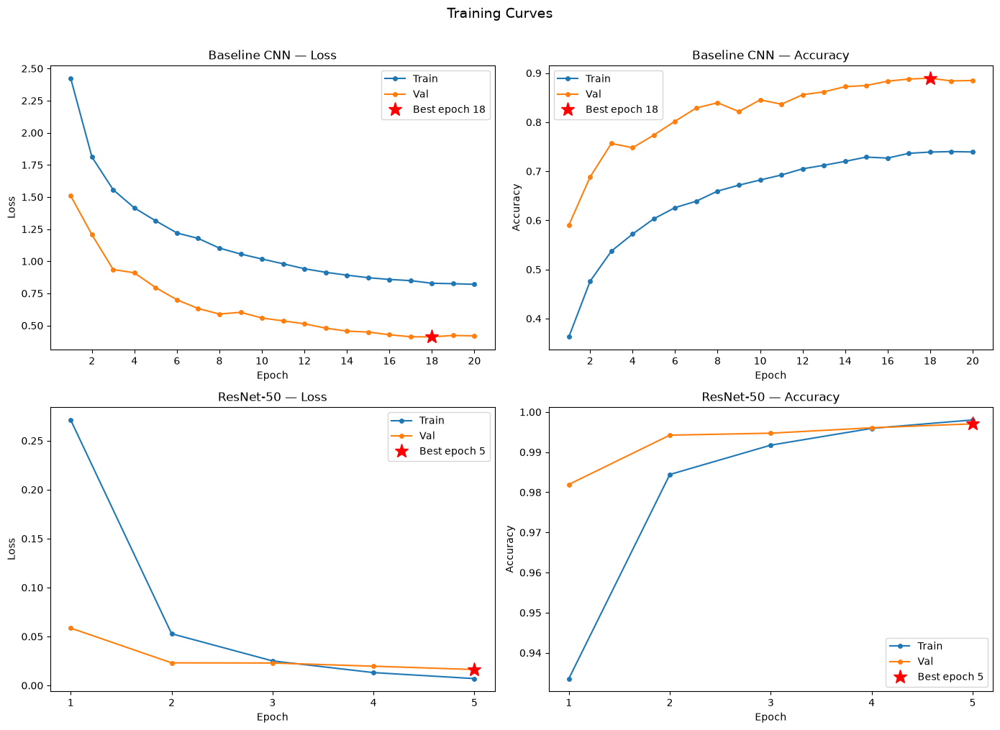

Baseline CNN    best epoch: 18  val_loss=0.4114  val_acc=0.8895  total: 39.1 min
ResNet-50       best epoch: 5  val_loss=0.0163  val_acc=0.9971  total: 43.5 min


In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Training Curves', fontsize=14, y=1.01)

for row, (name, hist) in enumerate([('Baseline CNN', hist_baseline),
                                     ('ResNet-50',    hist_resnet)]):
    n = len(hist['train_loss'])
    epochs = range(1, n + 1)
    best_epoch = int(np.argmin(hist['val_loss']))
    ticks = range(2, n + 1, 2) if n > 10 else list(epochs)

    ax_loss = axes[row, 0]
    ax_loss.plot(epochs, hist['train_loss'], '-o', ms=4, label='Train')
    ax_loss.plot(epochs, hist['val_loss'],   '-o', ms=4, label='Val')
    ax_loss.plot(best_epoch + 1, hist['val_loss'][best_epoch],
                 '*', ms=14, color='red', label=f'Best epoch {best_epoch + 1}')
    ax_loss.set_xlabel('Epoch')
    ax_loss.set_ylabel('Loss')
    ax_loss.set_title(f'{name} — Loss')
    ax_loss.set_xticks(ticks)
    ax_loss.legend()

    ax_acc = axes[row, 1]
    ax_acc.plot(epochs, hist['train_acc'], '-o', ms=4, label='Train')
    ax_acc.plot(epochs, hist['val_acc'],   '-o', ms=4, label='Val')
    ax_acc.plot(best_epoch + 1, hist['val_acc'][best_epoch],
                '*', ms=14, color='red', label=f'Best epoch {best_epoch + 1}')
    ax_acc.set_xlabel('Epoch')
    ax_acc.set_ylabel('Accuracy')
    ax_acc.set_title(f'{name} — Accuracy')
    ax_acc.set_xticks(ticks)
    ax_acc.legend()

plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

for name, hist in [('Baseline CNN', hist_baseline), ('ResNet-50', hist_resnet)]:
    best = int(np.argmin(hist['val_loss']))
    total_time = sum(hist.get('epoch_time', [0]))
    print(f'{name:14s}  best epoch: {best+1}  '
          f'val_loss={hist["val_loss"][best]:.4f}  val_acc={hist["val_acc"][best]:.4f}  '
          f'total: {total_time/60:.1f} min')

## Evaluating the Test Set

In [30]:
def predict(model, loader):
    model.eval()
    all_probs = []
    with torch.no_grad():
        for imgs, _ in loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            all_probs.append(F.softmax(logits, dim=1).cpu())
    return torch.cat(all_probs)

test_labels = torch.tensor([all_targets[i] for i in test_idx])
test_probs = {}
test_preds = {}

for name, model in [('Baseline CNN', baseline_model), ('ResNet-50', resnet_model)]:
    probs = predict(model, test_loader)
    preds = probs.argmax(dim=1)
    assert len(probs) == len(test_labels), f'{name}: prob/label length mismatch'

    test_probs[name] = probs
    test_preds[name] = preds

    acc = (preds == test_labels).float().mean().item()
    f1 = f1_score(test_labels, preds, average='macro')
    print(f'\n{"="*60}')
    print(f'{name}  |  Accuracy: {acc:.4f}  |  Macro-F1: {f1:.4f}')
    print(f'{"="*60}')
    print(classification_report(test_labels, preds,
                                target_names=filtered_classes, digits=4,
                                zero_division=0))

torch.save({'probs': test_probs, 'preds': test_preds, 'labels': test_labels},
           f'{OUTPUT_ROOT}/test_predictions.pt')
print(f'Saved predictions to {OUTPUT_ROOT}/test_predictions.pt')

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1097: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



Baseline CNN  |  Accuracy: 0.8898  |  Macro-F1: 0.8594
                                               precision    recall  f1-score   support

                           Apple___Apple_scab     0.6320    0.8404    0.7215        94
                            Apple___Black_rot     0.7080    0.8602    0.7767        93
                     Apple___Cedar_apple_rust     0.6897    0.9756    0.8081        41
                              Apple___healthy     0.9234    0.8333    0.8761       246
                          Blueberry___healthy     0.9098    0.9823    0.9447       226
                      Cherry___Powdery_mildew     0.9202    0.9494    0.9346       158
                             Cherry___healthy     0.6868    0.9766    0.8065       128
   Corn___Cercospora_leaf_spot Gray_leaf_spot     0.7882    0.8701    0.8272        77
                           Corn___Common_rust     0.9890    1.0000    0.9944       179
                  Corn___Northern_Leaf_Blight     0.9338    0.8639    0.8

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1097: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



ResNet-50  |  Accuracy: 0.9971  |  Macro-F1: 0.9956
                                               precision    recall  f1-score   support

                           Apple___Apple_scab     1.0000    0.9894    0.9947        94
                            Apple___Black_rot     1.0000    1.0000    1.0000        93
                     Apple___Cedar_apple_rust     1.0000    1.0000    1.0000        41
                              Apple___healthy     1.0000    1.0000    1.0000       246
                          Blueberry___healthy     1.0000    1.0000    1.0000       226
                      Cherry___Powdery_mildew     1.0000    1.0000    1.0000       158
                             Cherry___healthy     1.0000    1.0000    1.0000       128
   Corn___Cercospora_leaf_spot Gray_leaf_spot     0.9600    0.9351    0.9474        77
                           Corn___Common_rust     1.0000    1.0000    1.0000       179
                  Corn___Northern_Leaf_Blight     0.9597    0.9728    0.9662

## Duplicate check via MD5

In [31]:
import hashlib
from collections import defaultdict

def file_hash(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

# Hash every image once
hashes = [None] * len(keep)
hash_to_idxs = defaultdict(list)
for i in range(len(keep)):
    h = file_hash(full_ds.samples[keep[i]][0])
    hashes[i] = h
    hash_to_idxs[h].append(i)

dup_groups = {h: idxs for h, idxs in hash_to_idxs.items() if len(idxs) > 1}
print(f'Duplicate groups (byte-identical images): {len(dup_groups)}')

# Check whether any duplicate group spans two classes
cross_class = sum(1 for idxs in dup_groups.values()
                  if len(set(all_targets[i] for i in idxs)) > 1)
print(f'Duplicate groups spanning multiple classes: {cross_class}')

# Check train/test overlap using stored hashes
train_hashes = set(hashes[i] for i in train_idx)
test_in_train = sum(1 for i in test_idx if hashes[i] in train_hashes)
print(f'Test images with a byte-identical copy in train: '
      f'{test_in_train}/{len(test_idx)} ({test_in_train/len(test_idx)*100:.2f}%)')

Duplicate groups (byte-identical images): 21
Duplicate groups spanning multiple classes: 0
Test images with a byte-identical copy in train: 2/8146 (0.02%)


## McNemar

In [32]:
correct_b = (test_preds['Baseline CNN'] == test_labels)
correct_r = (test_preds['ResNet-50']    == test_labels)

b = int((~correct_b &  correct_r).sum())  # Baseline wrong, ResNet right
c = int(( correct_b & ~correct_r).sum())  # Baseline right, ResNet wrong

result = binomtest(min(b, c), n=b + c, p=0.5)

print(f'Disagreement images: {b + c}')
print(f'  Baseline wrong, ResNet right (b): {b}')
print(f'  Baseline right, ResNet wrong (c): {c}')
print(f'McNemar exact p-value: {result.pvalue:.2e}')

Disagreement images: 896
  Baseline wrong, ResNet right (b): 885
  Baseline right, ResNet wrong (c): 11
McNemar exact p-value: 2.70e-245


## Bootstrap confidence intervals

In [33]:
correct_b = (test_preds['Baseline CNN'] == test_labels).numpy()
correct_r = (test_preds['ResNet-50']    == test_labels).numpy()
n = len(test_labels)

B = 1000
rng = np.random.default_rng(SEED)
boot_acc_b, boot_acc_r, boot_diff = [], [], []

for _ in range(B):
    idx = rng.integers(0, n, n)
    acc_b = correct_b[idx].mean()
    acc_r = correct_r[idx].mean()
    boot_acc_b.append(acc_b)
    boot_acc_r.append(acc_r)
    boot_diff.append(acc_r - acc_b)

for label, point, boots in [
    ('Baseline CNN', correct_b.mean(), boot_acc_b),
    ('ResNet-50',    correct_r.mean(), boot_acc_r),
    ('Difference',   correct_r.mean() - correct_b.mean(), boot_diff),
]:
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f'{label:14s}  {point*100:.2f}%  95% CI [{lo*100:.2f}, {hi*100:.2f}]')
    
boot_ci = {}
for label, point, boots in [
    ('Baseline CNN', correct_b.mean(), boot_acc_b),
    ('ResNet-50',    correct_r.mean(), boot_acc_r),
]:
    lo, hi = np.percentile(boots, [2.5, 97.5])
    boot_ci[label] = (float(point), float(lo), float(hi))
print(f'\nStored boot_ci: {boot_ci.keys()}')

Baseline CNN    88.98%  95% CI [88.29, 89.63]
ResNet-50       99.71%  95% CI [99.58, 99.82]
Difference      10.73%  95% CI [10.09, 11.43]

Stored boot_ci: dict_keys(['Baseline CNN', 'ResNet-50'])


## Literature vs measured

In [34]:
lit = pd.DataFrame([
    {'Model': 'Baseline CNN (3-block)',  'Literature': '—',
     'Source': '—',
     'Measured': '88.98% [88.29, 89.63]',
     'Notes': 'No published match; custom 0.10M-param network'},
    {'Model': 'ResNet-50 (fine-tuned)',  'Literature': 'up to 99.75%',
     'Source': 'Too et al. 2019',
     'Measured': '99.71% [99.58, 99.82]',
     'Notes': '99.75% is DenseNet (best in that study); ResNet-50 also tested'},
    {'Model': 'EfficientNet-B0',         'Literature': '—',
     'Source': 'Atila et al. 2021',
     'Measured': '—',
     'Notes': 'Not selected: no single Grad-CAM target layer. B5/B4 best at 99.91%'},
    {'Model': 'ViT (various sizes)',     'Literature': '—',
     'Source': '—',
     'Measured': '—',
     'Notes': 'Not selected: transformer attention is out of scope'},
])
print(lit.to_string(index=False))
print('\nCI = bootstrap 95%, B=1000, on 8,146 test images')
print('Too et al. tested VGG-16, Inception V4, ResNet-50/101/152, DenseNet on PlantVillage')
print('Atila et al. tested EfficientNet B0-B7; B0 number not in abstract')

                 Model   Literature            Source              Measured                                                               Notes
Baseline CNN (3-block)            —                 — 88.98% [88.29, 89.63]                      No published match; custom 0.10M-param network
ResNet-50 (fine-tuned) up to 99.75%   Too et al. 2019 99.71% [99.58, 99.82]      99.75% is DenseNet (best in that study); ResNet-50 also tested
       EfficientNet-B0            — Atila et al. 2021                     — Not selected: no single Grad-CAM target layer. B5/B4 best at 99.91%
   ViT (various sizes)            —                 —                     —                 Not selected: transformer attention is out of scope

CI = bootstrap 95%, B=1000, on 8,146 test images
Too et al. tested VGG-16, Inception V4, ResNet-50/101/152, DenseNet on PlantVillage
Atila et al. tested EfficientNet B0-B7; B0 number not in abstract


## Confusion matrices

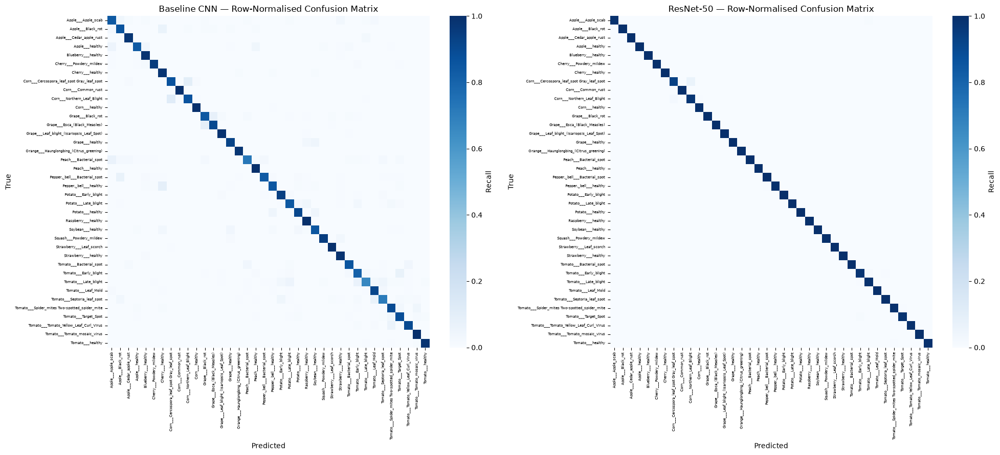


Baseline CNN  |  total errors: 898  |  worst class: Tomato___Late_blight (recall=0.66)
  Top confusions:
    Tomato___Tomato_Yellow_Leaf_Curl_Virus → Tomato___Spider_mites Two-spotted_spider_mite: 48 (0.060)
    Soybean___healthy → Grape___healthy: 27 (0.035)
    Peach___Bacterial_spot → Apple___Apple_scab: 24 (0.070)
    Soybean___healthy → Cherry___healthy: 24 (0.031)
    Soybean___healthy → Potato___healthy: 22 (0.029)

ResNet-50  |  total errors: 24  |  worst class: Corn___Cercospora_leaf_spot Gray_leaf_spot (recall=0.94)
  Top confusions:
    Corn___Cercospora_leaf_spot Gray_leaf_spot → Corn___Northern_Leaf_Blight: 5 (0.065)
    Corn___Northern_Leaf_Blight → Corn___Cercospora_leaf_spot Gray_leaf_spot: 3 (0.020)
    Tomato___Late_blight → Tomato___Early_blight: 2 (0.007)
    Tomato___Target_Spot → Tomato___Early_blight: 2 (0.009)
    Tomato___Early_blight → Tomato___Late_blight: 2 (0.013)


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

for ax, (name, preds) in zip(axes, [('Baseline CNN', test_preds['Baseline CNN']),
                                     ('ResNet-50',    test_preds['ResNet-50'])]):
    cm = confusion_matrix(test_labels, preds)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    sns.heatmap(cm_norm, ax=ax, vmin=0, vmax=1, cmap='Blues',
                xticklabels=filtered_classes, yticklabels=filtered_classes,
                cbar_kws={'label': 'Recall'})
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'{name} — Row-Normalised Confusion Matrix')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=5)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=5)

plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

for name in ['Baseline CNN', 'ResNet-50']:
    cm = confusion_matrix(test_labels, test_preds[name])
    total_errors = cm.sum() - np.trace(cm)
    worst_row = np.argmin(cm.diagonal() / cm.sum(axis=1))
    print(f'\n{name}  |  total errors: {int(total_errors)}  |  '
          f'worst class: {filtered_classes[worst_row]} '
          f'(recall={cm[worst_row, worst_row]/cm[worst_row].sum():.2f})')

    off = cm.copy()
    np.fill_diagonal(off, 0)
    top5 = np.argsort(off, axis=None)[::-1][:5]
    print(f'  Top confusions:')
    for idx in top5:
        i, j = np.unravel_index(idx, off.shape)
        count = off[i, j]
        if count == 0:
            break
        rate = count / cm[i].sum()
        print(f'    {filtered_classes[i]} → {filtered_classes[j]}: '
              f'{count} ({rate:.3f})')

## Error analysis — look-alike diseases

In [36]:
for name in ['Baseline CNN', 'ResNet-50']:
    cm = confusion_matrix(test_labels, test_preds[name])
    off = cm.copy()
    np.fill_diagonal(off, 0)

    same_crop, diff_crop = 0, 0
    expected_same = 0.0
    for i in range(num_classes):
        sp_i = filtered_classes[i].split('___')[0]
        same_crop_count = sum(1 for j in range(num_classes)
                              if j != i and filtered_classes[j].split('___')[0] == sp_i)
        row_errors = off[i].sum()
        expected_same += row_errors * (same_crop_count / (num_classes - 1))

        for j in range(num_classes):
            if i == j or off[i, j] == 0:
                continue
            sp_j = filtered_classes[j].split('___')[0]
            if sp_i == sp_j:
                same_crop += off[i, j]
            else:
                diff_crop += off[i, j]

    total_err = same_crop + diff_crop
    chance_pct = expected_same / total_err * 100
    actual_pct = same_crop / total_err * 100
    print(f'{name:14s}  same-crop errors: {same_crop}/{total_err} '
          f'({actual_pct:.0f}%, chance={chance_pct:.0f}%)  '
          f'cross-crop errors: {diff_crop}/{total_err} '
          f'({diff_crop/total_err*100:.0f}%)')

Baseline CNN    same-crop errors: 349/898 (39%, chance=13%)  cross-crop errors: 549/898 (61%)
ResNet-50       same-crop errors: 21/24 (88%, chance=16%)  cross-crop errors: 3/24 (12%)


## Error analysis — imbalance correlation

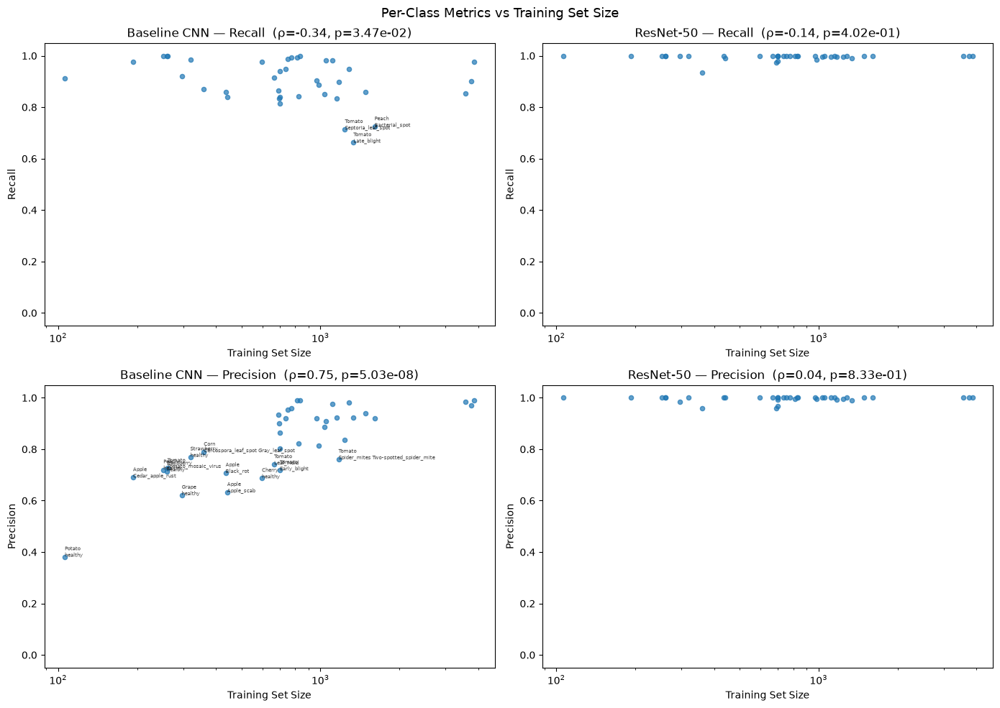


Hypothesis 3 — Background shortcuts:
  Cannot be tested from predictions alone.
  Grad-CAM will check whether attention lands on the leaf
  or spreads to the background. PlantDoc cross-domain eval provides
  supporting evidence but cannot isolate the background factor from
  other domain shifts (lighting, scale, leaf count).


In [37]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Per-Class Metrics vs Training Set Size', fontsize=13)

for col, name in enumerate(['Baseline CNN', 'ResNet-50']):
    cm = confusion_matrix(test_labels, test_preds[name])
    recalls = cm.diagonal() / cm.sum(axis=1)
    precisions = np.array([cm[i, i] / cm[:, i].sum() if cm[:, i].sum() > 0 else 0.0
                           for i in range(num_classes)])
    train_sizes = np.array([cls_counts.get(c, 0) for c in range(num_classes)])

    for row, (metric, metric_name) in enumerate([(recalls, 'Recall'),
                                                  (precisions, 'Precision')]):
        ax = axes[row, col]
        rho, pval = spearmanr(train_sizes, metric)

        ax.scatter(train_sizes, metric, s=20, alpha=0.7)
        ax.set_xlabel('Training Set Size')
        ax.set_ylabel(metric_name)
        ax.set_title(f'{name} — {metric_name}  (ρ={rho:.2f}, p={pval:.2e})')
        ax.set_ylim(-0.05, 1.05)
        ax.set_xscale('log')

        for i in range(num_classes):
            if metric[i] < 0.8:
                ax.annotate(filtered_classes[i].replace('___', '\n'),
                            (train_sizes[i], metric[i]),
                            fontsize=5, alpha=0.7)

plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/recall_precision_vs_size.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nHypothesis 3 — Background shortcuts:')
print('  Cannot be tested from predictions alone.')
print('  Grad-CAM will check whether attention lands on the leaf')
print('  or spreads to the background. PlantDoc cross-domain eval provides')
print('  supporting evidence but cannot isolate the background factor from')
print('  other domain shifts (lighting, scale, leaf count).')

# Universal Adversarial Patches

## Patch Utilities

In [38]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
PATCH_FRACTIONS = [0.05, 0.10, 0.15]

def patch_side(frac):
    return int(round((frac * 224 ** 2) ** 0.5))

def random_locs(n, side, gen):
    rows = torch.randint(0, 224 - side + 1, (n,), generator=gen)
    cols = torch.randint(0, 224 - side + 1, (n,), generator=gen)
    return list(zip(rows.tolist(), cols.tolist()))

def apply_patch(imgs, patch, locs):
    mean = IMAGENET_MEAN.to(patch.device)
    std  = IMAGENET_STD.to(patch.device)
    norm_patch = (patch - mean) / std
    out = imgs.clone()
    s = patch.shape[-1]
    for i, (r, c) in enumerate(locs):
        out[i, :, r:r+s, c:c+s] = norm_patch
    return out

for frac in PATCH_FRACTIONS:
    s = patch_side(frac)
    actual = s * s / (224 * 224) * 100
    print(f'{frac*100:.0f}% patch -> {s}x{s} px ({actual:.1f}% of image)')

# Gradient check
dummy_patch = torch.rand(3, 50, 50, requires_grad=True)
imgs_batch, _ = next(iter(test_loader))
imgs_batch = imgs_batch.to(device)
dummy_locs = random_locs(imgs_batch.size(0), 50, torch.Generator().manual_seed(SEED))
patched = apply_patch(imgs_batch, dummy_patch.to(device), dummy_locs)
patched.sum().backward()
print(f'\nGradient check: patch.grad is None = {dummy_patch.grad is None}, '
      f'all zeros = {(dummy_patch.grad == 0).all().item() if dummy_patch.grad is not None else "N/A"}')

5% patch -> 50x50 px (5.0% of image)
10% patch -> 71x71 px (10.0% of image)
15% patch -> 87x87 px (15.1% of image)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1097: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



Gradient check: patch.grad is None = False, all zeros = False


## Optimization subset

In [39]:

opt_idx, _ = train_test_split(
    train_idx, train_size=2000,
    stratify=[all_targets[i] for i in train_idx],
    random_state=SEED,
)
opt_sub = RemappedSubset(eval_ds, [keep[i] for i in opt_idx], label_map)
opt_loader = DataLoader(opt_sub, batch_size=32, shuffle=True,
                        num_workers=2, pin_memory=True)
assert set(opt_idx).issubset(set(train_idx)), 'opt indices not in train'
assert set(opt_idx).isdisjoint(set(test_idx)), 'opt indices overlap test'

cls_counts_opt = Counter(all_targets[i] for i in opt_idx)
print(f'Optimization subset: {len(opt_idx)} images, '
      f'{len(cls_counts_opt)}/{num_classes} classes')
print(f'Per-class range: {min(cls_counts_opt.values())}–{max(cls_counts_opt.values())}')

Optimization subset: 2000 images, 38/38 classes
Per-class range: 6–203


## Patch optimization loop

In [40]:

PATCH_EPOCHS = 5
PATCH_LR = 0.05

def train_patch(model, frac):
    torch.manual_seed(SEED)
    s = patch_side(frac)
    gen = torch.Generator().manual_seed(SEED)
    patch = torch.rand(3, s, s, generator=gen).to(device)
    patch.requires_grad_(True)
    optimizer = torch.optim.Adam([patch], lr=PATCH_LR)

    model.eval()
    orig_grad = {n: p.requires_grad for n, p in model.named_parameters()}
    for p in model.parameters():
        p.requires_grad = False

    for epoch in range(1, PATCH_EPOCHS + 1):
        epoch_loss, epoch_n = 0.0, 0
        for imgs, lbls in opt_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            locs = random_locs(imgs.size(0), s, gen)
            patched = apply_patch(imgs, patch, locs)
            probs = F.softmax(model(patched), dim=1)
            loss = probs.gather(1, lbls[:, None]).mean()
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            with torch.no_grad():
                patch.clamp_(0, 1)
            epoch_loss += loss.item() * imgs.size(0)
            epoch_n += imgs.size(0)
        print(f'    epoch {epoch}/{PATCH_EPOCHS}  '
              f'mean true-class prob: {epoch_loss / epoch_n:.4f}')

    for n, p in model.named_parameters():
        p.requires_grad = orig_grad[n]
    return patch.detach().cpu()

patches_path = Path(OUTPUT_ROOT) / 'adversarial_patches.pt'
if not FORCE_RECOMPUTE and patches_path.exists():
    patches = torch.load(patches_path, map_location='cpu', weights_only=True)
    print(f'Loaded cached patches from {patches_path}')
    for mname in patches:
        for frac in patches[mname]:
            s = patches[mname][frac].shape[-1]
            print(f'  {mname} {frac*100:.0f}%: {s}x{s}')
else:
    patches = {}
    for mname, model in [('Baseline CNN', baseline_model),
                         ('ResNet-50', resnet_model)]:
        patches[mname] = {}
        for frac in PATCH_FRACTIONS:
            print(f'{mname} — {frac*100:.0f}% patch ({patch_side(frac)}x{patch_side(frac)}):')
            t0 = time.time()
            patches[mname][frac] = train_patch(model, frac)
            print(f'    done in {time.time() - t0:.0f}s')
    torch.save(patches, patches_path)
    print(f'\nSaved 6 patches to {patches_path}')

Loaded cached patches from outputs/adversarial_patches.pt
  Baseline CNN 5%: 50x50
  Baseline CNN 10%: 71x71
  Baseline CNN 15%: 87x87
  ResNet-50 5%: 50x50
  ResNet-50 10%: 71x71
  ResNet-50 15%: 87x87


## Visualize patches

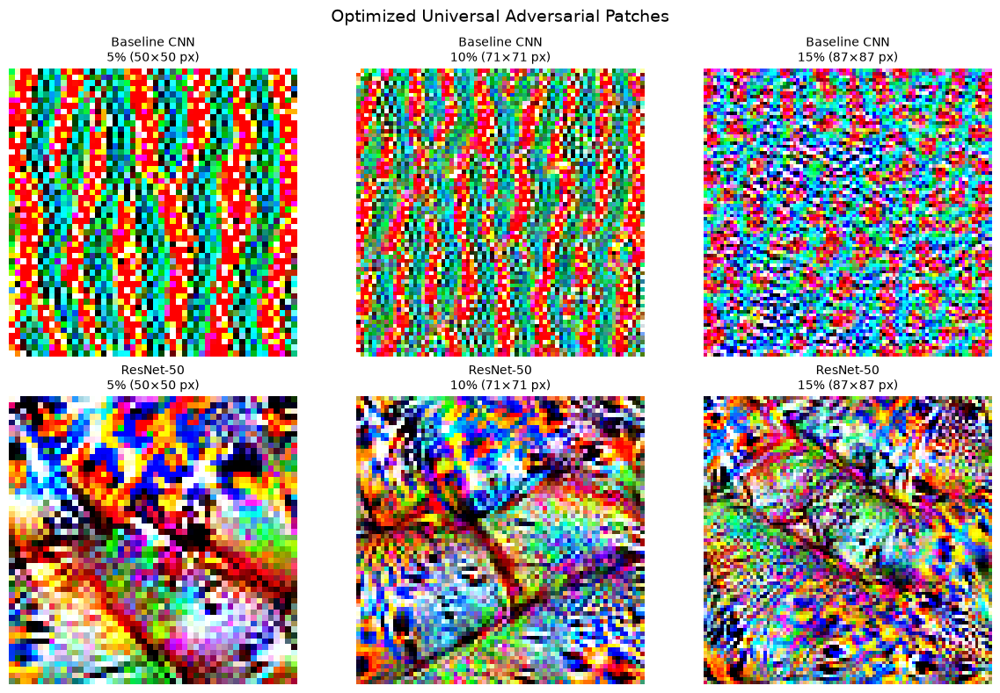

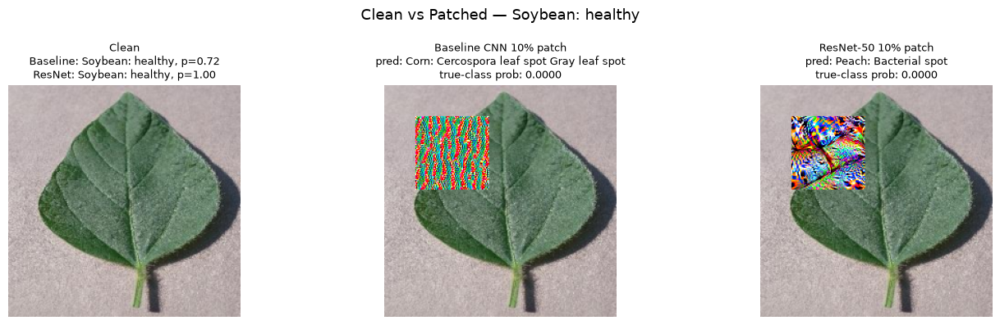

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
fig.suptitle('Optimized Universal Adversarial Patches', fontsize=14)
for row, mname in enumerate(['Baseline CNN', 'ResNet-50']):
    for col, frac in enumerate(PATCH_FRACTIONS):
        p = patches[mname][frac]
        s = p.shape[-1]
        axes[row, col].imshow(p.permute(1, 2, 0).numpy())
        axes[row, col].set_title(f'{mname}\n{frac*100:.0f}% ({s}×{s} px)', fontsize=10)
        axes[row, col].axis('off')
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage2_patches.png', dpi=150, bbox_inches='tight')
plt.show()

def unnormalize(img):
    return (img.cpu() * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1)

def show_img(ax, tensor, title):
    ax.imshow(tensor.permute(1, 2, 0).numpy())
    ax.set_title(title, fontsize=9)
    ax.axis('off')

# ---------------    
# Example Figure    
both_correct = (test_preds['Baseline CNN'] == test_labels) & \
               (test_preds['ResNet-50'] == test_labels)
first_ok = both_correct.nonzero(as_tuple=True)[0][0].item()
sample_img, sample_lbl = test_sub[first_ok]
sample_img = sample_img.to(device)
fix_loc = [(30, 30)]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
true_name = filtered_classes[sample_lbl].replace('___', ': ').replace('_', ' ')
fig.suptitle(f'Clean vs Patched — {true_name}', fontsize=13)

baseline_model.eval()
resnet_model.eval()
with torch.no_grad():
    clean_probs_b = F.softmax(baseline_model(sample_img.unsqueeze(0)), dim=1)
    clean_probs_r = F.softmax(resnet_model(sample_img.unsqueeze(0)), dim=1)

pred_b = filtered_classes[clean_probs_b.argmax(1).item()].replace('___', ': ').replace('_', ' ')
pred_r = filtered_classes[clean_probs_r.argmax(1).item()].replace('___', ': ').replace('_', ' ')
show_img(axes[0], unnormalize(sample_img),
         f'Clean\nBaseline: {pred_b}, p={clean_probs_b[0, sample_lbl]:.2f}\n'
         f'ResNet: {pred_r}, p={clean_probs_r[0, sample_lbl]:.2f}')

for ax, mname, model in zip(axes[1:],
                             ['Baseline CNN', 'ResNet-50'],
                             [baseline_model, resnet_model]):
    p = patches[mname][0.10].to(device)
    patched = apply_patch(sample_img.unsqueeze(0), p, fix_loc)
    with torch.no_grad():
        probs = F.softmax(model(patched), dim=1)
    pred = filtered_classes[probs.argmax(1).item()].replace('___', ': ').replace('_', ' ')
    true_prob = probs[0, sample_lbl].item()
    show_img(ax, unnormalize(patched.squeeze(0)),
             f'{mname} 10% patch\npred: {pred}\n'
             f'true-class prob: {true_prob:.4f}')

plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage2_patch_example.png', dpi=150, bbox_inches='tight')
plt.show()

## Patch attack on the test set

In [42]:
def predict_patched(model, patch, locs):
    model.eval()
    all_probs = []
    start = 0
    patch_d = patch.to(device)
    with torch.no_grad():
        for imgs, _ in test_loader:
            b = imgs.size(0)
            imgs = imgs.to(device)
            batch_locs = locs[start:start + b]
            patched = apply_patch(imgs, patch_d, batch_locs)
            probs = F.softmax(model(patched), dim=1).cpu()
            all_probs.append(probs)
            start += b
    return torch.cat(all_probs)

def attack_metrics(clean_probs, att_probs, y):
    clean_preds = clean_probs.argmax(dim=1)
    att_preds = att_probs.argmax(dim=1)
    ok = (clean_preds == y)
    flipped = ok & (att_preds != y)
    asr = flipped.float().sum() / ok.float().sum()
    clean_true = clean_probs.gather(1, y[:, None]).squeeze(1)
    att_true = att_probs.gather(1, y[:, None]).squeeze(1)
    conf_drop = (clean_true[ok] - att_true[ok]).mean()
    patched_acc = (att_preds == y).float().mean()
    return {
        'patched_acc': patched_acc.item(),
        'asr': asr.item(),
        'conf_drop': conf_drop.item(),
    }

test_locs = {}
noise_patches = {}
for frac in PATCH_FRACTIONS:
    s = patch_side(frac)
    loc_gen = torch.Generator().manual_seed(SEED + 1)
    test_locs[frac] = random_locs(len(test_labels), s, loc_gen)
    noise_gen = torch.Generator().manual_seed(SEED + 2)
    noise_patches[frac] = torch.rand(3, s, s, generator=noise_gen)

attack_path = Path(OUTPUT_ROOT) / 'attack_probs.pt'
if not FORCE_RECOMPUTE and attack_path.exists():
    attack_cache = torch.load(attack_path, map_location='cpu', weights_only=True)
    print(f'Loaded cached attack results from {attack_path}')
else:
    attack_cache = {}
    for mname, model in [('Baseline CNN', baseline_model),
                         ('ResNet-50', resnet_model)]:
        attack_cache[mname] = {}
        for frac in PATCH_FRACTIONS:
            print(f'{mname} — {frac*100:.0f}% adversarial...', end=' ')
            t0 = time.time()
            adv_probs = predict_patched(model, patches[mname][frac], test_locs[frac])
            print(f'{time.time() - t0:.0f}s', end='  |  ')
            print(f'noise...', end=' ')
            t0 = time.time()
            noise_probs = predict_patched(model, noise_patches[frac], test_locs[frac])
            print(f'{time.time() - t0:.0f}s')
            attack_cache[mname][frac] = {
                'adv_probs': adv_probs,
                'noise_probs': noise_probs,
            }
    torch.save(attack_cache, attack_path)
    print(f'\nSaved attack results to {attack_path}')

rows = []
for mname in ['Baseline CNN', 'ResNet-50']:
    clean_probs = test_probs[mname]
    clean_acc = (clean_probs.argmax(1) == test_labels).float().mean().item()
    for frac in PATCH_FRACTIONS:
        adv = attack_metrics(clean_probs,
                             attack_cache[mname][frac]['adv_probs'],
                             test_labels)
        noi = attack_metrics(clean_probs,
                             attack_cache[mname][frac]['noise_probs'],
                             test_labels)
        rows.append({
            'Model': mname,
            'Patch Frac': frac,
            'Clean Acc': round(clean_acc, 4),
            'Patched Acc': round(adv['patched_acc'], 4),
            'ASR': round(adv['asr'], 4),
            'Conf Drop': round(adv['conf_drop'], 4),
            'Noise ASR': round(noi['asr'], 4),
            'Noise Conf Drop': round(noi['conf_drop'], 4),
        })

results_df = pd.DataFrame(rows)
results_df.to_csv(f'{OUTPUT_ROOT}/attack_results.csv', index=False)

display_df = results_df.copy()
display_df['Patch Frac'] = display_df['Patch Frac'].apply(lambda x: f'{x*100:.0f}%')
for col in ['Clean Acc', 'Patched Acc', 'ASR', 'Conf Drop', 'Noise ASR', 'Noise Conf Drop']:
    display_df[col] = display_df[col].apply(lambda x: f'{x:.4f}')
print(display_df.to_string(index=False))
print(f'\nSaved to {OUTPUT_ROOT}/attack_results.csv')

Loaded cached attack results from outputs/attack_probs.pt
       Model Patch Frac Clean Acc Patched Acc    ASR Conf Drop Noise ASR Noise Conf Drop
Baseline CNN         5%    0.8898      0.0128 0.9870    0.8041    0.1213          0.1012
Baseline CNN        10%    0.8898      0.0095 0.9908    0.8106    0.3980          0.3115
Baseline CNN        15%    0.8898      0.0259 0.9739    0.7940    0.5890          0.4688
   ResNet-50         5%    0.9971      0.2929 0.7062    0.6990    0.0011          0.0016
   ResNet-50        10%    0.9971      0.0857 0.9141    0.9086    0.0032          0.0048
   ResNet-50        15%    0.9971      0.0575 0.9424    0.9389    0.0078          0.0115

Saved to outputs/attack_results.csv


## ASR and confidence-drop plots

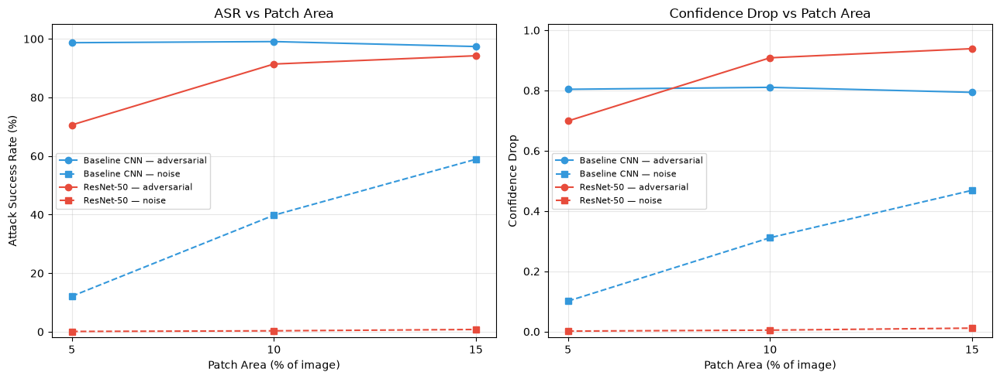

Saved to outputs/stage2_asr_vs_size.png

10% patch — images still correct after patching: 67
  Corn: Cercospora leaf spot Gray leaf spot: 67

15% patch — images still correct after patching: 189
  Grape: Esca (Black Measles): 187
  Corn: Cercospora leaf spot Gray leaf spot: 2


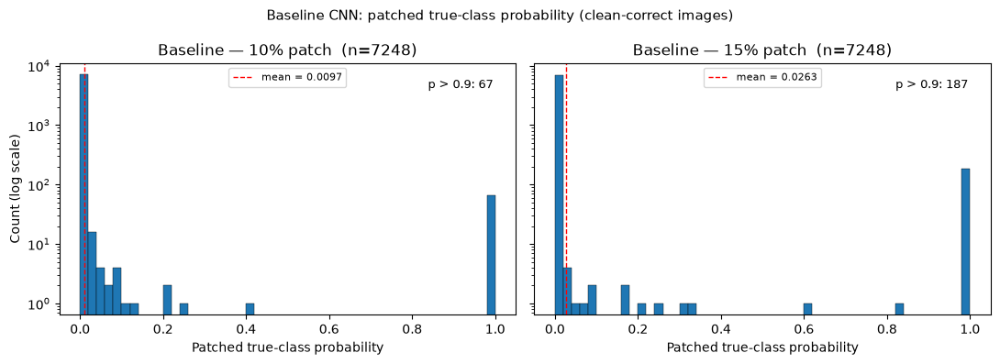


Saved to outputs/stage2_baseline_15pct_check.png


In [43]:
from collections import Counter

MODEL_COLORS = {'Baseline CNN': '#3498db', 'ResNet-50': '#e74c3c'}
fracs_pct = [f * 100 for f in PATCH_FRACTIONS]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for mname in ['Baseline CNN', 'ResNet-50']:
    df_m = results_df[results_df['Model'] == mname]
    c = MODEL_COLORS[mname]
    ax1.plot(df_m['Patch Frac'] * 100, df_m['ASR'] * 100,
             '-o', color=c, label=f'{mname} — adversarial')
    ax1.plot(df_m['Patch Frac'] * 100, df_m['Noise ASR'] * 100,
             '--s', color=c, label=f'{mname} — noise')
    ax2.plot(df_m['Patch Frac'] * 100, df_m['Conf Drop'],
             '-o', color=c, label=f'{mname} — adversarial')
    ax2.plot(df_m['Patch Frac'] * 100, df_m['Noise Conf Drop'],
             '--s', color=c, label=f'{mname} — noise')

for ax, ylabel, title in [
    (ax1, 'Attack Success Rate (%)', 'ASR vs Patch Area'),
    (ax2, 'Confidence Drop',        'Confidence Drop vs Patch Area'),
]:
    ax.set_xlabel('Patch Area (% of image)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(fracs_pct)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
ax1.set_ylim(-2, 105)
ax2.set_ylim(-0.02, 1.02)

plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage2_asr_vs_size.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {OUTPUT_ROOT}/stage2_asr_vs_size.png')

# Baseline 10% vs 15% probability histograms
clean_probs_b = test_probs['Baseline CNN']
clean_preds_b = test_preds['Baseline CNN']
ok_b = (clean_preds_b == test_labels)

fig2, (ax_10, ax_15) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, frac, tag in [(ax_10, 0.10, '10%'), (ax_15, 0.15, '15%')]:
    adv_probs = attack_cache['Baseline CNN'][frac]['adv_probs']
    adv_preds = adv_probs.argmax(dim=1)
    true_p = adv_probs.gather(1, test_labels[:, None]).squeeze(1)
    true_p_ok = true_p[ok_b].numpy()
    ax.hist(true_p_ok, bins=50, range=(0, 1), log=True,
            edgecolor='black', linewidth=0.3)
    ax.set_xlabel('Patched true-class probability')
    ax.set_title(f'Baseline — {tag} patch  (n={ok_b.sum().item()})')
    ax.axvline(true_p_ok.mean(), color='red', linestyle='--', linewidth=1,
               label=f'mean = {true_p_ok.mean():.4f}')
    near_one = (true_p_ok > 0.9).sum()
    ax.annotate(f'p > 0.9: {near_one}', xy=(0.95, 0.90),
                xycoords='axes fraction', fontsize=9, ha='right')
    ax.legend(fontsize=8)
    still_correct = ok_b & (adv_preds == test_labels)
    cls_counts = Counter(test_labels[still_correct].numpy().tolist())
    top_classes = cls_counts.most_common(5)
    print(f'\n{tag} patch — images still correct after patching: {still_correct.sum().item()}')
    for cls_idx, cnt in top_classes:
        cname = filtered_classes[cls_idx].replace('___', ': ').replace('_', ' ')
        print(f'  {cname}: {cnt}')
ax_10.set_ylabel('Count (log scale)')
fig2.suptitle('Baseline CNN: patched true-class probability (clean-correct images)',
              fontsize=11)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage2_baseline_15pct_check.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'\nSaved to {OUTPUT_ROOT}/stage2_baseline_15pct_check.png')

## Attractor classes

In [44]:
from collections import Counter

rows_att = []
for mname in ['Baseline CNN', 'ResNet-50']:
    clean_preds = test_preds[mname]
    ok = (clean_preds == test_labels)
    n_ok = ok.sum().item()
    for frac in PATCH_FRACTIONS:
        adv_probs = attack_cache[mname][frac]['adv_probs']
        adv_preds = adv_probs.argmax(dim=1)
        flipped = ok & (adv_preds != test_labels)
        n_flipped = flipped.sum().item()
        if n_flipped == 0:
            continue
        counts = Counter(adv_preds[flipped].numpy().tolist())
        top_cls, top_cnt = counts.most_common(1)[0]
        top_name = filtered_classes[top_cls].replace('___', ': ').replace('_', ' ')
        share = top_cnt / n_flipped
        attractor_ok = ok & (test_labels == top_cls)
        n_attractor_ok = attractor_ok.sum().item()
        asr_ceiling = 1.0 - n_attractor_ok / n_ok
        actual_asr = n_flipped / n_ok
        rows_att.append({
            'Model': mname,
            'Patch': f'{frac*100:.0f}%',
            'Flipped': n_flipped,
            'Top target class': top_name,
            'Share of flips': round(share, 4),
            'Attractor clean-correct': n_attractor_ok,
            'ASR ceiling': round(asr_ceiling, 4),
            'Actual ASR': round(actual_asr, 4),
        })
        print(f'{mname} {frac*100:.0f}%: {n_flipped} flipped → '
              f'{top_name} ({top_cnt}/{n_flipped}, {share:.1%})')
        runner_up = counts.most_common(3)
        if len(runner_up) > 1:
            for cls_idx, cnt in runner_up[1:]:
                rname = filtered_classes[cls_idx].replace('___', ': ').replace('_', ' ')
                print(f'    runner-up: {rname} ({cnt})')

att_df = pd.DataFrame(rows_att)
display_att = att_df.copy()
for col in ['Share of flips', 'ASR ceiling', 'Actual ASR']:
    display_att[col] = display_att[col].apply(lambda x: f'{x:.4f}')
print(f'\n{display_att.to_string(index=False)}')

Baseline CNN 5%: 7154 flipped → Corn: Cercospora leaf spot Gray leaf spot (6279/7154, 87.8%)
    runner-up: Corn: Northern Leaf Blight (518)
    runner-up: Grape: Esca (Black Measles) (293)
Baseline CNN 10%: 7181 flipped → Corn: Cercospora leaf spot Gray leaf spot (7114/7181, 99.1%)
    runner-up: Corn: Northern Leaf Blight (60)
    runner-up: Grape: Esca (Black Measles) (7)
Baseline CNN 15%: 7059 flipped → Grape: Esca (Black Measles) (6939/7059, 98.3%)
    runner-up: Corn: Cercospora leaf spot Gray leaf spot (120)
ResNet-50 5%: 5736 flipped → Peach: Bacterial spot (5710/5736, 99.5%)
    runner-up: Pepper, bell: Bacterial spot (13)
    runner-up: Tomato: Early blight (7)
ResNet-50 10%: 7424 flipped → Peach: Bacterial spot (7424/7424, 100.0%)
ResNet-50 15%: 7654 flipped → Peach: Bacterial spot (7654/7654, 100.0%)

       Model Patch  Flipped                          Top target class Share of flips  Attractor clean-correct ASR ceiling Actual ASR
Baseline CNN    5%     7154 Corn: Cercospo

# GradCAM + Attention Faithfulness

## Grad-CAM Implementation

In [45]:
if 'extractors' in globals():
    for ext in extractors.values(): ext.remove()

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.handle = target_layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inputs, output):
        self.activations = output
        if output.requires_grad:
            output.register_hook(lambda grad: setattr(self, 'gradients', grad))

    def __call__(self, imgs):
        self.model.eval()
        self.model.zero_grad()
        logits = self.model(imgs)
        target = logits.argmax(dim=1)
        logits.gather(1, target[:, None]).sum().backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)       # (B, C, 1, 1)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))  # (B, 1, h, w)
        cam = F.interpolate(cam, size=(224, 224), mode='bilinear', align_corners=False)
        cam = cam.squeeze(1)                                           # (B, 224, 224)
        mins = cam.flatten(1).min(dim=1).values[:, None, None]
        maxs = cam.flatten(1).max(dim=1).values[:, None, None]
        cam = (cam - mins) / (maxs - mins + 1e-8)
        return cam.detach(), logits.detach()

    def remove(self):
        self.handle.remove()

target_layers = {
    'Baseline CNN': baseline_model.features[10],
    'ResNet-50':    resnet_model.layer4[-1],
}
print('Baseline CNN features:', baseline_model.features)
print(f'\nTarget layer index 10 → {baseline_model.features[10]}')
print(f'Index 11 (the pooling) → {baseline_model.features[11]}')

extractors = {name: GradCAM(model, target_layers[name])
              for name, model in [('Baseline CNN', baseline_model),
                                  ('ResNet-50', resnet_model)]}

imgs_check, _ = next(iter(test_loader))
imgs_check = imgs_check[:4].to(device)
for name, extractor in extractors.items():
    cam, logits = extractor(imgs_check)
    print(f'\n{name:14s} feature maps {tuple(extractor.activations.shape)} -> '
          f'CAM {tuple(cam.shape)}, range {cam.min():.2f}-{cam.max():.2f}')

Baseline CNN features: Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (10): ReLU()
  (11): AdaptiveAvgPool2d(output_size=1)
)

Target layer index 10 → ReLU()
Index 11 (the pooling) → AdaptiveAvgPool2d(output_size=1)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1097: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



Baseline CNN   feature maps (4, 128, 56, 56) -> CAM (4, 224, 224), range 0.00-1.00

ResNet-50      feature maps (4, 2048, 7, 7) -> CAM (4, 224, 224), range 0.00-1.00


## Proxy leaf and lesion masks

In [46]:
import cv2
cv2.setNumThreads(0)

def leaf_and_lesion_masks(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    h, s, v = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
    green_mask = ((h >= 25) & (h <= 95) & (s >= 30) & (v >= 35)).astype(np.uint8)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2Lab).astype(np.float32)
    border = np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]])
    border_green = np.concatenate([green_mask[0], green_mask[-1],
                                   green_mask[:, 0], green_mask[:, -1]])
    non_green_border = border[border_green == 0]
    if len(non_green_border) >= 0.25 * len(border):
        bg_lab = np.median(non_green_border, axis=0)
        dist = np.sqrt((lab[:, :, 1] - bg_lab[1]) ** 2 +
                       (lab[:, :, 2] - bg_lab[2]) ** 2)
        leaf = (dist > 14).astype(np.uint8)
    else:
        leaf = green_mask.copy()
    kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    leaf = cv2.morphologyEx(leaf, cv2.MORPH_OPEN, kernel_open)
    n_comp, labels_cc, comp_stats, _ = cv2.connectedComponentsWithStats(leaf)
    if n_comp > 1:
        largest = 1 + comp_stats[1:, cv2.CC_STAT_AREA].argmax()
        leaf = (labels_cc == largest).astype(np.uint8)
    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    leaf = cv2.morphologyEx(leaf, cv2.MORPH_CLOSE, kernel_close)
    contours, _ = cv2.findContours(leaf, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(leaf, contours, -1, 1, thickness=cv2.FILLED)
    leaf_bool = leaf.astype(bool)
    discolored = (h < 27) | (h > 95)
    powdery = (s < 35) & (v > 170)
    lesion = leaf_bool & (discolored | powdery)
    kernel_les = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    lesion = cv2.morphologyEx(lesion.astype(np.uint8), cv2.MORPH_OPEN, kernel_les)
    return leaf_bool, lesion.astype(bool)

class MaskedTestDataset(torch.utils.data.Dataset):
    def __init__(self, indices, transform):
        self.ds_indices = [keep[i] for i in indices]
        self.transform = transform

    def __len__(self):
        return len(self.ds_indices)

    def __getitem__(self, idx):
        path, old_label = full_ds.samples[self.ds_indices[idx]]
        label = label_map[old_label]
        img = Image.open(path).convert('RGB')
        small = img.resize((224, 224), Image.BILINEAR)
        leaf, lesion = leaf_and_lesion_masks(np.array(small))
        tensor = self.transform(img)
        return tensor, label, torch.tensor(leaf), torch.tensor(lesion), idx

mask_ds = MaskedTestDataset(test_idx, eval_transform)
mask_loader = DataLoader(mask_ds, batch_size=32, shuffle=False,
                         num_workers=2, pin_memory=(device.type == 'cuda'))
assert len(mask_ds) == len(test_labels), f'{len(mask_ds)} != {len(test_labels)}'
assert mask_ds[0][1] == test_labels[0].item(), 'label mismatch at position 0'
print(f'MaskedTestDataset: {len(mask_ds)} images')
img0, lbl0, leaf0, les0, pos0 = mask_ds[0]
print(f'Image 0: img {tuple(img0.shape)}, leaf {leaf0.shape} '
      f'({leaf0.sum().item() / leaf0.numel() * 100:.1f}% leaf), '
      f'lesion {les0.shape} ({les0.sum().item() / les0.numel() * 100:.1f}% lesion)')

MaskedTestDataset: 8146 images
Image 0: img (3, 224, 224), leaf torch.Size([224, 224]) (37.6% leaf), lesion torch.Size([224, 224]) (0.4% lesion)


## Visual check of proxy masks

/var/folders/5d/zrcrg1452cd5g2vgpycwrh_r0000gn/T/ipykernel_40863/3940155432.py:16: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  rgb = tensor.permute(1, 2, 0).numpy() * np.array(IMAGENET_STD.squeeze()) + np.array(IMAGENET_MEAN.squeeze())


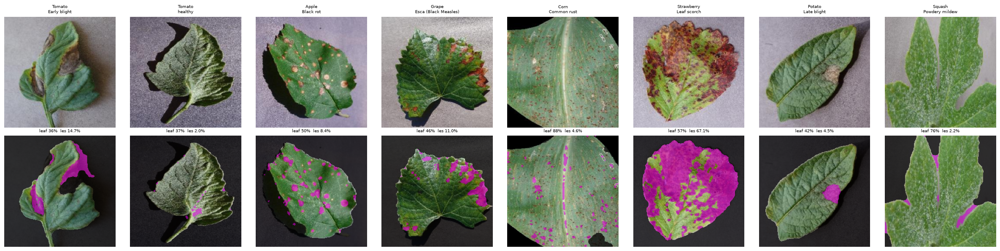

Saved to outputs/stage3_proxy_masks.png
Leaf mask < 10% coverage: 51 / 8146 (0.6%)


In [47]:
check_classes = [
    'Tomato___Early_blight', 'Tomato___healthy',
    'Apple___Black_rot', 'Grape___Esca_(Black_Measles)',
    'Corn___Common_rust', 'Strawberry___Leaf_scorch',
    'Potato___Late_blight', 'Squash___Powdery_mildew',
]
check_ids = []
for cname in check_classes:
    c = filtered_classes.index(cname)
    idx = int(np.where(test_labels.numpy() == c)[0][0])
    check_ids.append(idx)

fig, axes = plt.subplots(2, 8, figsize=(24, 6))
for col, idx in enumerate(check_ids):
    tensor, label, leaf, lesion, _ = mask_ds[idx]
    rgb = tensor.permute(1, 2, 0).numpy() * np.array(IMAGENET_STD.squeeze()) + np.array(IMAGENET_MEAN.squeeze())
    rgb = np.clip(rgb, 0, 1)
    leaf_np, les_np = leaf.numpy(), lesion.numpy()
    leaf_pct = leaf_np.sum() / leaf_np.size * 100
    les_in_leaf = les_np.sum() / max(leaf_np.sum(), 1) * 100
    axes[0, col].imshow(rgb)
    axes[0, col].set_title(check_classes[col].replace('___', '\n').replace('_', ' '), fontsize=7)
    axes[0, col].axis('off')
    overlay = rgb.copy()
    overlay[~leaf_np] *= 0.25
    overlay[les_np] = overlay[les_np] * 0.4 + np.array([0.8, 0.0, 0.8]) * 0.6
    axes[1, col].imshow(overlay)
    axes[1, col].set_title(f'leaf {leaf_pct:.0f}%  les {les_in_leaf:.1f}%', fontsize=7)
    axes[1, col].axis('off')
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage3_proxy_masks.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {OUTPUT_ROOT}/stage3_proxy_masks.png')

low_leaf = 0
for i in range(len(mask_ds)):
    _, _, leaf_i, _, _ = mask_ds[i]
    if leaf_i.sum().item() / leaf_i.numel() < 0.10:
        low_leaf += 1
print(f'Leaf mask < 10% coverage: {low_leaf} / {len(mask_ds)} '
      f'({low_leaf / len(mask_ds) * 100:.1f}%)')

## Attention Metrics

In [48]:
def attention_metrics(cam, leaf, lesion, patch_boxes=None):
    N = cam.shape[1] * cam.shape[2]
    p = cam / (cam.sum(dim=(1, 2), keepdim=True) + 1e-8)
    log_p = torch.log(p + 1e-12)
    entropy = -(p * log_p).sum(dim=(1, 2)) / np.log(N)
    hot = (cam >= 0.5).float()
    hot_area = hot.sum(dim=(1, 2)) / N
    leaf_f = leaf.float()
    leaf_energy = (p * leaf_f).sum(dim=(1, 2))
    leaf_dil = F.max_pool2d(leaf_f[:, None], kernel_size=21,
                            stride=1, padding=10)[:, 0] > 0
    leaf_energy_dil = (p * leaf_dil.float()).sum(dim=(1, 2))
    lesion_f = lesion.float()
    lesion_energy = (p * lesion_f).sum(dim=(1, 2))
    lesion_area = lesion_f.sum(dim=(1, 2)) / N
    lesion_lift = lesion_energy / (lesion_area + 1e-8)
    lesion_iou_inter = (hot * lesion_f).sum(dim=(1, 2))
    lesion_iou_union = ((hot + lesion_f) > 0).float().sum(dim=(1, 2))
    lesion_iou = lesion_iou_inter / (lesion_iou_union + 1e-8)
    lesion_frac = lesion_f.sum(dim=(1, 2)) / (leaf_f.sum(dim=(1, 2)) + 1e-8)
    out = dict(entropy=entropy, hot_area=hot_area,
               leaf_energy=leaf_energy, leaf_energy_dil=leaf_energy_dil,
               lesion_energy=lesion_energy, lesion_lift=lesion_lift,
               lesion_iou=lesion_iou, lesion_frac=lesion_frac)
    if patch_boxes is not None:
        locs, side = patch_boxes
        box = torch.zeros_like(cam)
        for i, (r, c) in enumerate(locs):
            box[i, r:r+side, c:c+side] = 1.0
        out['patch_energy'] = (p * box).sum(dim=(1, 2))
    out = {k: v.cpu().numpy() for k, v in out.items()}
    return out

cam_toy = torch.zeros(1, 224, 224)
cam_toy[0, :50, :50] = 1.0
leaf_toy = torch.ones(1, 224, 224, dtype=torch.bool)
lesion_toy = torch.zeros(1, 224, 224, dtype=torch.bool)
lesion_toy[0, :50, :50] = True
toy_out = attention_metrics(cam_toy, leaf_toy, lesion_toy,
                            patch_boxes=([(0, 0)], 50))
print('Toy check (1s in top-left 50×50, leaf=all, lesion=that square, patch=same):')
for k, v in toy_out.items():
    print(f'  {k:20s} = {v[0]:.4f}')
print(f'\nExpected entropy = log(2500)/log(50176) = {np.log(2500)/np.log(50176):.4f}')
print(f'Expected hot_area = 2500/50176 = {2500/50176:.4f}')
print(f'Expected lesion_lift = 1/(2500/50176) = {50176/2500:.2f}')

Toy check (1s in top-left 50×50, leaf=all, lesion=that square, patch=same):
  entropy              = 0.7229
  hot_area             = 0.0498
  leaf_energy          = 1.0000
  leaf_energy_dil      = 1.0000
  lesion_energy        = 1.0000
  lesion_lift          = 20.0704
  lesion_iou           = 1.0000
  lesion_frac          = 0.0498
  patch_energy         = 1.0000

Expected entropy = log(2500)/log(50176) = 0.7229
Expected hot_area = 2500/50176 = 0.0498
Expected lesion_lift = 1/(2500/50176) = 20.07


## Full attention pass

In [49]:
COND_PAIRS = [('clean', None)] + [(f'patch_{int(round(f*100))}pct', f) for f in PATCH_FRACTIONS]
csv_path = Path(f'{OUTPUT_ROOT}/stage3_attention_metrics.csv')

if csv_path.exists() and not FORCE_RECOMPUTE:
    attn_df = pd.read_csv(csv_path)
    print(f'Loaded {len(attn_df)} rows from {csv_path}')
else:
    rows = []
    for mname, model in [('Baseline CNN', baseline_model), ('ResNet-50', resnet_model)]:
        ext = extractors[mname]
        for cond, frac in COND_PAIRS:
            if frac is not None:
                side = patch_side(frac)
                patch_dev = patches[mname][frac].to(device)
            t0 = time.time()
            for imgs, lbls, leaf, lesion, idx in mask_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                leaf_d, lesion_d = leaf.to(device), lesion.to(device)
                pb = None
                if frac is not None:
                    batch_locs = [test_locs[frac][i] for i in idx.tolist()]
                    imgs = apply_patch(imgs, patch_dev, batch_locs)
                    pb = (batch_locs, side)
                cam, logits = ext(imgs)
                probs = torch.softmax(logits, dim=1)
                preds = logits.argmax(dim=1)
                true_p = probs.gather(1, lbls[:, None]).squeeze(1)
                m = attention_metrics(cam, leaf_d, lesion_d, patch_boxes=pb)
                lbls_np = lbls.cpu().numpy()
                preds_np = preds.cpu().numpy()
                true_p_np = true_p.cpu().numpy()
                idx_np = idx.numpy()
                for j in range(imgs.shape[0]):
                    row = dict(model=mname, condition=cond,
                               position=idx_np[j],
                               true_label=lbls_np[j],
                               pred_label=preds_np[j],
                               true_prob=true_p_np[j])
                    for k, v in m.items():
                        row[k] = v[j]
                    rows.append(row)
            elapsed = time.time() - t0
            print(f'{mname:14s} {cond:12s}  {elapsed:.0f}s')
    attn_df = pd.DataFrame(rows)
    attn_df.to_csv(csv_path, index=False)
    print(f'Saved {len(attn_df)} rows to {csv_path}')

healthy_classes = {i for i, name in enumerate(filtered_classes) if 'healthy' in name.lower()}
attn_df['diseased'] = ~attn_df['true_label'].isin(healthy_classes)
no_lesion = (~attn_df['diseased']) | (attn_df['lesion_frac'] < 0.01)
for col in ['lesion_iou', 'lesion_energy', 'lesion_lift']:
    attn_df.loc[no_lesion, col] = np.nan
clean_one = attn_df[(attn_df['condition'] == 'clean') & (attn_df['model'] == 'Baseline CNN')]
n_diseased = int(clean_one['diseased'].sum())
usable = int(clean_one['lesion_energy'].notna().sum())
print(f'Rows: {len(attn_df)}  |  Usable lesion masks (clean, per model): {usable} / {n_diseased}')

Loaded 65168 rows from outputs/stage3_attention_metrics.csv
Rows: 65168  |  Usable lesion masks (clean, per model): 3691 / 5883


## Prediction agreement check

In [50]:
clean_df = attn_df[attn_df['condition'] == 'clean']
for mname in ['Baseline CNN', 'ResNet-50']:
    sub = clean_df[clean_df['model'] == mname].sort_values('position')
    s1_preds = test_preds[mname].numpy()
    s3_preds = sub['pred_label'].values
    agree = (s1_preds == s3_preds).mean()
    print(f'{mname} clean: Stage 1 vs 3 agreement = {agree:.4f} '
          f'({(s1_preds == s3_preds).sum()}/{len(s1_preds)})')
    assert agree > 0.995, f'{mname} clean agreement {agree:.4f} < 0.995'

for mname in ['Baseline CNN', 'ResNet-50']:
    for frac in PATCH_FRACTIONS:
        cond = f'patch_{int(frac*100)}pct'
        sub = attn_df[(attn_df['model'] == mname) &
                      (attn_df['condition'] == cond)].sort_values('position')
        s2_preds = attack_cache[mname][frac]['adv_probs'].argmax(dim=1).numpy()
        s3_preds = sub['pred_label'].values
        agree = (s2_preds == s3_preds).mean()
        print(f'{mname} {cond}: Stage 2 vs 3 agreement = {agree:.4f} '
              f'({(s2_preds == s3_preds).sum()}/{len(s2_preds)})')
        assert agree > 0.995, f'{mname} {cond} agreement {agree:.4f} < 0.995'

Baseline CNN clean: Stage 1 vs 3 agreement = 1.0000 (8146/8146)
ResNet-50 clean: Stage 1 vs 3 agreement = 1.0000 (8146/8146)
Baseline CNN patch_5pct: Stage 2 vs 3 agreement = 1.0000 (8146/8146)
Baseline CNN patch_10pct: Stage 2 vs 3 agreement = 1.0000 (8146/8146)
Baseline CNN patch_15pct: Stage 2 vs 3 agreement = 1.0000 (8146/8146)
ResNet-50 patch_5pct: Stage 2 vs 3 agreement = 1.0000 (8146/8146)
ResNet-50 patch_10pct: Stage 2 vs 3 agreement = 1.0000 (8146/8146)
ResNet-50 patch_15pct: Stage 2 vs 3 agreement = 1.0000 (8146/8146)


## Mask quality checks

In [51]:
leaf_frac_csv = Path(f'{OUTPUT_ROOT}/leaf_frac.csv')
if leaf_frac_csv.exists() and not FORCE_RECOMPUTE:
    leaf_frac_df = pd.read_csv(leaf_frac_csv)
    print(f'Loaded {len(leaf_frac_df)} rows from {leaf_frac_csv}')
else:
    lf_rows = []
    for _, _, leaf, _, idx in mask_loader:
        for j in range(leaf.shape[0]):
            lf_rows.append(dict(position=idx[j].item(),
                                leaf_frac=leaf[j].float().mean().item()))
    leaf_frac_df = pd.DataFrame(lf_rows)
    leaf_frac_df.to_csv(leaf_frac_csv, index=False)
    print(f'Saved {len(leaf_frac_df)} rows to {leaf_frac_csv}')
attn_df = attn_df.drop(columns='leaf_frac', errors='ignore')
attn_df = attn_df.merge(leaf_frac_df, on='position', how='left')

failed = leaf_frac_df[leaf_frac_df['leaf_frac'] < 0.10]
print(f'\n(a) Leaf-mask failures (leaf_frac < 0.10): {len(failed)} / {len(leaf_frac_df)}')
if len(failed) > 0:
    failed_labels = test_labels.numpy()[failed['position'].values]
    failed_classes = pd.Series([filtered_classes[l] for l in failed_labels])
    print(failed_classes.value_counts().to_string())

clean_one = attn_df[(attn_df['condition'] == 'clean') & (attn_df['model'] == 'Baseline CNN')]
healthy = clean_one[~clean_one['diseased']]
diseased = clean_one[clean_one['diseased']]
fp_count = int((healthy['lesion_frac'] >= 0.01).sum())
print(f'\n(b) Proxy false positives on healthy leaves:')
print(f'    {fp_count} / {len(healthy)} healthy images have lesion_frac >= 0.01 '
      f'({fp_count/len(healthy)*100:.1f}%)')
print(f'    Mean lesion_frac on healthy:  {healthy["lesion_frac"].mean():.4f}')
print(f'    Mean lesion_frac on diseased: {diseased["lesion_frac"].mean():.4f}')

print(f'\n(c) Leaf energy robustness to mask edge (clean images):')
for mname in ['Baseline CNN', 'ResNet-50']:
    sub = attn_df[(attn_df['condition'] == 'clean') & (attn_df['model'] == mname)]
    le = sub['leaf_energy'].mean()
    led = sub['leaf_energy_dil'].mean()
    print(f'  {mname:14s}  leaf_energy {le:.4f}  leaf_energy_dil {led:.4f}  '
          f'gain {led - le:+.4f}')
    rho, p = spearmanr(sub['leaf_energy'], sub['leaf_energy_dil'])
    print(f'  {" " * 14}  Spearman(leaf_energy, leaf_energy_dil) = {rho:.4f}, p = {p:.2e}')
    clean_good = sub[sub['leaf_frac'] >= 0.10]
    le_g = clean_good['leaf_energy'].mean()
    led_g = clean_good['leaf_energy_dil'].mean()
    print(f'  {" " * 14}  excluding failed masks ({len(clean_good)}/{len(sub)}): '
          f'leaf_energy {le_g:.4f}  leaf_energy_dil {led_g:.4f}')

Loaded 8146 rows from outputs/leaf_frac.csv

(a) Leaf-mask failures (leaf_frac < 0.10): 51 / 8146
Apple___healthy                               17
Tomato___Late_blight                          12
Peach___healthy                                7
Soybean___healthy                              6
Tomato___Early_blight                          3
Corn___healthy                                 2
Cherry___Powdery_mildew                        1
Corn___Cercospora_leaf_spot Gray_leaf_spot     1
Tomato___Tomato_Yellow_Leaf_Curl_Virus         1
Tomato___Septoria_leaf_spot                    1

(b) Proxy false positives on healthy leaves:
    647 / 2263 healthy images have lesion_frac >= 0.01 (28.6%)
    Mean lesion_frac on healthy:  0.0153
    Mean lesion_frac on diseased: 0.0878

(c) Leaf energy robustness to mask edge (clean images):
  Baseline CNN    leaf_energy 0.5901  leaf_energy_dil 0.7070  gain +0.1169
                  Spearman(leaf_energy, leaf_energy_dil) = 0.9787, p = 0.00e+00
         

## Grad-CAM overlays

Chosen positions: [5014 2014 7488 4129]


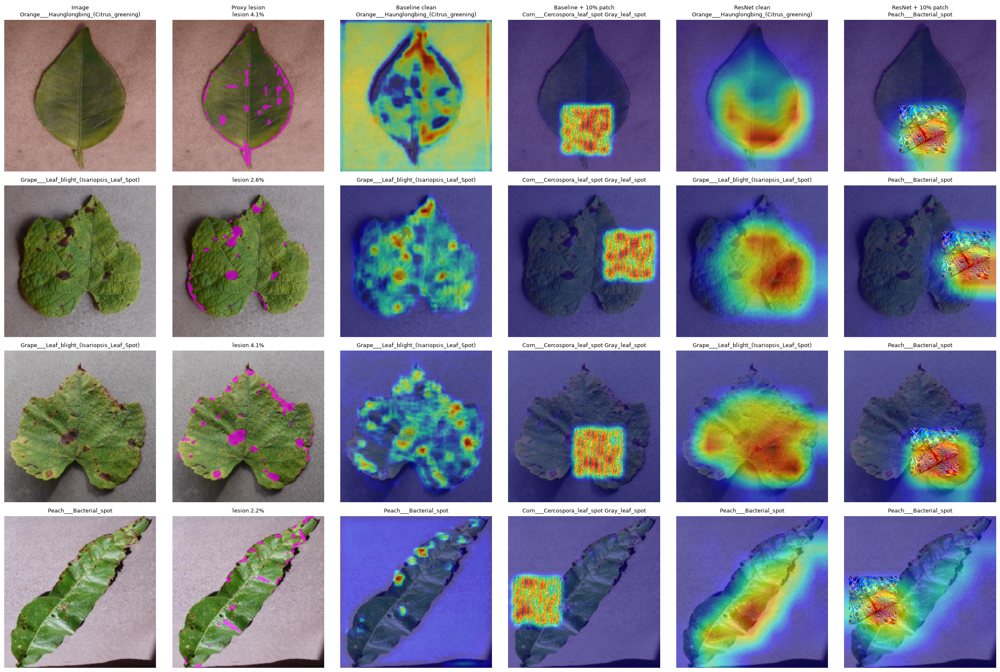

Saved to outputs/stage3_gradcam_overlays.png


In [52]:
clean_both = attn_df[(attn_df['condition'] == 'clean')].pivot_table(
    index='position', columns='model', values='pred_label', aggfunc='first')
tl_np = test_labels.numpy()
both_correct = clean_both.index[
    (clean_both['Baseline CNN'].values == tl_np[clean_both.index.values]) &
    (clean_both['ResNet-50'].values   == tl_np[clean_both.index.values])]
clean_base = attn_df[(attn_df['condition'] == 'clean') & (attn_df['model'] == 'Baseline CNN')]
eligible = clean_base[(clean_base['position'].isin(both_correct)) &
                      (clean_base['diseased']) &
                      (clean_base['lesion_frac'] >= 0.05)]['position'].values
rng_overlay = np.random.RandomState(SEED + 3)
chosen = rng_overlay.choice(eligible, size=4, replace=False)
print(f'Chosen positions: {chosen}')

side_10 = patch_side(0.10)
fig, axes = plt.subplots(4, 6, figsize=(24, 16))
col_titles = ['Image', 'Proxy lesion', 'Baseline clean', 'Baseline + 10% patch',
              'ResNet clean', 'ResNet + 10% patch']
for row, pos in enumerate(chosen):
    img_t, lbl, leaf, lesion, _ = mask_ds[pos]
    img_rgb = unnormalize(img_t).permute(1, 2, 0).numpy()
    lesion_np = lesion.numpy()
    axes[row, 0].imshow(img_rgb)
    axes[row, 0].set_title(filtered_classes[lbl], fontsize=9)
    overlay_les = img_rgb.copy()
    overlay_les[lesion_np > 0] = overlay_les[lesion_np > 0] * 0.4 + np.array([1, 0, 1]) * 0.6
    axes[row, 1].imshow(overlay_les)
    axes[row, 1].set_title(f'lesion {lesion_np.mean()*100:.1f}%', fontsize=9)
    for col_off, (mname, model) in enumerate([('Baseline CNN', baseline_model),
                                               ('ResNet-50', resnet_model)]):
        ext = extractors[mname]
        inp = img_t.unsqueeze(0).to(device)
        cam_clean, logits_clean = ext(inp)
        pred_clean = filtered_classes[logits_clean.argmax(1).item()]
        axes[row, 2 + col_off * 2].imshow(img_rgb)
        axes[row, 2 + col_off * 2].imshow(cam_clean[0].cpu().numpy(),
                                           cmap='jet', alpha=0.5, vmin=0, vmax=1)
        axes[row, 2 + col_off * 2].set_title(pred_clean, fontsize=9)
        loc = test_locs[0.10][pos]
        patched = apply_patch(inp, patches[mname][0.10].to(device), [loc])
        cam_patch, logits_patch = ext(patched)
        pred_patch = filtered_classes[logits_patch.argmax(1).item()]
        axes[row, 3 + col_off * 2].imshow(unnormalize(patched[0]).permute(1, 2, 0).cpu().numpy())
        axes[row, 3 + col_off * 2].imshow(cam_patch[0].cpu().numpy(),
                                           cmap='jet', alpha=0.5, vmin=0, vmax=1)
        axes[row, 3 + col_off * 2].set_title(pred_patch, fontsize=9)
for c, t in enumerate(col_titles):
    axes[0, c].set_title(f'{t}\n{axes[0, c].get_title()}', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage3_gradcam_overlays.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {OUTPUT_ROOT}/stage3_gradcam_overlays.png')

## Attention summary table and figure

                          entropy  hot_area  leaf_energy  leaf_energy_dil  lesion_iou  lesion_energy  lesion_lift  patch_energy
model        condition                                                                                                         
Baseline CNN clean         0.9520    0.1736       0.5901           0.7070      0.1168         0.1321       2.4023           NaN
             patch_10pct   0.8202    0.0897       0.7046           0.8267      0.0439         0.0925       1.4572        0.8541
             patch_15pct   0.8445    0.0762       0.7182           0.8364      0.0412         0.0932       1.4703        0.8714
             patch_5pct    0.7745    0.0431       0.6562           0.7945      0.0284         0.0923       1.5061        0.7931
ResNet-50    clean         0.9486    0.1904       0.7505           0.8812      0.0935         0.1076       1.7820           NaN
             patch_10pct   0.8772    0.0942       0.6844           0.8106      0.0485         0.0891    

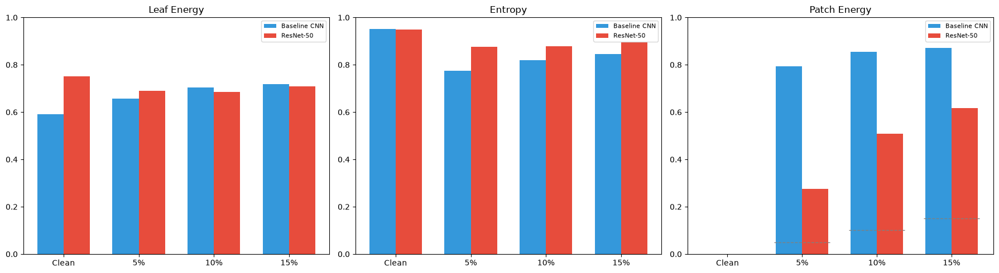

Saved to outputs/stage3_attention_summary.png

Wilcoxon signed-rank (clean leaf_energy, Baseline vs ResNet):
  W = 7023878, p < 1e-300
  median paired diff (ResNet − Baseline) = 0.1133


In [53]:
summary_cols = ['entropy', 'hot_area', 'leaf_energy', 'leaf_energy_dil',
                'lesion_iou', 'lesion_energy', 'lesion_lift', 'patch_energy']
summary = attn_df.groupby(['model', 'condition'])[summary_cols].mean()
summary.to_csv(f'{OUTPUT_ROOT}/stage3_attention_summary.csv')
print(summary.round(4).to_string())

cond_order = ['clean', 'patch_5pct', 'patch_10pct', 'patch_15pct']
cond_labels = ['Clean', '5%', '10%', '15%']
colors = {'Baseline CNN': '#3498db', 'ResNet-50': '#e74c3c'}
bar_w = 0.35

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for panel, metric, title in [(0, 'leaf_energy', 'Leaf Energy'),
                              (1, 'entropy', 'Entropy'),
                              (2, 'patch_energy', 'Patch Energy')]:
    ax = axes[panel]
    x = np.arange(len(cond_order))
    for k, mname in enumerate(['Baseline CNN', 'ResNet-50']):
        vals = [summary.loc[(mname, c), metric] if (mname, c) in summary.index
                else 0 for c in cond_order]
        if metric == 'patch_energy':
            vals[0] = 0
        ax.bar(x + k * bar_w, vals, bar_w, label=mname, color=colors[mname])
    if metric == 'patch_energy':
        for i, frac in enumerate(PATCH_FRACTIONS):
            area = patch_side(frac) ** 2 / 224 ** 2
            xpos = i + 1
            ax.hlines(area, xpos - 0.2, xpos + bar_w + 0.2,
                      colors='gray', linestyles='--', linewidth=1)
    ax.set_xticks(x + bar_w / 2)
    ax.set_xticklabels(cond_labels)
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
axes[2].set_ylabel('')
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage3_attention_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {OUTPUT_ROOT}/stage3_attention_summary.png')

base_le = attn_df[(attn_df['condition'] == 'clean') &
                  (attn_df['model'] == 'Baseline CNN')].sort_values('position')['leaf_energy'].values
res_le  = attn_df[(attn_df['condition'] == 'clean') &
                  (attn_df['model'] == 'ResNet-50')].sort_values('position')['leaf_energy'].values
stat_w, p_w = wilcoxon(base_le, res_le)
p_str = f'p = {p_w:.2e}' if p_w > 0 else 'p < 1e-300'
print(f'\nWilcoxon signed-rank (clean leaf_energy, Baseline vs ResNet):')
print(f'  W = {stat_w:.0f}, {p_str}')
print(f'  median paired diff (ResNet − Baseline) = {np.median(res_le - base_le):.4f}')

## Reproduce annotation candidates

In [54]:
diseased_pos = np.where(~np.isin(test_labels.numpy(), list(healthy_classes)))[0]
diseased_labels = test_labels.numpy()[diseased_pos]
cand_pos, _ = train_test_split(diseased_pos, train_size=150,
                               stratify=diseased_labels,
                               random_state=SEED)
cand_pos = np.sort(cand_pos)

ref_csv = pd.read_csv(f'{OUTPUT_ROOT}/annotation_candidates.csv')
ref_pos = np.sort(ref_csv['test_pos'].values)
assert np.array_equal(cand_pos, ref_pos), \
    f'Mismatch: {len(set(cand_pos) ^ set(ref_pos))} positions differ'
print(f'150 candidates match the CSV exactly')

mask_dir = Path(f'{OUTPUT_ROOT}/lesion_masks')
missing = []
for _, row in ref_csv.iterrows():
    cls = row['class']
    stem = Path(row['path']).stem
    mask_file = mask_dir / f'{cls}__{stem}.png'
    if not mask_file.exists():
        missing.append(mask_file.name)
n_classes = ref_csv['class'].nunique()
print(f'{len(ref_csv)} candidates, {n_classes} classes, '
      f'{"all 150 masks found" if not missing else f"{len(missing)} masks missing"}')
if missing:
    for m in missing[:10]:
        print(f'  MISSING: {m}')

150 candidates match the CSV exactly
150 candidates, 26 classes, all 150 masks found


# Research Question

## Per-image attention–robustness table

In [55]:
rows = []
for mname in ['Baseline CNN', 'ResNet-50']:
    cp = test_probs[mname]                                      
    cl = test_labels                                         
    ok = (cp.argmax(1) == cl)                                 
    clean_tp = cp.gather(1, cl[:, None]).squeeze(1)          
    idx_ok = ok.nonzero(as_tuple=True)[0]                  
    for frac in PATCH_FRACTIONS:
        ap = attack_cache[mname][frac]['adv_probs']             
        adv_tp = ap.gather(1, cl[:, None]).squeeze(1)      
        adv_pred = ap.argmax(1)                           
        flipped_all = (adv_pred[ok] != cl[ok])
        attractor = int(adv_pred[ok][flipped_all].mode().values.item())
        tag = f'patch_{int(round(frac*100))}pct'
        block = pd.DataFrame(dict(
            model=mname, patch_frac=frac, position=idx_ok.numpy(),
            true_label=cl[idx_ok].numpy(),
            clean_prob=clean_tp[idx_ok].numpy(),
            p_patched=adv_tp[idx_ok].numpy(),
            conf_drop=(clean_tp[idx_ok] - adv_tp[idx_ok]).numpy(),
            flipped=(adv_pred[idx_ok] != cl[idx_ok]).int().numpy(),
            is_attractor=(cl[idx_ok] == attractor).int().numpy(),
        ))
        block['rel_drop'] = block['conf_drop'] / block['clean_prob'].clip(lower=1e-8)
        block['attractor_class'] = attractor
        rows.append(block)

img_df = pd.concat(rows, ignore_index=True)
clean_attn_c = attn_df[attn_df['condition'] == 'clean'][
    ['model', 'position', 'entropy', 'hot_area', 'leaf_energy',
     'leaf_energy_dil', 'lesion_iou', 'lesion_energy', 'lesion_lift']
].copy()
img_df = img_df.merge(clean_attn_c, on=['model', 'position'], how='left')
img_df.to_csv(f'{OUTPUT_ROOT}/stage4_per_image.csv', index=False)
print(f'Per-image table: {len(img_df)} rows')
for mname in ['Baseline CNN', 'ResNet-50']:
    sub = img_df[img_df['model'] == mname]
    for frac in PATCH_FRACTIONS:
        s = sub[sub['patch_frac'] == frac]
        na = s[s['is_attractor'] == 0]
        print(f'  {mname} {frac*100:.0f}%: {len(s)} images '
              f'({s["flipped"].sum()} flipped), '
              f'attractor class {s["attractor_class"].iloc[0]} '
              f'({(s["is_attractor"]==1).sum()} imgs), '
              f'excl-attractor: {len(na)} imgs '
              f'({na["flipped"].sum()} flipped), '
              f'mean p_patched {na["p_patched"].mean():.4f}')

Per-image table: 46110 rows
  Baseline CNN 5%: 7248 images (7154 flipped), attractor class 7 (67 imgs), excl-attractor: 7181 imgs (7154 flipped), mean p_patched 0.0070
  Baseline CNN 10%: 7248 images (7181 flipped), attractor class 7 (67 imgs), excl-attractor: 7181 imgs (7181 flipped), mean p_patched 0.0004
  Baseline CNN 15%: 7248 images (7059 flipped), attractor class 12 (187 imgs), excl-attractor: 7061 imgs (7059 flipped), mean p_patched 0.0005
  ResNet-50 5%: 8122 images (5736 flipped), attractor class 16 (344 imgs), excl-attractor: 7778 imgs (5736 flipped), mean p_patched 0.2686
  ResNet-50 10%: 8122 images (7424 flipped), attractor class 16 (344 imgs), excl-attractor: 7778 imgs (7424 flipped), mean p_patched 0.0498
  ResNet-50 15%: 8122 images (7654 flipped), attractor class 16 (344 imgs), excl-attractor: 7778 imgs (7654 flipped), mean p_patched 0.0182


## Per-image correlations

In [56]:
attn_cols  = ['entropy', 'hot_area', 'leaf_energy', 'leaf_energy_dil',
              'lesion_iou', 'lesion_energy', 'lesion_lift']
rob_cols   = ['conf_drop', 'flipped', 'p_patched', 'rel_drop']
scopes     = ['excl_attractor', 'all']
n_tests    = len(attn_cols) * len(rob_cols) * 2 * 3
alpha_bonf = 0.05 / n_tests
print(f'Bonferroni: {n_tests} tests, α = {alpha_bonf:.6f}')

corr_rows = []
for scope in scopes:
    for mname in ['Baseline CNN', 'ResNet-50']:
        for frac in PATCH_FRACTIONS:
            sub = img_df[(img_df['model'] == mname) &
                         (img_df['patch_frac'] == frac)].copy()
            if scope == 'excl_attractor':
                sub = sub[sub['is_attractor'] == 0]
            for acol in attn_cols:
                for rcol in rob_cols:
                    valid = sub[[acol, rcol]].dropna()
                    n = len(valid)
                    if n < 20:
                        continue
                    x, y = valid[acol].values, valid[rcol].values
                    if x.std() == 0 or y.std() == 0:
                        corr_rows.append(dict(
                            scope=scope, model=mname, patch_frac=frac,
                            attention=acol, robustness=rcol, n=n,
                            pearson_r=float('nan'), pearson_p=float('nan'),
                            spearman_rho=float('nan'), spearman_p=float('nan'),
                            pearson_sig=False, spearman_sig=False,
                            note='no variance'))
                        continue
                    rp, pp = pearsonr(x, y)
                    rs, ps = spearmanr(x, y)
                    corr_rows.append(dict(
                        scope=scope, model=mname, patch_frac=frac,
                        attention=acol, robustness=rcol, n=n,
                        pearson_r=rp, pearson_p=pp,
                        spearman_rho=rs, spearman_p=ps,
                        pearson_sig=pp < alpha_bonf,
                        spearman_sig=ps < alpha_bonf,
                        note=''))

corr_df = pd.DataFrame(corr_rows)
corr_df.to_csv(f'{OUTPUT_ROOT}/stage4_correlations.csv', index=False)

main = corr_df[corr_df['scope'] == 'excl_attractor']
sig  = main[main['spearman_sig']]
print(f'\nExcl-attractor correlations: {len(main)} rows, '
      f'{len(sig)} Spearman-significant')
novar = main[main['note'] == 'no variance']
if len(novar):
    print(f'  ({len(novar)} skipped: no variance in y)')

print(f'\nSignificant Spearman (excl-attractor, p < {alpha_bonf:.6f}):')
for _, r in sig.sort_values('spearman_rho').iterrows():
    print(f'  {r["model"]:14s} {r["patch_frac"]*100:5.0f}%  '
          f'{r["attention"]:18s} vs {r["robustness"]:10s}  '
          f'ρ={r["spearman_rho"]:+.4f}  p={r["spearman_p"]:.2e}  n={r["n"]}')

print(f'\nAll excl-attractor Spearman (by attention metric):')
for acol in attn_cols:
    print(f'\n  {acol}:')
    sub = main[main['attention'] == acol]
    for _, r in sub.iterrows():
        star = '*' if r['spearman_sig'] else ' '
        nv   = ' [no var]' if r['note'] == 'no variance' else ''
        print(f'    {r["model"]:14s} {r["patch_frac"]*100:5.0f}%  '
              f'vs {r["robustness"]:10s}  '
              f'ρ={r["spearman_rho"]:+.4f}  p={r["spearman_p"]:.2e} {star}{nv}')

Bonferroni: 168 tests, α = 0.000298

Excl-attractor correlations: 168 rows, 139 Spearman-significant
  (7 skipped: no variance in y)

Significant Spearman (excl-attractor, p < 0.000298):
  Baseline CNN      15%  hot_area           vs p_patched   ρ=-0.5944  p=0.00e+00  n=7061
  Baseline CNN      15%  lesion_energy      vs rel_drop    ρ=-0.4016  p=3.79e-117  n=3013
  Baseline CNN       5%  lesion_energy      vs rel_drop    ρ=-0.3764  p=5.21e-106  n=3133
  Baseline CNN       5%  lesion_lift        vs rel_drop    ρ=-0.3706  p=1.46e-102  n=3133
  Baseline CNN      15%  entropy            vs p_patched   ρ=-0.3500  p=1.25e-202  n=7061
  Baseline CNN      10%  hot_area           vs p_patched   ρ=-0.3452  p=4.93e-200  n=7181
  Baseline CNN      10%  entropy            vs p_patched   ρ=-0.3346  p=2.38e-187  n=7181
  Baseline CNN       5%  lesion_iou         vs rel_drop    ρ=-0.3300  p=1.66e-80  n=3133
  Baseline CNN       5%  entropy            vs p_patched   ρ=-0.3196  p=3.16e-170  n=7181
  Bas

## Lesion-size confound check

In [57]:
clean_lf = attn_df[attn_df['condition'] == 'clean'][
    ['model', 'position', 'lesion_frac']].copy()
img_df = img_df.drop(columns='lesion_frac', errors='ignore')
img_df = img_df.merge(clean_lf, on=['model', 'position'], how='left')

CONFOUND_FRAC = 0.10
conf_metrics = ['lesion_energy', 'lesion_lift']

print('Lesion-size confound check (10% patch, excl attractor, diseased only)\n')
for mname in ['Baseline CNN', 'ResNet-50']:
    sub = img_df[(img_df['model'] == mname) &
                 (img_df['patch_frac'] == CONFOUND_FRAC) &
                 (img_df['is_attractor'] == 0) &
                 (img_df['lesion_frac'].notna()) &
                 (img_df['lesion_energy'].notna())].copy()
    rs_le_lf, ps_le_lf = spearmanr(sub['lesion_energy'], sub['lesion_frac'])
    rs_lf_pp, ps_lf_pp = spearmanr(sub['lesion_frac'], sub['p_patched'])
    print(f'{mname} (n={len(sub)}):')
    print(f'  ρ(lesion_energy, lesion_frac) = {rs_le_lf:+.4f}  p={ps_le_lf:.2e}')
    print(f'  ρ(lesion_frac,   p_patched)   = {rs_lf_pp:+.4f}  p={ps_lf_pp:.2e}')

    sub['size_tercile'] = pd.qcut(sub['lesion_frac'], 3, labels=['small','medium','large'],
                                  duplicates='drop')
    print(f'  Within-tercile correlations with p_patched:')
    for t in ['small', 'medium', 'large']:
        ts = sub[sub['size_tercile'] == t]
        if len(ts) < 20:
            print(f'    {t}: n={len(ts)}, skipped (< 20)')
            continue
        for acol in conf_metrics:
            valid = ts[[acol, 'p_patched']].dropna()
            if len(valid) < 20 or valid[acol].std() == 0:
                print(f'    {t}: {acol} n={len(valid)}, skipped')
                continue
            rs, ps = spearmanr(valid[acol], valid['p_patched'])
            print(f'    {t}: {acol:18s} vs p_patched  '
                  f'ρ={rs:+.4f}  p={ps:.2e}  n={len(valid)}')
    print()

Lesion-size confound check (10% patch, excl attractor, diseased only)

Baseline CNN (n=3133):
  ρ(lesion_energy, lesion_frac) = +0.8183  p=0.00e+00
  ρ(lesion_frac,   p_patched)   = +0.2596  p=1.98e-49
  Within-tercile correlations with p_patched:
    small: lesion_energy      vs p_patched  ρ=+0.5034  p=3.08e-68  n=1045
    small: lesion_lift        vs p_patched  ρ=+0.4606  p=5.20e-56  n=1045
    medium: lesion_energy      vs p_patched  ρ=+0.4844  p=1.56e-62  n=1044
    medium: lesion_lift        vs p_patched  ρ=+0.3924  p=9.15e-40  n=1044
    large: lesion_energy      vs p_patched  ρ=+0.2500  p=2.45e-16  n=1044
    large: lesion_lift        vs p_patched  ρ=+0.0428  p=1.67e-01  n=1044

ResNet-50 (n=3371):
  ρ(lesion_energy, lesion_frac) = +0.9293  p=0.00e+00
  ρ(lesion_frac,   p_patched)   = +0.2388  p=6.51e-45
  Within-tercile correlations with p_patched:
    small: lesion_energy      vs p_patched  ρ=+0.0425  p=1.54e-01  n=1124
    small: lesion_lift        vs p_patched  ρ=-0.0849  p=


## Log-softmax robustness check

In [58]:
frac = 0.10
mname = 'Baseline CNN'

# --- one pass with log_softmax instead of softmax ---
baseline_model.eval()
all_logp = []
start = 0
patch_d = patches[mname][frac].to(device)
with torch.no_grad():
    for imgs, _ in test_loader:
        b = imgs.size(0)
        imgs = imgs.to(device)
        batch_locs = test_locs[frac][start:start + b]
        patched = apply_patch(imgs, patch_d, batch_locs)
        logp = F.log_softmax(baseline_model(patched), dim=1).cpu()
        all_logp.append(logp)
        start += b
all_logp = torch.cat(all_logp)
print(f'Log-softmax pass: {all_logp.shape[0]} images, '
      f'range [{all_logp.min().item():.2f}, {all_logp.max().item():.4f}]')

# --- true-class log-probability for each image ---
logp_true = all_logp.gather(1, test_labels[:, None]).squeeze(1).numpy()

# --- merge into the 10%-Baseline slice of img_df ---
sub = img_df[(img_df['model'] == mname) &
             (img_df['patch_frac'] == frac) &
             (img_df['is_attractor'] == 0)].copy()
logp_series = pd.Series(logp_true, name='logp_patched')
sub = sub.merge(logp_series.rename('logp_patched'),
                left_on='position', right_index=True, how='left')
print(f'Merged: {len(sub)} non-attractor clean-correct images')

# --- how many were exactly 0 in plain softmax? ---
n_zero = (sub['p_patched'] == 0.0).sum()
n_total = len(sub)
print(f'\nPlain softmax: {n_zero} of {n_total} p_patched values are exactly 0 '
      f'({n_zero / n_total * 100:.1f}%)')
print(f'Log-prob range: [{sub["logp_patched"].min():.2f}, '
      f'{sub["logp_patched"].max():.4f}]')

# --- Spearman correlations ---
attn_cols_check = ['lesion_energy', 'lesion_iou', 'lesion_lift',
                   'leaf_energy', 'entropy']
print(f'\nSpearman ρ with logp_patched (Baseline 10%, excl attractor):')
print(f'{"Metric":20s}  {"ρ (logp)":>10s}  {"p-value":>12s}  '
      f'{"ρ (p_patched)":>14s}')
print('-' * 65)
for acol in attn_cols_check:
    valid = sub[[acol, 'logp_patched', 'p_patched']].dropna()
    rs_log, ps_log = spearmanr(valid[acol], valid['logp_patched'])
    rs_orig, _ = spearmanr(valid[acol], valid['p_patched'])
    print(f'{acol:20s}  {rs_log:+10.4f}  {ps_log:12.2e}  {rs_orig:+14.4f}')

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1097: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Log-softmax pass: 8146 images, range [-317.10, -0.0000]
Merged: 7181 non-attractor clean-correct images

Plain softmax: 3190 of 7181 p_patched values are exactly 0 (44.4%)
Log-prob range: [-174.40, -0.9017]

Spearman ρ with logp_patched (Baseline 10%, excl attractor):
Metric                  ρ (logp)       p-value   ρ (p_patched)
-----------------------------------------------------------------
lesion_energy            +0.4818     8.47e-182         +0.4638
lesion_iou               +0.3810     8.36e-109         +0.3605
lesion_lift              +0.4201     3.35e-134         +0.4030
leaf_energy              +0.3320     2.74e-184         +0.2649
entropy                  -0.3472     1.62e-202         -0.3346


## Binned quintile view  

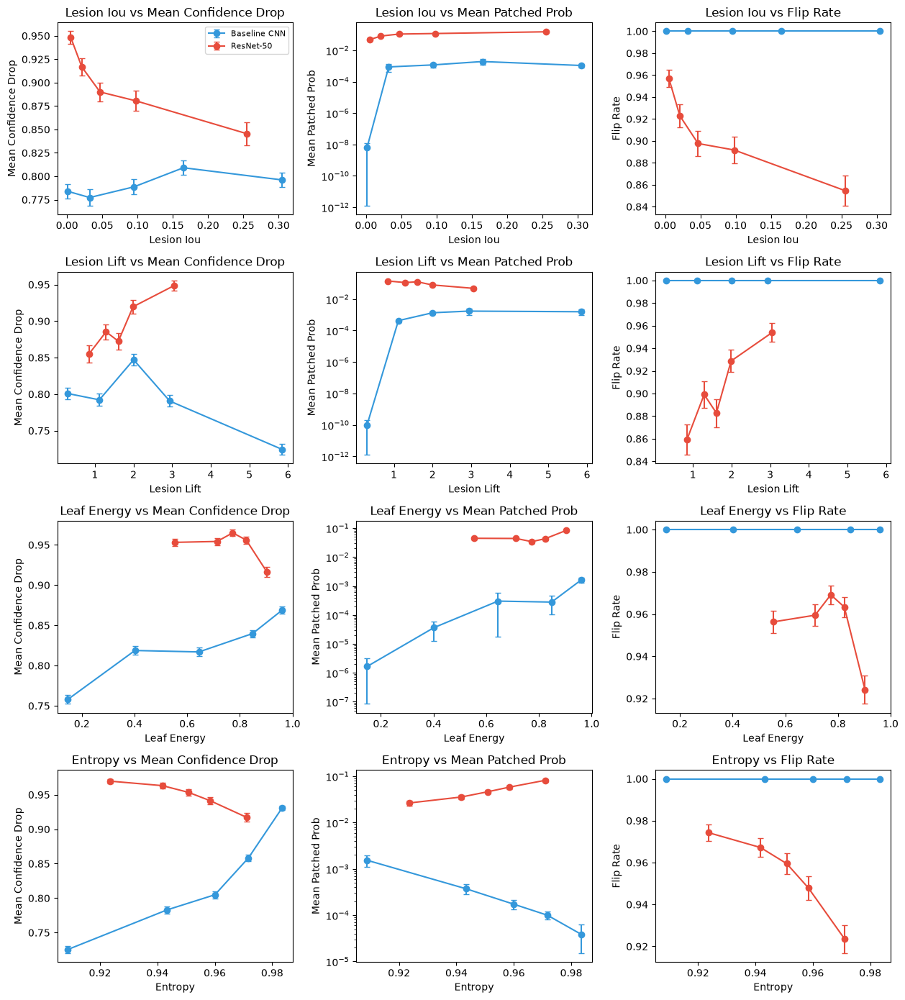

Saved outputs/stage4_quintile_bins.png

Quintile table (10% patch, excl attractor, leaf_energy):

  Baseline CNN:
    Q0: LE [0.000,0.275]  n=1437  drop=0.7581  p_patched=0.000002  flip=1.0000
    Q1: LE [0.275,0.525]  n=1436  drop=0.8187  p_patched=0.000036  flip=1.0000
    Q2: LE [0.525,0.758]  n=1436  drop=0.8170  p_patched=0.000301  flip=1.0000
    Q3: LE [0.759,0.916]  n=1436  drop=0.8398  p_patched=0.000278  flip=1.0000
    Q4: LE [0.916,1.000]  n=1436  drop=0.8688  p_patched=0.001605  flip=1.0000

  ResNet-50:
    Q0: LE [0.000,0.671]  n=1556  drop=0.9531  p_patched=0.044607  flip=0.9563
    Q1: LE [0.671,0.747]  n=1555  drop=0.9542  p_patched=0.043979  flip=0.9595
    Q2: LE [0.747,0.798]  n=1556  drop=0.9649  p_patched=0.034162  flip=0.9692
    Q3: LE [0.798,0.852]  n=1555  drop=0.9559  p_patched=0.043286  flip=0.9633
    Q4: LE [0.853,1.000]  n=1556  drop=0.9163  p_patched=0.082828  flip=0.9242


In [59]:
BIN_FRAC    = 0.10
bin_metrics = ['lesion_iou', 'lesion_lift', 'leaf_energy', 'entropy']
rob_pair    = [('conf_drop', 'Mean Confidence Drop', False),
               ('p_patched', 'Mean Patched Prob',    True),
               ('flipped',   'Flip Rate',            False)]
colors = {'Baseline CNN': '#3498db', 'ResNet-50': '#e74c3c'}

fig, axes = plt.subplots(len(bin_metrics), len(rob_pair),
                         figsize=(4.2*len(rob_pair), 3.5*len(bin_metrics)),
                         sharex=False)
for ri, acol in enumerate(bin_metrics):
    for ci, (rcol, ylabel, use_log) in enumerate(rob_pair):
        ax = axes[ri, ci]
        for mname in ['Baseline CNN', 'ResNet-50']:
            sub = img_df[(img_df['model'] == mname) &
                         (img_df['patch_frac'] == BIN_FRAC) &
                         (img_df['is_attractor'] == 0) &
                         (img_df[acol].notna())].copy()
            if len(sub) < 25:
                continue
            sub['q'] = pd.qcut(sub[acol], 5, labels=False, duplicates='drop')
            g = sub.groupby('q').agg(
                xm=(acol, 'mean'), ym=(rcol, 'mean'),
                ye=(rcol, 'sem'), cnt=(rcol, 'size')).reset_index()
            ax.errorbar(g['xm'], g['ym'], yerr=g['ye'],
                        marker='o', capsize=3, color=colors[mname],
                        label=mname)
        if use_log:
            ax.set_yscale('log')
        ax.set_xlabel(acol.replace('_', ' ').title())
        ax.set_ylabel(ylabel)
        ax.set_title(f'{acol.replace("_"," ").title()} vs {ylabel}')
        if ri == 0 and ci == 0:
            ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage4_quintile_bins.png', dpi=150,
            bbox_inches='tight')
plt.show()
print(f'Saved {OUTPUT_ROOT}/stage4_quintile_bins.png')

print(f'\nQuintile table (10% patch, excl attractor, leaf_energy):')
for mname in ['Baseline CNN', 'ResNet-50']:
    sub = img_df[(img_df['model'] == mname) &
                 (img_df['patch_frac'] == BIN_FRAC) &
                 (img_df['is_attractor'] == 0)].copy()
    sub['q'] = pd.qcut(sub['leaf_energy'], 5, labels=False, duplicates='drop')
    g = sub.groupby('q').agg(
        lo=('leaf_energy','min'), hi=('leaf_energy','max'),
        drop=('conf_drop','mean'), p_pat=('p_patched','mean'),
        flip=('flipped','mean'), n=('leaf_energy','size'))
    print(f'\n  {mname}:')
    for q, r in g.iterrows():
        print(f'    Q{q}: LE [{r["lo"]:.3f},{r["hi"]:.3f}]  n={int(r["n"])}  '
              f'drop={r["drop"]:.4f}  p_patched={r["p_pat"]:.6f}  '
              f'flip={r["flip"]:.4f}')

## Per-Class Correlations

Class-level table: 222 rows
  per model x size: ~37 classes (excl attractor)
Bonferroni: 72 tests, alpha = 0.000694

Class-level correlations: 72 tests, 10 Spearman-significant
  (6 skipped: no variance in y)
    Baseline CNN      10%  lesion_iou             vs flip_rate   n=25
    Baseline CNN      10%  lesion_lift            vs flip_rate   n=25
    Baseline CNN      10%  leaf_energy            vs flip_rate   n=37
    Baseline CNN      10%  entropy                vs flip_rate   n=37
    Baseline CNN      10%  lesion_frac(all)       vs flip_rate   n=37
    Baseline CNN      10%  lesion_frac(diseased)  vs flip_rate   n=25

All class-level Spearman at 10% (primary):
  ResNet-50      lesion_frac(diseased)  vs flip_rate   rho=-0.6906  p=1.33e-04  n= 25 *
  ResNet-50      lesion_frac(all)       vs flip_rate   rho=-0.6308  p=2.84e-05  n= 37 *
  ResNet-50      lesion_iou             vs flip_rate   rho=-0.4448  p=2.59e-02  n= 25  
  Baseline CNN   entropy                vs mean_log_p  rho=-0.4

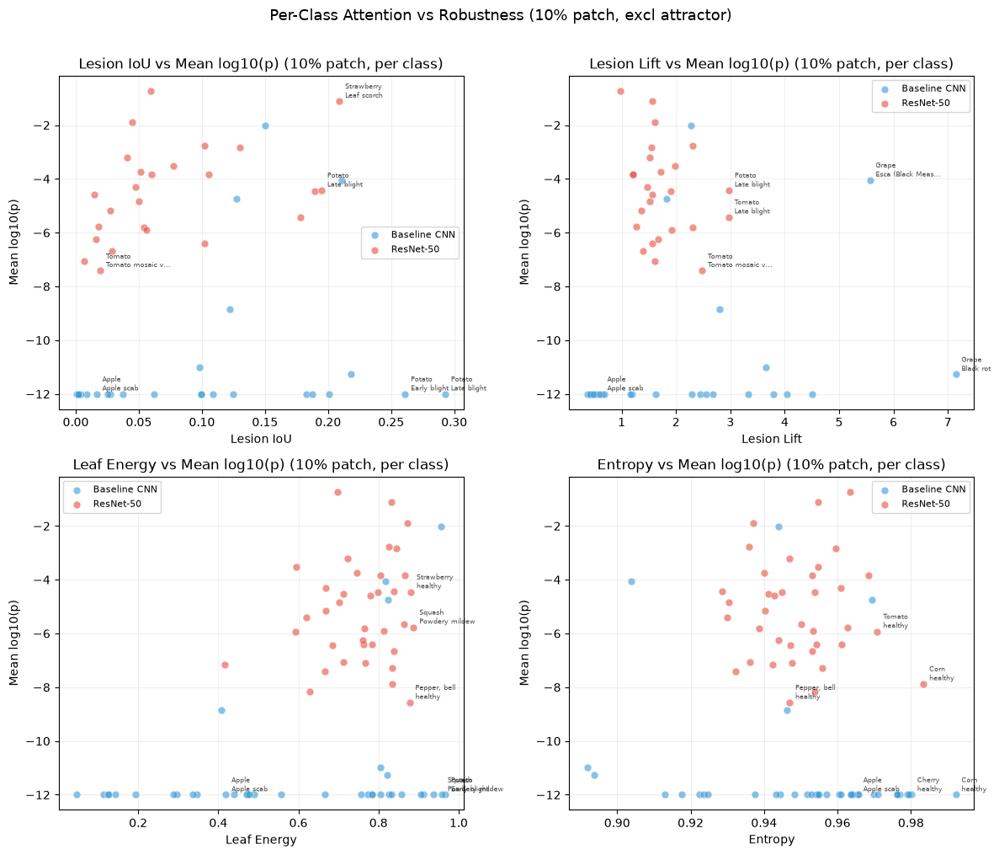

Saved outputs/stage4_class_scatter.png


In [60]:
CLASS_FRAC = 0.10
cls_attn_cols = ['lesion_iou', 'lesion_lift', 'leaf_energy', 'entropy']
cls_rob_cols  = ['flip_rate', 'mean_log_p']

cls_rows = []
for mname in ['Baseline CNN', 'ResNet-50']:
    for frac in PATCH_FRACTIONS:
        sub = img_df[(img_df['model'] == mname) &
                     (img_df['patch_frac'] == frac) &
                     (img_df['is_attractor'] == 0)].copy()
        sub['log_p'] = np.log10(sub['p_patched'].clip(lower=1e-12))
        g = sub.groupby('true_label').agg(
            flip_rate=('flipped', 'mean'),
            mean_log_p=('log_p', 'mean'),
            lesion_iou=('lesion_iou', 'mean'),
            lesion_lift=('lesion_lift', 'mean'),
            leaf_energy=('leaf_energy', 'mean'),
            entropy=('entropy', 'mean'),
            lesion_frac=('lesion_frac', 'mean'),
            n=('flipped', 'size'),
        ).reset_index()
        g['model'] = mname
        g['patch_frac'] = frac
        g['class_name'] = g['true_label'].map(lambda i: filtered_classes[i])
        g['diseased'] = ~g['true_label'].isin(healthy_classes)
        cls_rows.append(g)

cls_df = pd.concat(cls_rows, ignore_index=True)
cls_df.to_csv(f'{OUTPUT_ROOT}/stage4_class_level.csv', index=False)
print(f'Class-level table: {len(cls_df)} rows')
print(f'  per model x size: ~{len(cls_df) // 6} classes (excl attractor)')

n_cls_tests = len(cls_attn_cols) * len(cls_rob_cols) * 2 * 3 + len(cls_rob_cols) * 2 * 2 * 3
alpha_cls = 0.05 / n_cls_tests
print(f'Bonferroni: {n_cls_tests} tests, alpha = {alpha_cls:.6f}')

cls_corr_rows = []
for mname in ['Baseline CNN', 'ResNet-50']:
    for frac in PATCH_FRACTIONS:
        g = cls_df[(cls_df['model'] == mname) & (cls_df['patch_frac'] == frac)]
        for acol in cls_attn_cols:
            is_lesion = acol in ['lesion_iou', 'lesion_lift']
            subset = g[g['diseased']] if is_lesion else g
            for rcol in cls_rob_cols:
                valid = subset[[acol, rcol]].dropna()
                n = len(valid)
                if n < 10:
                    continue
                x, y = valid[acol].values, valid[rcol].values
                if x.std() == 0 or y.std() == 0:
                    cls_corr_rows.append(dict(
                        model=mname, patch_frac=frac,
                        attention=acol, robustness=rcol, n=n,
                        pearson_r=float('nan'), pearson_p=float('nan'),
                        spearman_rho=float('nan'), spearman_p=float('nan'),
                        pearson_sig=False, spearman_sig=False,
                        note='no variance'))
                    continue
                rp, pp = pearsonr(x, y)
                rs, ps = spearmanr(x, y)
                cls_corr_rows.append(dict(
                    model=mname, patch_frac=frac,
                    attention=acol, robustness=rcol, n=n,
                    pearson_r=rp, pearson_p=pp,
                    spearman_rho=rs, spearman_p=ps,
                    pearson_sig=pp < alpha_cls,
                    spearman_sig=ps < alpha_cls,
                    note=''))
        g_dis = g[g['diseased']]
        for rcol in cls_rob_cols:
            for tag, sub in [('all', g), ('diseased', g_dis)]:
                valid = sub[['lesion_frac', rcol]].dropna()
                if len(valid) < 10:
                    continue
                x, y = valid['lesion_frac'].values, valid[rcol].values
                if x.std() == 0 or y.std() == 0:
                    cls_corr_rows.append(dict(
                        model=mname, patch_frac=frac,
                        attention=f'lesion_frac({tag})', robustness=rcol,
                        n=len(valid),
                        pearson_r=float('nan'), pearson_p=float('nan'),
                        spearman_rho=float('nan'), spearman_p=float('nan'),
                        pearson_sig=False, spearman_sig=False,
                        note='no variance'))
                    continue
                rs, ps = spearmanr(x, y)
                cls_corr_rows.append(dict(
                    model=mname, patch_frac=frac,
                    attention=f'lesion_frac({tag})', robustness=rcol,
                    n=len(valid),
                    pearson_r=float('nan'), pearson_p=float('nan'),
                    spearman_rho=rs, spearman_p=ps,
                    pearson_sig=False, spearman_sig=ps < alpha_cls,
                    note=''))

cls_corr_df = pd.DataFrame(cls_corr_rows)
cls_corr_df.to_csv(f'{OUTPUT_ROOT}/stage4_class_correlations.csv', index=False)
sig_cls = cls_corr_df[cls_corr_df['spearman_sig']]
novar = cls_corr_df[cls_corr_df['note'] == 'no variance']
print(f'\nClass-level correlations: {len(cls_corr_df)} tests, '
      f'{len(sig_cls)} Spearman-significant')
if len(novar):
    print(f'  ({len(novar)} skipped: no variance in y)')
    for _, r in novar.iterrows():
        print(f'    {r["model"]:14s} {r["patch_frac"]*100:5.0f}%  '
              f'{r["attention"]:22s} vs {r["robustness"]:10s}  n={r["n"]}')

print(f'\nAll class-level Spearman at 10% (primary):')
sub10 = cls_corr_df[cls_corr_df['patch_frac'] == CLASS_FRAC]
for _, r in sub10.sort_values('spearman_rho').iterrows():
    star = '*' if r['spearman_sig'] else ' '
    tag = f'  [{r["note"]}]' if r['note'] else ''
    print(f'  {r["model"]:14s} {r["attention"]:22s} vs {r["robustness"]:10s}  '
          f'rho={r["spearman_rho"]:+.4f}  p={r["spearman_p"]:.2e}  n={r["n"]:3d} {star}{tag}')

print(f'\nNote: with n ~ 25-37, |rho| must exceed ~0.33-0.40 for p < 0.05. '
      f'Bonferroni further raises the bar. These are supporting evidence only.')
print(f'Note: Baseline per-class flip rate is ~1.0 at 10% (all classes fully flipped '
      f'after excluding the attractor), so flip_rate has no variance for the Baseline. '
      f'The mean_log_p metric is informative for both models.')

SCATTER_PAIRS = [
    ('lesion_iou',  'mean_log_p', 'Lesion IoU',   'Mean log10(p)'),
    ('lesion_lift', 'mean_log_p', 'Lesion Lift',   'Mean log10(p)'),
    ('leaf_energy', 'mean_log_p', 'Leaf Energy',   'Mean log10(p)'),
    ('entropy',     'mean_log_p', 'Entropy',        'Mean log10(p)'),
]
colors = {'Baseline CNN': '#3498db', 'ResNet-50': '#e74c3c'}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (acol, rcol, xlabel, ylabel) in zip(axes.flat, SCATTER_PAIRS):
    is_lesion = acol in ['lesion_iou', 'lesion_lift']
    for mname in ['Baseline CNN', 'ResNet-50']:
        g = cls_df[(cls_df['model'] == mname) &
                   (cls_df['patch_frac'] == CLASS_FRAC)]
        if is_lesion:
            g = g[g['diseased']]
        valid = g[[acol, rcol, 'class_name']].dropna()
        ax.scatter(valid[acol], valid[rcol], color=colors[mname],
                   alpha=0.6, s=40, label=mname, edgecolors='white', linewidth=0.5)
        extremes = pd.concat([valid.nlargest(2, acol), valid.nsmallest(1, rcol)])
        for _, row in extremes.drop_duplicates().iterrows():
            short = row['class_name'].replace('___', '\n').replace('_', ' ')
            if len(short) > 25:
                short = short[:22] + '...'
            ax.annotate(short, (row[acol], row[rcol]),
                        fontsize=6, alpha=0.7,
                        textcoords='offset points', xytext=(5, 3))
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f'{xlabel} vs {ylabel} (10% patch, per class)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

plt.suptitle('Per-Class Attention vs Robustness (10% patch, excl attractor)',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage4_class_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved {OUTPUT_ROOT}/stage4_class_scatter.png')

## Model-Level Comparison Table

In [61]:
model_rows = []
for mname in ['Baseline CNN', 'ResNet-50']:
    acc, ci_lo, ci_hi = boot_ci[mname]
    f1 = f1_score(test_labels, test_preds[mname], average='macro')

    clean_attn = attn_df[(attn_df['model'] == mname) &
                         (attn_df['condition'] == 'clean')]
    le = clean_attn['leaf_energy'].mean()
    ll = clean_attn['lesion_lift'].dropna().mean()
    ent = clean_attn['entropy'].mean()

    row = {'Model': mname,
           'Clean Acc': round(acc, 4),
           'CI Lo': round(ci_lo, 4),
           'CI Hi': round(ci_hi, 4),
           'Macro-F1': round(f1, 4),
           'Leaf Energy': round(le, 4),
           'Lesion Lift': round(ll, 2),
           'Entropy': round(ent, 4)}

    for frac in PATCH_FRACTIONS:
        tag = f'{int(frac*100)}%'
        r_adv = results_df[(results_df['Model'] == mname) &
                           (results_df['Patch Frac'] == frac)].iloc[0]
        row[f'ASR {tag}'] = round(float(r_adv['ASR']), 4)
        row[f'Noise ASR {tag}'] = round(float(r_adv['Noise ASR']), 4)

    pe_10 = attn_df[(attn_df['model'] == mname) &
                    (attn_df['condition'] == 'patch_10pct')]['patch_energy'].mean()
    row['Patch Energy 10%'] = round(pe_10, 4)
    model_rows.append(row)

model_table = pd.DataFrame(model_rows)
model_table.to_csv(f'{OUTPUT_ROOT}/stage4_model_comparison.csv', index=False)

display_t = model_table.copy()
display_t['CI 95%'] = display_t.apply(
    lambda r: f'[{r["CI Lo"]:.4f}, {r["CI Hi"]:.4f}]', axis=1)
display_t = display_t.drop(columns=['CI Lo', 'CI Hi'])
cols = ['Model', 'Clean Acc', 'CI 95%', 'Macro-F1'] + \
       [c for c in display_t.columns if c not in ['Model', 'Clean Acc', 'CI 95%', 'Macro-F1']]
print(display_t[cols].T.to_string(header=False))
print(f'\nSaved {OUTPUT_ROOT}/stage4_model_comparison.csv')
print(f'\nNote: with n = 2 models this is descriptive only. '
      f'No cross-model correlation is meaningful.')

Model                 Baseline CNN         ResNet-50
Clean Acc                   0.8898            0.9971
CI 95%            [0.8829, 0.8963]  [0.9958, 0.9982]
Macro-F1                    0.8594            0.9956
Leaf Energy                 0.5901            0.7505
Lesion Lift                    2.4              1.78
Entropy                      0.952            0.9486
ASR 5%                       0.987            0.7062
Noise ASR 5%                0.1213            0.0011
ASR 10%                     0.9908            0.9141
Noise ASR 10%                0.398            0.0032
ASR 15%                     0.9739            0.9424
Noise ASR 15%                0.589            0.0078
Patch Energy 10%            0.8541            0.5097

Saved outputs/stage4_model_comparison.csv

Note: with n = 2 models this is descriptive only. No cross-model correlation is meaningful.


## PlantDoc Cross-Dataset Check 

PlantDoc mapping: 28 folders -> 28 PlantVillage classes
PlantDoc dataset: 2578 images
Class distribution:
Corn___Northern_Leaf_Blight    192
Tomato___Septoria_leaf_spot    151
Squash___Powdery_mildew        130
Raspberry___healthy            119
Blueberry___healthy            117
Potato___Early_blight          117
Corn___Common_rust             116
Peach___healthy                112
Tomato___Late_blight           111
Tomato___Bacterial_spot        110

Baseline CNN:
  Accuracy:      0.0706  (182/2578)
  Crop-correct:  0.1908
  Chance:        0.0263
  Most predicted: Pepper,_bell___Bacterial_spot (26.88%)

ResNet-50:
  Accuracy:      0.1800  (463/2578)
  Crop-correct:  0.3867
  Chance:        0.0263
  Most predicted: Strawberry___Leaf_scorch (31.11%)

Saved outputs/stage4_plantdoc_results.csv


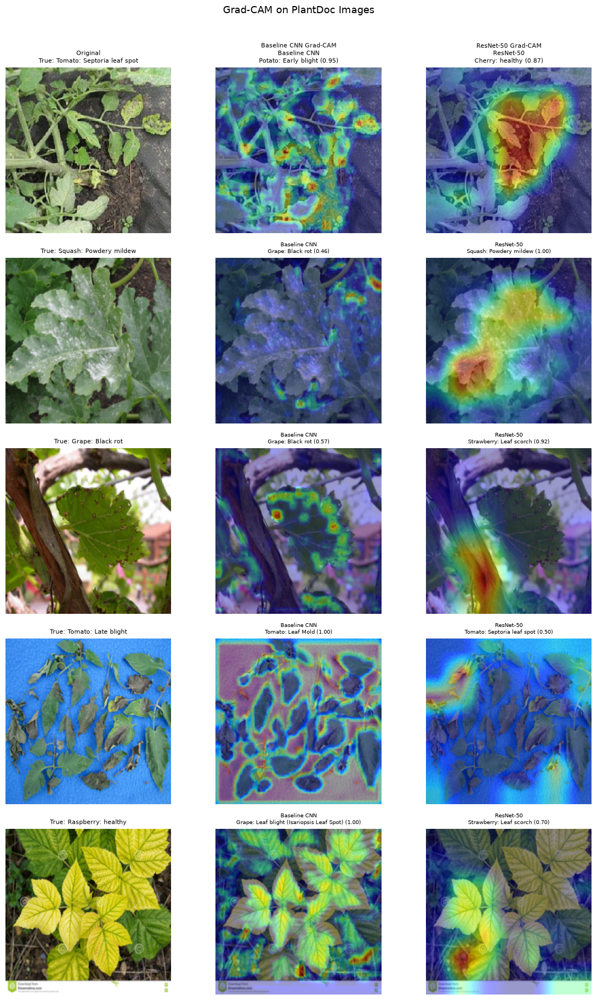

Saved outputs/stage4_plantdoc_gradcam.png


In [62]:
PLANTDOC_MAP = {
    'Apple Scab Leaf':                      'Apple___Apple_scab',
    'Apple leaf':                           'Apple___healthy',
    'Apple rust leaf':                      'Apple___Cedar_apple_rust',
    'Bell_pepper leaf':                     'Pepper,_bell___healthy',
    'Bell_pepper leaf spot':                'Pepper,_bell___Bacterial_spot',
    'Blueberry leaf':                       'Blueberry___healthy',
    'Cherry leaf':                          'Cherry___healthy',
    'Corn Gray leaf spot':                  'Corn___Cercospora_leaf_spot Gray_leaf_spot',
    'Corn leaf blight':                     'Corn___Northern_Leaf_Blight',
    'Corn rust leaf':                       'Corn___Common_rust',
    'Peach leaf':                           'Peach___healthy',
    'Potato leaf early blight':             'Potato___Early_blight',
    'Potato leaf late blight':              'Potato___Late_blight',
    'Raspberry leaf':                       'Raspberry___healthy',
    'Soyabean leaf':                        'Soybean___healthy',
    'Squash Powdery mildew leaf':           'Squash___Powdery_mildew',
    'Strawberry leaf':                      'Strawberry___healthy',
    'Tomato Early blight leaf':             'Tomato___Early_blight',
    'Tomato Septoria leaf spot':            'Tomato___Septoria_leaf_spot',
    'Tomato leaf':                          'Tomato___healthy',
    'Tomato leaf bacterial spot':           'Tomato___Bacterial_spot',
    'Tomato leaf late blight':              'Tomato___Late_blight',
    'Tomato leaf mosaic virus':             'Tomato___Tomato_mosaic_virus',
    'Tomato leaf yellow virus':             'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
    'Tomato mold leaf':                     'Tomato___Leaf_Mold',
    'Tomato two spotted spider mites leaf': 'Tomato___Spider_mites Two-spotted_spider_mite',
    'grape leaf':                           'Grape___healthy',
    'grape leaf black rot':                 'Grape___Black_rot',
}
assert set(PLANTDOC_MAP.values()) <= set(filtered_classes), \
    f'Unmapped: {set(PLANTDOC_MAP.values()) - set(filtered_classes)}'
pv_label_to_idx = {name: i for i, name in enumerate(filtered_classes)}
print(f'PlantDoc mapping: {len(PLANTDOC_MAP)} folders -> '
      f'{len(set(PLANTDOC_MAP.values()))} PlantVillage classes')

class PlantDocDataset(torch.utils.data.Dataset):
    def __init__(self, root, mapping, label_to_idx, transform):
        self.transform = transform
        self.samples = []
        root = Path(root)
        search_dirs = []
        for split in ['train', 'test']:
            if (root / split).exists():
                search_dirs.append(root / split)
        if not search_dirs:
            search_dirs = [root]
        for sdir in search_dirs:
            for folder in sorted(sdir.iterdir()):
                if not folder.is_dir():
                    continue
                name = folder.name
                if name not in mapping:
                    continue
                pv_class = mapping[name]
                label = label_to_idx[pv_class]
                for img_path in sorted(folder.iterdir()):
                    if img_path.suffix.lower() in ('.jpg', '.jpeg', '.png', '.bmp'):
                        self.samples.append((str(img_path), label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        tensor = self.transform(img)
        return tensor, label

pd_ds = PlantDocDataset(Path(PLANTDOC_ROOT) / 'PlantDoc-Dataset-master', PLANTDOC_MAP, pv_label_to_idx, eval_transform)
assert len(pd_ds) > 0, 'PlantDoc path is wrong — no images found'
pd_loader = DataLoader(pd_ds, batch_size=32, shuffle=False,
                       num_workers=2, pin_memory=(device.type == 'cuda'))
print(f'PlantDoc dataset: {len(pd_ds)} images')
pd_labels = torch.tensor([s[1] for s in pd_ds.samples])
pd_classes = pd.Series([filtered_classes[l] for l in pd_labels.numpy()])
print(f'Class distribution:\n{pd_classes.value_counts().head(10).to_string()}')

pd_results = []
for mname, model in [('Baseline CNN', baseline_model), ('ResNet-50', resnet_model)]:
    probs = predict(model, pd_loader)
    preds = probs.argmax(1)
    acc = (preds == pd_labels).float().mean().item()
    pred_species = pd.Series([filtered_classes[p].split('___')[0] for p in preds.numpy()])
    true_species = pd.Series([filtered_classes[l].split('___')[0] for l in pd_labels.numpy()])
    crop_correct = (pred_species == true_species).mean()
    chance = 1.0 / len(filtered_classes)
    top_pred_cls = Counter(preds.numpy().tolist()).most_common(1)[0]
    top_name = filtered_classes[top_pred_cls[0]]
    top_share = top_pred_cls[1] / len(pd_labels)
    pd_results.append(dict(model=mname, accuracy=acc, crop_correct=crop_correct,
                           chance=chance, most_predicted=top_name,
                           most_predicted_share=top_share))
    print(f'\n{mname}:')
    print(f'  Accuracy:      {acc:.4f}  ({int(acc * len(pd_labels))}/{len(pd_labels)})')
    print(f'  Crop-correct:  {crop_correct:.4f}')
    print(f'  Chance:        {chance:.4f}')
    print(f'  Most predicted: {top_name} ({top_share:.2%})')

pd_results_df = pd.DataFrame(pd_results)
pd_results_df.to_csv(f'{OUTPUT_ROOT}/stage4_plantdoc_results.csv', index=False)
print(f'\nSaved {OUTPUT_ROOT}/stage4_plantdoc_results.csv')

gen_pd = torch.Generator().manual_seed(SEED)
pd_sample_idx = torch.randperm(len(pd_ds), generator=gen_pd)[:5].tolist()
fig, axes = plt.subplots(5, 3, figsize=(12, 18))
col_labels = ['Original', 'Baseline CNN Grad-CAM', 'ResNet-50 Grad-CAM']

for row_i, si in enumerate(pd_sample_idx):
    img_t, label = pd_ds[si]
    img_np = unnormalize(img_t).permute(1, 2, 0).numpy()
    axes[row_i, 0].imshow(img_np)
    true_name = filtered_classes[label].replace('___', ': ').replace('_', ' ')
    axes[row_i, 0].set_title(f'True: {true_name}', fontsize=8)
    axes[row_i, 0].axis('off')
    for col_i, mname in enumerate(['Baseline CNN', 'ResNet-50'], start=1):
        inp = img_t.unsqueeze(0).to(device)
        cam, logits = extractors[mname](inp)
        cam_np = cam[0].cpu().numpy()
        pred_idx = logits[0].argmax().item()
        pred_name = filtered_classes[pred_idx].replace('___', ': ').replace('_', ' ')
        conf = F.softmax(logits[0], dim=0)[pred_idx].item()
        axes[row_i, col_i].imshow(img_np)
        axes[row_i, col_i].imshow(cam_np, cmap='jet', alpha=0.4)
        axes[row_i, col_i].set_title(f'{mname}\n{pred_name} ({conf:.2f})', fontsize=7)
        axes[row_i, col_i].axis('off')

for ci, lbl in enumerate(col_labels):
    axes[0, ci].set_title(lbl + '\n' + axes[0, ci].get_title(), fontsize=8)

plt.suptitle('Grad-CAM on PlantDoc Images', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage4_plantdoc_gradcam.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved {OUTPUT_ROOT}/stage4_plantdoc_gradcam.png')

## Background Shortcut Test


Baseline CNN (n=8095, skipped leaf_frac < 0.1):
  Clean accuracy:                0.8902
  Leaf-only accuracy (all):      0.5444
  Leaf-only accuracy (cc only):  0.5828  (n=7206)
  Background-only acc (all):     0.0831  (chance = 0.0263)
  Background-only acc (cc only): 0.0833
  Swap (clean-correct only):
    Still own class: 0.6947  (4767/6862)
    Donor class:     0.0277  (190/6862)
    Same-class pairs skipped: 381

ResNet-50 (n=8095, skipped leaf_frac < 0.1):
  Clean accuracy:                0.9972
  Leaf-only accuracy (all):      0.9920
  Leaf-only accuracy (cc only):  0.9939  (n=8072)
  Background-only acc (all):     0.1501  (chance = 0.0263)
  Background-only acc (cc only): 0.1505
  Swap (clean-correct only):
    Still own class: 0.9849  (7575/7691)
    Donor class:     0.0012  (9/7691)
    Same-class pairs skipped: 381

Saved outputs/stage4_background_test.csv


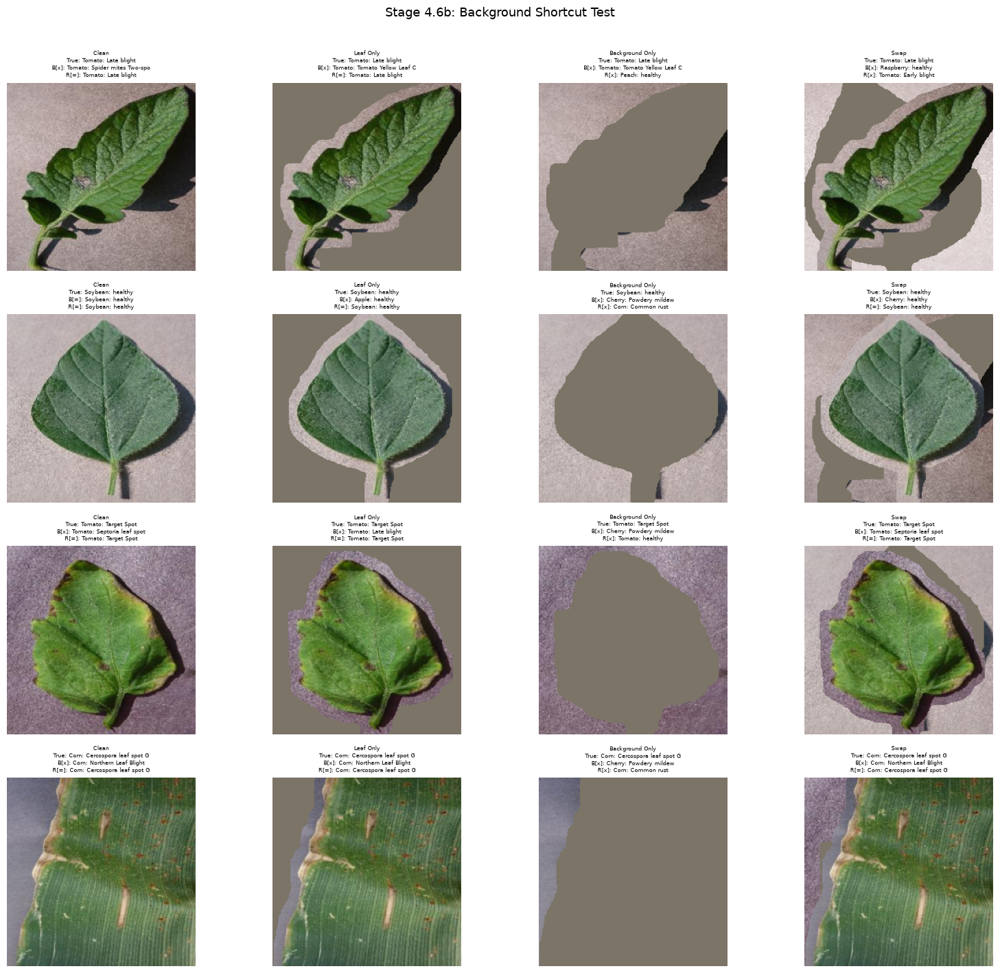

Saved outputs/stage4_background_test.png

Caveat: gray fill with sharp mask edges is itself unusual input. A drop on leaf-only may partly reflect the unusual appearance. The swap condition is the key test: it uses a real PlantVillage background, and "follows the donor class" can only come from background information.


In [63]:
DIL_KS = 21
DIL_PAD = 10
MIN_LEAF_FRAC = 0.10

bg_rows = []
example_imgs = {k: [] for k in ['clean', 'leaf_only', 'bg_only', 'swap',
                                 'true_label',
                                 'pred_clean_b', 'pred_leaf_b', 'pred_bg_b', 'pred_swap_b',
                                 'pred_clean_r', 'pred_leaf_r', 'pred_bg_r', 'pred_swap_r']}
n_examples = 4

for mname, model in [('Baseline CNN', baseline_model), ('ResNet-50', resnet_model)]:
    suffix = '_b' if mname == 'Baseline CNN' else '_r'
    model.eval()
    clean_correct, leaf_correct, bg_correct = 0, 0, 0
    leaf_correct_cc, bg_correct_cc = 0, 0
    swap_own, swap_donor, swap_total = 0, 0, 0
    same_class_skipped = 0
    total, total_cc = 0, 0

    with torch.no_grad():
        for imgs, lbls, leaf, lesion, idx in mask_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            leaf_f = leaf.float().to(device)
            leaf_frac_batch = leaf_f.mean(dim=(1, 2))
            good = leaf_frac_batch >= MIN_LEAF_FRAC
            if good.sum() == 0:
                continue
            imgs = imgs[good]
            lbls = lbls[good]
            leaf_f = leaf_f[good]
            b = imgs.size(0)

            leaf_dil = (F.max_pool2d(leaf_f[:, None], kernel_size=DIL_KS,
                                     stride=1, padding=DIL_PAD)[:, 0] > 0).float()
            bg_mask = 1.0 - leaf_dil

            leaf_only = imgs * leaf_dil[:, None]
            bg_only = imgs * bg_mask[:, None]

            donor_imgs = torch.roll(imgs, 1, dims=0)
            donor_leaf = torch.roll(leaf_dil, 1, dims=0)
            donor_lbls = torch.roll(lbls, 1, dims=0)
            donor_bg = 1.0 - donor_leaf
            donor_bg_cleaned = donor_imgs * donor_bg[:, None]
            swap = imgs * leaf_dil[:, None] + donor_bg_cleaned * bg_mask[:, None]

            same_cls = (lbls == donor_lbls)
            same_class_skipped += same_cls.sum().item()

            logits_clean = model(imgs)
            logits_leaf  = model(leaf_only)
            logits_bg    = model(bg_only)
            logits_swap  = model(swap)

            pred_c = logits_clean.argmax(1)
            pred_l = logits_leaf.argmax(1)
            pred_b = logits_bg.argmax(1)
            pred_s = logits_swap.argmax(1)

            ok = (pred_c == lbls)
            clean_correct += ok.sum().item()
            leaf_correct  += (pred_l == lbls).sum().item()
            bg_correct    += (pred_b == lbls).sum().item()
            leaf_correct_cc += (pred_l[ok] == lbls[ok]).sum().item()
            bg_correct_cc   += (pred_b[ok] == lbls[ok]).sum().item()
            total_cc += ok.sum().item()

            diff_cls_ok = ~same_cls & ok
            swap_own   += (pred_s[diff_cls_ok] == lbls[diff_cls_ok]).sum().item()
            swap_donor += (pred_s[diff_cls_ok] == donor_lbls[diff_cls_ok]).sum().item()
            swap_total += diff_cls_ok.sum().item()
            total += b

            if len(example_imgs['pred_clean' + suffix]) < n_examples:
                need = min(n_examples - len(example_imgs['pred_clean' + suffix]), b)
                for j in range(need):
                    if suffix == '_b':
                        de = lambda t: unnormalize(t).permute(1, 2, 0).numpy()
                        example_imgs['clean'].append(de(imgs[j].cpu()))
                        example_imgs['leaf_only'].append(de(leaf_only[j].cpu()))
                        example_imgs['bg_only'].append(de(bg_only[j].cpu()))
                        example_imgs['swap'].append(de(swap[j].cpu()))
                        example_imgs['true_label'].append(filtered_classes[lbls[j].item()])
                    for key, pred in [('pred_clean', pred_c), ('pred_leaf', pred_l),
                                      ('pred_bg', pred_b), ('pred_swap', pred_s)]:
                        example_imgs[key + suffix].append(filtered_classes[pred[j].item()])

    bg_rows.append(dict(
        model=mname, total=total, total_clean_correct=total_cc,
        clean_acc=clean_correct / total,
        leaf_only_acc=leaf_correct / total,
        bg_only_acc=bg_correct / total,
        leaf_only_acc_cc=leaf_correct_cc / total_cc if total_cc > 0 else 0,
        bg_only_acc_cc=bg_correct_cc / total_cc if total_cc > 0 else 0,
        swap_own_pct=swap_own / swap_total if swap_total > 0 else 0,
        swap_donor_pct=swap_donor / swap_total if swap_total > 0 else 0,
        swap_total=swap_total,
        same_class_skipped=same_class_skipped,
    ))
    print(f'\n{mname} (n={total}, skipped leaf_frac < {MIN_LEAF_FRAC}):')
    print(f'  Clean accuracy:                {clean_correct/total:.4f}')
    print(f'  Leaf-only accuracy (all):      {leaf_correct/total:.4f}')
    print(f'  Leaf-only accuracy (cc only):  {leaf_correct_cc/total_cc:.4f}  (n={total_cc})')
    print(f'  Background-only acc (all):     {bg_correct/total:.4f}  '
          f'(chance = {1/len(filtered_classes):.4f})')
    print(f'  Background-only acc (cc only): {bg_correct_cc/total_cc:.4f}')
    print(f'  Swap (clean-correct only):')
    print(f'    Still own class: {swap_own/swap_total:.4f}  ({swap_own}/{swap_total})')
    print(f'    Donor class:     {swap_donor/swap_total:.4f}  ({swap_donor}/{swap_total})')
    print(f'    Same-class pairs skipped: {same_class_skipped}')

bg_df = pd.DataFrame(bg_rows)
bg_df.to_csv(f'{OUTPUT_ROOT}/stage4_background_test.csv', index=False)
print(f'\nSaved {OUTPUT_ROOT}/stage4_background_test.csv')

fig, axes = plt.subplots(n_examples, 4, figsize=(16, 3.5 * n_examples))
cond_names = ['clean', 'leaf_only', 'bg_only', 'swap']
cond_titles = ['Clean', 'Leaf Only', 'Background Only', 'Swap']
pred_keys  = ['pred_clean', 'pred_leaf', 'pred_bg', 'pred_swap']

for row_i in range(n_examples):
    true_name = example_imgs['true_label'][row_i].replace('___', ': ').replace('_', ' ')
    for col_i, (cond, pk, title) in enumerate(zip(cond_names, pred_keys, cond_titles)):
        ax = axes[row_i, col_i]
        ax.imshow(example_imgs[cond][row_i])
        pred_b = example_imgs[f'{pk}_b'][row_i].replace('___', ': ').replace('_', ' ')
        pred_r = example_imgs[f'{pk}_r'][row_i].replace('___', ': ').replace('_', ' ')
        match_b = '=' if example_imgs[f'{pk}_b'][row_i] == example_imgs['true_label'][row_i] else 'x'
        match_r = '=' if example_imgs[f'{pk}_r'][row_i] == example_imgs['true_label'][row_i] else 'x'
        ax.set_title(f'{title}\nTrue: {true_name[:28]}\n'
                     f'B[{match_b}]: {pred_b[:28]}\n'
                     f'R[{match_r}]: {pred_r[:28]}',
                     fontsize=6)
        ax.axis('off')

plt.suptitle('Stage 4.6b: Background Shortcut Test', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage4_background_test.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved {OUTPUT_ROOT}/stage4_background_test.png')
print(f'\nCaveat: gray fill with sharp mask edges is itself unusual input. '
      f'A drop on leaf-only may partly reflect the unusual appearance. '
      f'The swap condition is the key test: it uses a real PlantVillage background, '
      f'and "follows the donor class" can only come from background information.')

## Results

In [64]:
final = {}
for mname in ['Baseline CNN', 'ResNet-50']:
    acc, ci_lo, ci_hi = boot_ci[mname]
    f1 = f1_score(test_labels, test_preds[mname], average='macro')

    clean_attn = attn_df[(attn_df['model'] == mname) &
                         (attn_df['condition'] == 'clean')]
    le = float(clean_attn['leaf_energy'].mean())
    ent = float(clean_attn['entropy'].mean())

    m_dict = {
        'test_accuracy': round(float(acc), 4),
        'ci_95': [round(float(ci_lo), 4), round(float(ci_hi), 4)],
        'macro_f1': round(float(f1), 4),
        'clean_leaf_energy': round(le, 4),
        'clean_entropy': round(ent, 4),
    }

    for frac in PATCH_FRACTIONS:
        tag = f'{int(frac*100)}pct'
        r_adv = results_df[(results_df['Model'] == mname) &
                           (results_df['Patch Frac'] == frac)].iloc[0]
        m_dict[f'asr_{tag}'] = round(float(r_adv['ASR']), 4)
        m_dict[f'noise_asr_{tag}'] = round(float(r_adv['Noise ASR']), 4)

    pe_10 = float(attn_df[(attn_df['model'] == mname) &
                          (attn_df['condition'] == 'patch_10pct')]['patch_energy'].mean())
    m_dict['patch_energy_10pct'] = round(pe_10, 4)

    attractor_row = img_df[(img_df['model'] == mname) &
                           (img_df['patch_frac'] == 0.10)].iloc[0]
    att_cls = int(attractor_row['attractor_class'])
    m_dict['attractor_class'] = filtered_classes[att_cls]
    m_dict['attractor_class_idx'] = att_cls

    key_corrs = corr_df[(corr_df['scope'] == 'excl_attractor') &
                        (corr_df['model'] == mname) &
                        (corr_df['patch_frac'] == 0.10)]
    corr_summary = {}
    for _, r in key_corrs.iterrows():
        pair = f'{r["attention"]}_vs_{r["robustness"]}'
        corr_summary[pair] = {
            'spearman_rho': round(float(r['spearman_rho']), 4),
            'spearman_p': float(r['spearman_p']),
            'significant': bool(r['spearman_sig']),
        }
    m_dict['per_image_correlations_10pct'] = corr_summary

    cls_corr_10 = cls_corr_df[(cls_corr_df['model'] == mname) &
                               (cls_corr_df['patch_frac'] == 0.10)]
    cls_summary = {}
    for _, r in cls_corr_10.iterrows():
        pair = f'{r["attention"]}_vs_{r["robustness"]}'
        cls_summary[pair] = {
            'spearman_rho': round(float(r['spearman_rho']), 4) if not np.isnan(r['spearman_rho']) else None,
            'spearman_p': float(r['spearman_p']) if not np.isnan(r['spearman_p']) else None,
            'significant': bool(r['spearman_sig']),
            'n': int(r['n']),
            'note': r.get('note', ''),
        }
    m_dict['per_class_correlations_10pct'] = cls_summary

    tercile_sub = img_df[(img_df['model'] == mname) &
                         (img_df['patch_frac'] == 0.10) &
                         (img_df['is_attractor'] == 0) &
                         (img_df['lesion_frac'].notna()) &
                         (img_df['lesion_energy'].notna())].copy()
    if len(tercile_sub) >= 20:
        tercile_sub['size_tercile'] = pd.qcut(tercile_sub['lesion_frac'], 3,
                                               labels=['small', 'medium', 'large'],
                                               duplicates='drop')
        terc_results = {}
        for t in ['small', 'medium', 'large']:
            ts = tercile_sub[tercile_sub['size_tercile'] == t]
            if len(ts) >= 20:
                for acol in ['lesion_energy', 'lesion_lift']:
                    valid = ts[[acol, 'p_patched']].dropna()
                    if len(valid) >= 20 and valid[acol].std() > 0:
                        rs, ps = spearmanr(valid[acol], valid['p_patched'])
                        terc_results[f'{t}_{acol}_vs_p_patched'] = {
                            'spearman_rho': round(float(rs), 4),
                            'spearman_p': float(ps),
                            'n': len(valid),
                        }
        m_dict['tercile_correlations_10pct'] = terc_results

    pd_row = pd_results_df[pd_results_df['model'] == mname].iloc[0]
    m_dict['plantdoc_accuracy'] = round(float(pd_row['accuracy']), 4)
    m_dict['plantdoc_crop_correct'] = round(float(pd_row['crop_correct']), 4)

    bg_row = bg_df[bg_df['model'] == mname].iloc[0]
    m_dict['bg_clean_acc'] = round(float(bg_row['clean_acc']), 4)
    m_dict['bg_leaf_only_acc'] = round(float(bg_row['leaf_only_acc']), 4)
    m_dict['bg_bg_only_acc'] = round(float(bg_row['bg_only_acc']), 4)
    m_dict['bg_leaf_only_acc_cc'] = round(float(bg_row['leaf_only_acc_cc']), 4)
    m_dict['bg_bg_only_acc_cc'] = round(float(bg_row['bg_only_acc_cc']), 4)
    m_dict['bg_swap_own_pct'] = round(float(bg_row['swap_own_pct']), 4)
    m_dict['bg_swap_donor_pct'] = round(float(bg_row['swap_donor_pct']), 4)

    final[mname] = m_dict

correct_b = (test_preds['Baseline CNN'] == test_labels)
correct_r = (test_preds['ResNet-50']    == test_labels)
b_val = int((~correct_b &  correct_r).sum())
c_val = int(( correct_b & ~correct_r).sum())
mcnemar_p = binomtest(min(b_val, c_val), n=b_val + c_val, p=0.5).pvalue
final['mcnemar'] = {'b': b_val, 'c': c_val, 'p_value': float(mcnemar_p)}

json_path = Path(OUTPUT_ROOT) / 'final_results.json'
with open(json_path, 'w') as f:
    json.dump(final, f, indent=2, default=str)
print(f'Saved {json_path}')

for mname in ['Baseline CNN', 'ResNet-50']:
    m = final[mname]
    print(f'\n{"=" * 60}')
    print(f'  {mname}')
    print(f'{"=" * 60}')
    print(f'  Test accuracy:     {m["test_accuracy"]:.4f}  '
          f'95% CI [{m["ci_95"][0]:.4f}, {m["ci_95"][1]:.4f}]')
    print(f'  Macro-F1:          {m["macro_f1"]:.4f}')
    print(f'  Clean leaf energy: {m["clean_leaf_energy"]:.4f}')
    print(f'  Clean entropy:     {m["clean_entropy"]:.4f}')
    print(f'  Attractor class:   {m["attractor_class"]}')
    for frac in PATCH_FRACTIONS:
        tag = f'{int(frac*100)}pct'
        print(f'  {int(frac*100):3d}% patch — ASR: {m[f"asr_{tag}"]:.4f}  '
              f'Noise ASR: {m[f"noise_asr_{tag}"]:.4f}')
    print(f'  Patch energy 10%:  {m["patch_energy_10pct"]:.4f}')
    n_sig_img = sum(1 for v in m['per_image_correlations_10pct'].values() if v['significant'])
    n_sig_cls = sum(1 for v in m['per_class_correlations_10pct'].values() if v['significant'])
    print(f'  Per-image corrs (10%, excl-attractor): {n_sig_img} significant')
    print(f'  Per-class corrs (10%, excl-attractor): {n_sig_cls} significant')
    if 'tercile_correlations_10pct' in m:
        print(f'  Tercile confound check (10%):')
        for k, v in m['tercile_correlations_10pct'].items():
            print(f'    {k}: rho={v["spearman_rho"]:+.4f}  p={v["spearman_p"]:.2e}  n={v["n"]}')
    print(f'  PlantDoc acc:      {m["plantdoc_accuracy"]:.4f}  '
          f'crop-correct: {m["plantdoc_crop_correct"]:.4f}')
    print(f'  Background test:')
    print(f'    clean: {m["bg_clean_acc"]:.4f}  '
          f'leaf-only: {m["bg_leaf_only_acc"]:.4f}  '
          f'bg-only: {m["bg_bg_only_acc"]:.4f}')
    print(f'    (cc only) leaf: {m["bg_leaf_only_acc_cc"]:.4f}  '
          f'bg: {m["bg_bg_only_acc_cc"]:.4f}')
    print(f'    swap — own: {m["bg_swap_own_pct"]:.4f}  '
          f'donor: {m["bg_swap_donor_pct"]:.4f}')

mc = final['mcnemar']
print(f'\nMcNemar: b={mc["b"]}, c={mc["c"]}, p={mc["p_value"]:.2e}')

Saved outputs/final_results.json

  Baseline CNN
  Test accuracy:     0.8898  95% CI [0.8829, 0.8963]
  Macro-F1:          0.8594
  Clean leaf energy: 0.5901
  Clean entropy:     0.9520
  Attractor class:   Corn___Cercospora_leaf_spot Gray_leaf_spot
    5% patch — ASR: 0.9870  Noise ASR: 0.1213
   10% patch — ASR: 0.9908  Noise ASR: 0.3980
   15% patch — ASR: 0.9739  Noise ASR: 0.5890
  Patch energy 10%:  0.8541
  Per-image corrs (10%, excl-attractor): 20 significant
  Per-class corrs (10%, excl-attractor): 0 significant
  Tercile confound check (10%):
    small_lesion_energy_vs_p_patched: rho=+0.5034  p=3.08e-68  n=1045
    small_lesion_lift_vs_p_patched: rho=+0.4606  p=5.20e-56  n=1045
    medium_lesion_energy_vs_p_patched: rho=+0.4844  p=1.56e-62  n=1044
    medium_lesion_lift_vs_p_patched: rho=+0.3924  p=9.15e-40  n=1044
    large_lesion_energy_vs_p_patched: rho=+0.2500  p=2.45e-16  n=1044
    large_lesion_lift_vs_p_patched: rho=+0.0428  p=1.67e-01  n=1044
  PlantDoc acc:      0.07

# Ground Truth

## Load and verify manual lesion masks

In [65]:
cand_csv = pd.read_csv(f'{OUTPUT_ROOT}/annotation_candidates.csv')
mask_dir = Path(f'{OUTPUT_ROOT}/lesion_masks')
manual_masks = np.zeros((len(cand_csv), 224, 224), dtype=bool)
for i, row in cand_csv.iterrows():
    cls, stem = row['class'], Path(row['path']).stem
    mask_path = mask_dir / f'{cls}__{stem}.png'
    manual_masks[i] = np.array(Image.open(mask_path).convert('L')) > 127
    ds_path = full_ds.samples[keep[test_idx[row['test_pos']]]][0]
    assert Path(ds_path).stem == stem, f'stem mismatch at {i}: {Path(ds_path).stem} vs {stem}'
    assert Path(ds_path).parent.name == cls, f'class mismatch at {i}'
assert manual_masks.shape == (150, 224, 224), f'shape {manual_masks.shape}'
cand_positions = cand_csv['test_pos'].values
lesion_frac_manual = manual_masks.sum(axis=(1, 2)) / (224 * 224)
print(f'Loaded {len(manual_masks)} manual masks, shape {manual_masks.shape}')
print(f'lesion_frac: median {np.median(lesion_frac_manual)*100:.1f}%, '
      f'range {lesion_frac_manual.min()*100:.1f}–{lesion_frac_manual.max()*100:.1f}%')

Loaded 150 manual masks, shape (150, 224, 224)
lesion_frac: median 13.5%, range 0.6–84.1%


## Heatmaps and robustness for the 150 

In [66]:
npz_path = Path(f'{OUTPUT_ROOT}/stage5_cam_logprob.npz')
if npz_path.exists() and not FORCE_RECOMPUTE:
    cache5 = dict(np.load(npz_path, allow_pickle=True))
    print(f'Loaded stage 5 cache from {npz_path}')
else:
    cache5 = {}
    sub_ds = torch.utils.data.Subset(mask_ds, cand_positions.tolist())
    sub_loader = DataLoader(sub_ds, batch_size=32, shuffle=False,
                            num_workers=2, pin_memory=(device.type == 'cuda'))
    for mname, model in [('Baseline CNN', baseline_model), ('ResNet-50', resnet_model)]:
        ext = extractors[mname]
        cams_clean, logits_clean_list = [], []
        for imgs, lbls, leaf, lesion, idx in sub_loader:
            imgs = imgs.to(device)
            cam, logits = ext(imgs)
            cams_clean.append(cam.cpu().numpy())
            logits_clean_list.append(logits.cpu())
        cams_clean = np.concatenate(cams_clean)
        logits_clean_all = torch.cat(logits_clean_list)
        preds_clean = logits_clean_all.argmax(dim=1).numpy()
        expected = test_preds[mname].numpy()[cand_positions]
        assert np.array_equal(preds_clean, expected), \
            f'{mname}: {(preds_clean != expected).sum()} prediction mismatches'
        cache5[f'{mname}_cam_clean'] = cams_clean
        print(f'{mname} clean: {cams_clean.shape}, preds match ✓')
        for frac in PATCH_FRACTIONS:
            side = patch_side(frac)
            patch_dev = patches[mname][frac].to(device)
            log_probs, flipped_arr = [], []
            batch_start = 0
            for imgs, lbls, leaf, lesion, idx in sub_loader:
                imgs = imgs.to(device)
                b = imgs.size(0)
                batch_locs = [test_locs[frac][p] for p in cand_positions[batch_start:batch_start+b]]
                patched = apply_patch(imgs, patch_dev, batch_locs)
                with torch.no_grad():
                    logits_p = model(patched)
                lp = F.log_softmax(logits_p, dim=1)
                true_lp = lp.gather(1, lbls.to(device)[:, None]).squeeze(1).cpu().numpy()
                pred_p = logits_p.argmax(dim=1).cpu()
                fl = (pred_p != lbls).int().numpy()
                log_probs.append(true_lp)
                flipped_arr.append(fl)
                batch_start += b
            log_probs = np.concatenate(log_probs)
            flipped_arr = np.concatenate(flipped_arr)
            tag = f'{int(round(frac*100))}pct'
            cache5[f'{mname}_logprob_{tag}'] = log_probs
            cache5[f'{mname}_flipped_{tag}'] = flipped_arr
            print(f'{mname} {tag}: log-prob range [{log_probs.min():.2f}, {log_probs.max():.2f}], '
                  f'flipped {flipped_arr.sum()}/{len(flipped_arr)}')
    np.savez(npz_path, **cache5)
    print(f'Saved cache to {npz_path}')

Loaded stage 5 cache from outputs/stage5_cam_logprob.npz


## Overlap metrics (IoU at 0.5, Otsu, attention_metrics)

In [67]:
import cv2
 
def iou_at_fixed(cam_np, mask_bool, threshold):
    hot = cam_np >= threshold
    inter = (hot & mask_bool).sum()
    union = (hot | mask_bool).sum()
    return inter / (union + 1e-8)
 
def otsu_hot(cam_np):
    scaled = np.round(cam_np * 255).astype(np.uint8)
    thr, _ = cv2.threshold(scaled, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return scaled > thr, thr
 
def iou_otsu(cam_np, mask_bool):
    hot, _ = otsu_hot(cam_np)
    inter = (hot & mask_bool).sum()
    union = (hot | mask_bool).sum()
    return inter / (union + 1e-8)
 
toy_cam = np.zeros((224, 224), dtype=np.float32)
toy_cam[:, :112] = 1.0
toy_mask = np.zeros((224, 224), dtype=bool)
toy_mask[:, 56:168] = True
toy_iou_050 = iou_at_fixed(toy_cam, toy_mask, 0.5)
toy_iou_ot = iou_otsu(toy_cam, toy_mask)
toy_hot, toy_thr = otsu_hot(toy_cam)
print(f'Toy check: IoU@0.5 = {toy_iou_050:.3f}, Otsu thr = {toy_thr}, '
      f'IoU@Otsu = {toy_iou_ot:.3f}  (expected ≈ 0.333)')
 
s5_rows = []
for mname in ['Baseline CNN', 'ResNet-50']:
    cams = cache5[f'{mname}_cam_clean']
    tl_np = test_labels.numpy()
    clean_preds = test_preds[mname].numpy()
    attractor_map = {}
    for frac in PATCH_FRACTIONS:
        sub4 = img_df[(img_df['model'] == mname) & (img_df['patch_frac'] == frac)]
        attractor_map[frac] = int(sub4['attractor_class'].iloc[0])
    print(f'{mname} attractors: { {f"{int(f*100)}%": c for f, c in attractor_map.items()} }')
    for i, pos in enumerate(cand_positions):
        cam_np = cams[i]
        mm = manual_masks[i]
        lbl = tl_np[pos]
        clean_correct = int(clean_preds[pos] == lbl)
        leaf_t = mask_ds[pos][2]
        cam_t = torch.from_numpy(cam_np).unsqueeze(0).float()
        leaf_t_b = leaf_t.unsqueeze(0)
        mm_t = torch.from_numpy(mm).unsqueeze(0)
        am = attention_metrics(cam_t, leaf_t_b, mm_t)
        iou_050_val = iou_at_fixed(cam_np, mm, 0.5)
        iou_otsu_val = iou_otsu(cam_np, mm)
        _, otsu_thr_val = otsu_hot(cam_np)
        row = dict(model=mname, position=pos,
                   true_label=int(lbl),
                   class_name=filtered_classes[lbl],
                   manual_lesion_frac=lesion_frac_manual[i],
                   clean_correct=clean_correct,
                   iou_050=iou_050_val, iou_otsu=iou_otsu_val, otsu_thr=otsu_thr_val,
                   manual_lesion_energy=am['lesion_energy'][0],
                   manual_lesion_lift=am['lesion_lift'][0])
        for frac in PATCH_FRACTIONS:
            tag = f'{int(round(frac*100))}pct'
            row[f'logprob_{tag}'] = cache5[f'{mname}_logprob_{tag}'][i]
            row[f'flipped_{tag}'] = int(cache5[f'{mname}_flipped_{tag}'][i])
            row[f'is_attractor_{tag}'] = int(lbl == attractor_map[frac])
        s5_rows.append(row)
s5_df = pd.DataFrame(s5_rows)
print(f'Stage 5 metrics: {len(s5_df)} rows')
for mname in ['Baseline CNN', 'ResNet-50']:
    sub = s5_df[s5_df['model'] == mname]
    cc = sub['clean_correct'].sum()
    print(f'  {mname}: {cc} clean-correct / {len(sub)} images')
    print(f'    IoU@0.5  median {sub["iou_050"].median():.3f}')
    print(f'    IoU@Otsu median {sub["iou_otsu"].median():.3f}')
    print(f'    lift     median {sub["manual_lesion_lift"].median():.3f}')

Toy check: IoU@0.5 = 0.333, Otsu thr = 0.0, IoU@Otsu = 0.333  (expected ≈ 0.333)
Baseline CNN attractors: {'5%': 7, '10%': 7, '15%': 12}
ResNet-50 attractors: {'5%': 16, '10%': 16, '15%': 16}
Stage 5 metrics: 300 rows
  Baseline CNN: 126 clean-correct / 150 images
    IoU@0.5  median 0.121
    IoU@Otsu median 0.256
    lift     median 1.591
  ResNet-50: 148 clean-correct / 150 images
    IoU@0.5  median 0.184
    IoU@Otsu median 0.237
    lift     median 1.667


## Per-image CSV and proxy validation 

In [68]:
s5_csv = Path(f'{OUTPUT_ROOT}/stage5_per_image.csv')
s5_df.to_csv(s5_csv, index=False)
print(f'Saved {len(s5_df)} rows to {s5_csv}')
 
proxy_ious = []
for i, pos in enumerate(cand_positions):
    proxy_lesion = mask_ds[pos][3].numpy().astype(bool)
    mm = manual_masks[i]
    inter = (proxy_lesion & mm).sum()
    union = (proxy_lesion | mm).sum()
    proxy_ious.append(inter / (union + 1e-8))
proxy_ious = np.array(proxy_ious)
print(f'\nProxy vs manual mask IoU: median {np.median(proxy_ious):.3f}, '
      f'mean {np.mean(proxy_ious):.3f}')
 
diffuse_classes = {'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 
                   'Tomato___Tomato_mosaic_virus',
                   'Tomato___Spider_mites Two-spotted_spider_mite',
                   'Orange___Haunglongbing_(Citrus_greening)',
                   'Squash___Powdery_mildew', 'Cherry___Powdery_mildew'}
assert diffuse_classes <= set(filtered_classes), \
    diffuse_classes - set(filtered_classes)
is_diffuse = np.array([cand_csv.iloc[i]['class'] in diffuse_classes for i in range(150)])
is_spot = ~is_diffuse
print(f'Spot/lesion: n={is_spot.sum()}, proxy IoU median {np.median(proxy_ious[is_spot]):.3f}')
print(f'Diffuse:     n={is_diffuse.sum()}, proxy IoU median {np.median(proxy_ious[is_diffuse]):.3f}')

Saved 300 rows to outputs/stage5_per_image.csv

Proxy vs manual mask IoU: median 0.050, mean 0.148
Spot/lesion: n=90, proxy IoU median 0.179
Diffuse:     n=60, proxy IoU median 0.001


## Spearman correlations with bootstrap CI

In [69]:
s5_metrics = ['iou_050', 'iou_otsu', 'manual_lesion_energy', 'manual_lesion_lift']
 
def bootstrap_spearman(x, y, n_boot=2000, seed=SEED):
    rng = np.random.RandomState(seed)
    n = len(x)
    rho_obs, p_obs = spearmanr(x, y)
    boot_rhos = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.choice(n, size=n, replace=True)
        boot_rhos[b], _ = spearmanr(x[idx], y[idx])
    ci_lo, ci_hi = np.percentile(boot_rhos, [2.5, 97.5])
    return rho_obs, p_obs, ci_lo, ci_hi
 
n_s5_tests = len(s5_metrics) * 3 * 2
alpha_s5 = 0.05 / n_s5_tests
print(f'\nBonferroni: {n_s5_tests} tests, α = {alpha_s5:.6f}')
 
corr5_rows = []
for mname in ['Baseline CNN', 'ResNet-50']:
    sub_all = s5_df[(s5_df['model'] == mname) & (s5_df['clean_correct'] == 1)]
    for frac in PATCH_FRACTIONS:
        tag = f'{int(round(frac*100))}pct'
        att_col = f'is_attractor_{tag}'
        lp_col = f'logprob_{tag}'
        sub = sub_all[sub_all[att_col] == 0].copy()
        n_sub = len(sub)
        for met in s5_metrics:
            valid = sub[[met, lp_col]].dropna()
            if len(valid) < 20:
                continue
            x, y = valid[met].values, valid[lp_col].values
            rho, p, ci_lo, ci_hi = bootstrap_spearman(x, y)
            corr5_rows.append(dict(
                model=mname, patch_frac=frac, metric=met,
                n=len(valid), spearman_rho=rho, p_value=p,
                ci_lo=ci_lo, ci_hi=ci_hi,
                significant=p < alpha_s5))
            star = '***' if p < alpha_s5 else ''
            print(f'  {mname} {tag} {met:25s} ρ={rho:+.4f} [{ci_lo:+.4f}, {ci_hi:+.4f}] '
                  f'p={p:.2e} n={len(valid)} {star}')
 
corr5_df = pd.DataFrame(corr5_rows)
corr5_df.to_csv(f'{OUTPUT_ROOT}/stage5_correlations.csv', index=False)
print(f'Saved {len(corr5_df)} rows to {OUTPUT_ROOT}/stage5_correlations.csv')
 
print('\nConfound check: ρ(metric, manual_lesion_frac)')
for mname in ['Baseline CNN', 'ResNet-50']:
    sub = s5_df[(s5_df['model'] == mname) & (s5_df['clean_correct'] == 1) &
                (s5_df['is_attractor_10pct'] == 0)]
    for met in s5_metrics:
        valid = sub[[met, 'manual_lesion_frac']].dropna()
        if len(valid) < 20:
            continue
        rs, ps = spearmanr(valid[met], valid['manual_lesion_frac'])
        print(f'  {mname} {met:25s} vs lesion_frac: ρ={rs:+.4f} p={ps:.2e}')
 
hlb_classes = {i for i, name in enumerate(filtered_classes)
               if 'Haunglongbing' in name or 'HLB' in name or 'greening' in name.lower()}
hlb_mask = s5_df['true_label'].isin(hlb_classes)
n_hlb = hlb_mask.sum() // 2
print(f'\nHLB sensitivity check ({n_hlb} HLB images removed from each model):')
for mname in ['Baseline CNN', 'ResNet-50']:
    sub_all = s5_df[(s5_df['model'] == mname) & (s5_df['clean_correct'] == 1) &
                    (~hlb_mask)]
    frac = 0.10
    tag = '10pct'
    att_col = f'is_attractor_{tag}'
    lp_col = f'logprob_{tag}'
    sub = sub_all[sub_all[att_col] == 0]
    for met in s5_metrics:
        valid = sub[[met, lp_col]].dropna()
        if len(valid) < 20:
            continue
        rho_no_hlb, p_no_hlb = spearmanr(valid[met], valid[lp_col])
        orig = corr5_df[(corr5_df['model'] == mname) & (corr5_df['patch_frac'] == frac) &
                        (corr5_df['metric'] == met)]
        rho_orig = orig['spearman_rho'].values[0] if len(orig) else float('nan')
        print(f'  {mname} {met:25s} ρ={rho_no_hlb:+.4f} (was {rho_orig:+.4f}, '
              f'Δ={rho_no_hlb - rho_orig:+.4f}) n={len(valid)}')


Bonferroni: 24 tests, α = 0.002083
  Baseline CNN 5pct iou_050                   ρ=+0.3347 [+0.1768, +0.4685] p=1.45e-04 n=124 ***
  Baseline CNN 5pct iou_otsu                  ρ=+0.4488 [+0.2932, +0.5868] p=1.71e-07 n=124 ***
  Baseline CNN 5pct manual_lesion_energy      ρ=+0.4415 [+0.2816, +0.5832] p=2.86e-07 n=124 ***
  Baseline CNN 5pct manual_lesion_lift        ρ=+0.4955 [+0.3447, +0.6223] p=4.89e-09 n=124 ***
  Baseline CNN 10pct iou_050                   ρ=+0.3405 [+0.1907, +0.4705] p=1.09e-04 n=124 ***
  Baseline CNN 10pct iou_otsu                  ρ=+0.4748 [+0.3249, +0.6038] p=2.53e-08 n=124 ***
  Baseline CNN 10pct manual_lesion_energy      ρ=+0.4643 [+0.3086, +0.6012] p=5.58e-08 n=124 ***
  Baseline CNN 10pct manual_lesion_lift        ρ=+0.5140 [+0.3682, +0.6411] p=1.02e-09 n=124 ***
  Baseline CNN 15pct iou_050                   ρ=+0.1063 [-0.0791, +0.2818] p=2.46e-01 n=121 
  Baseline CNN 15pct iou_otsu                  ρ=+0.3587 [+0.1859, +0.5248] p=5.34e-05 n=121 ***
 

## Scatter plot

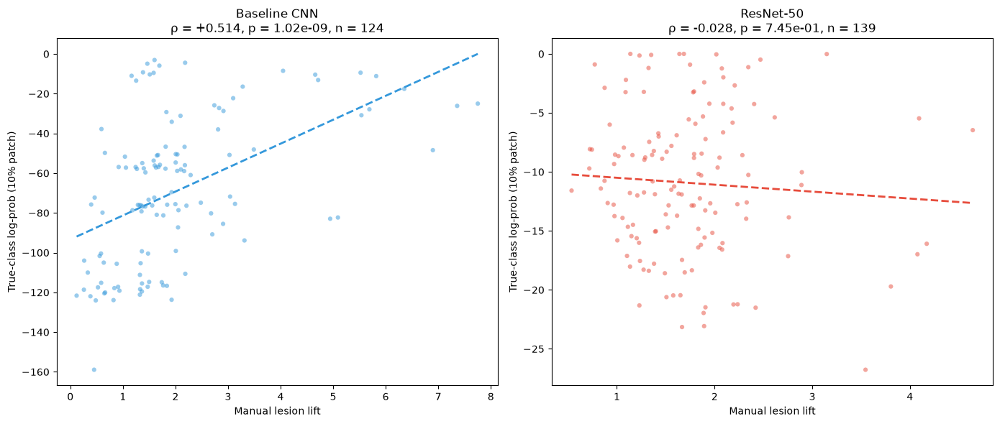

Saved to outputs/stage5_scatter_lift_logprob.png


In [70]:
colors = {'Baseline CNN': '#3498db', 'ResNet-50': '#e74c3c'}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, mname in zip(axes, ['Baseline CNN', 'ResNet-50']):
    sub_all = s5_df[(s5_df['model'] == mname) & (s5_df['clean_correct'] == 1)]
    sub = sub_all[sub_all['is_attractor_10pct'] == 0].copy()
    valid = sub[['manual_lesion_lift', 'logprob_10pct']].dropna()
    x, y = valid['manual_lesion_lift'].values, valid['logprob_10pct'].values
    ax.scatter(x, y, alpha=0.5, s=20, edgecolors='none', color=colors[mname])
    if len(valid) >= 5:
        z = np.polyfit(x, y, 1)
        xline = np.linspace(x.min(), x.max(), 100)
        ax.plot(xline, np.polyval(z, xline), color=colors[mname], linewidth=2, linestyle='--')
    rho, p = spearmanr(x, y)
    ax.set_xlabel('Manual lesion lift')
    ax.set_ylabel('True-class log-prob (10% patch)')
    ax.set_title(f'{mname}\nρ = {rho:+.3f}, p = {p:.2e}, n = {len(valid)}')
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage5_scatter_lift_logprob.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {OUTPUT_ROOT}/stage5_scatter_lift_logprob.png')

## Visual check with 4 seeded images

Visual check positions: [6045 5484 8084 2468]


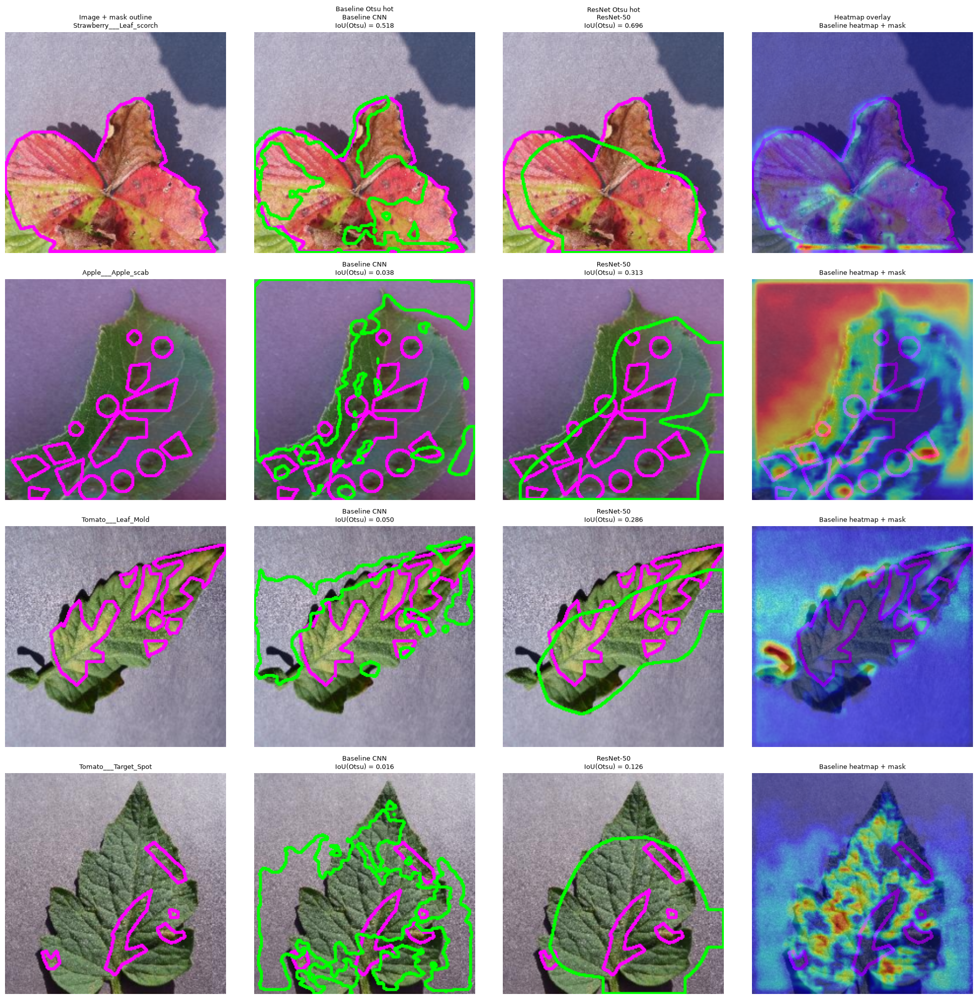

Saved to outputs/stage5_visual_check.png


In [71]:
rng_s5 = np.random.RandomState(SEED + 5)
s5_base = s5_df[(s5_df['model'] == 'Baseline CNN') & (s5_df['clean_correct'] == 1)]
s5_vis_positions = rng_s5.choice(s5_base['position'].values, size=4, replace=False)
print(f'Visual check positions: {s5_vis_positions}')
 
fig, axes = plt.subplots(4, 4, figsize=(20, 20))
col_titles = ['Image + mask outline', 'Baseline Otsu hot', 'ResNet Otsu hot', 'Heatmap overlay']
for row, pos in enumerate(s5_vis_positions):
    cand_i = np.where(cand_positions == pos)[0][0]
    img_t, lbl, leaf, lesion_proxy, _ = mask_ds[pos]
    img_rgb = unnormalize(img_t).permute(1, 2, 0).numpy()
    mm = manual_masks[cand_i]
    contours_mask, _ = cv2.findContours(mm.astype(np.uint8), cv2.RETR_EXTERNAL,
                                         cv2.CHAIN_APPROX_SIMPLE)
    img_outline = img_rgb.copy()
    cv2.drawContours(img_outline, contours_mask, -1, (1.0, 0.0, 1.0), 2)
    axes[row, 0].imshow(img_outline)
    axes[row, 0].set_title(filtered_classes[lbl], fontsize=9)
    for col_off, mname in enumerate(['Baseline CNN', 'ResNet-50']):
        cam_np = cache5[f'{mname}_cam_clean'][cand_i]
        hot_region, _ = otsu_hot(cam_np)
        contours_hot, _ = cv2.findContours(hot_region.astype(np.uint8), cv2.RETR_EXTERNAL,
                                            cv2.CHAIN_APPROX_SIMPLE)
        vis = img_rgb.copy()
        cv2.drawContours(vis, contours_mask, -1, (1.0, 0.0, 1.0), 2)
        cv2.drawContours(vis, contours_hot, -1, (0.0, 1.0, 0.0), 2)
        axes[row, 1 + col_off].imshow(vis)
        iou_val = s5_df[(s5_df['model'] == mname) & (s5_df['position'] == pos)]['iou_otsu'].values[0]
        axes[row, 1 + col_off].set_title(f'{mname}\nIoU(Otsu) = {iou_val:.3f}', fontsize=9)
    cam_base = cache5['Baseline CNN_cam_clean'][cand_i]
    overlay = img_rgb.copy()
    cv2.drawContours(overlay, contours_mask, -1, (1.0, 0.0, 1.0), 2)
    axes[row, 3].imshow(overlay)
    axes[row, 3].imshow(cam_base, cmap='jet', alpha=0.5, vmin=0, vmax=1)
    axes[row, 3].set_title('Baseline heatmap + mask', fontsize=9)
for c, t in enumerate(col_titles):
    axes[0, c].set_title(f'{t}\n{axes[0, c].get_title()}', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{OUTPUT_ROOT}/stage5_visual_check.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {OUTPUT_ROOT}/stage5_visual_check.png')

## Compare with Stage 4

In [72]:
from IPython.display import display, Markdown
s4_corr = pd.read_csv(f'{OUTPUT_ROOT}/stage4_correlations.csv')
s4_excl = s4_corr[s4_corr['scope'] == 'excl_attractor']
 
comparison_lines = ['## Stage 5 vs Stage 4: lesion lift ρ\n',
                    '| Model | Patch | Stage 4 ρ (proxy, p_patched) | Stage 5 ρ (manual, log-prob) | 95% CI |',
                    '|-------|-------|------|------|------|']
for mname in ['Baseline CNN', 'ResNet-50']:
    for frac in PATCH_FRACTIONS:
        tag = f'{int(round(frac*100))}pct'
        s4_lift = s4_excl[(s4_excl['model'] == mname) & (s4_excl['patch_frac'] == frac) &
                          (s4_excl['attention'] == 'lesion_lift') & (s4_excl['robustness'] == 'p_patched')]
        s5_lift = corr5_df[(corr5_df['model'] == mname) & (corr5_df['patch_frac'] == frac) &
                           (corr5_df['metric'] == 'manual_lesion_lift')]
        s4_rho = f'{s4_lift["spearman_rho"].values[0]:+.4f}' if len(s4_lift) else 'N/A'
        s5_rho = f'{s5_lift["spearman_rho"].values[0]:+.4f}' if len(s5_lift) else 'N/A'
        s5_ci = (f'[{s5_lift["ci_lo"].values[0]:+.3f}, {s5_lift["ci_hi"].values[0]:+.3f}]'
                 if len(s5_lift) else 'N/A')
        comparison_lines.append(f'| {mname} | {tag} | {s4_rho} | {s5_rho} | {s5_ci} |')
 
comparison_lines.append('')
comparison_lines.append('Proxy-vs-manual mask IoU (median): '
                        f'{np.median(proxy_ious):.3f}')
comparison_md = '\n'.join(comparison_lines)
display(Markdown(comparison_md))

## Stage 5 vs Stage 4: lesion lift ρ

| Model | Patch | Stage 4 ρ (proxy, p_patched) | Stage 5 ρ (manual, log-prob) | 95% CI |
|-------|-------|------|------|------|
| Baseline CNN | 5pct | +0.3941 | +0.4955 | [+0.345, +0.622] |
| Baseline CNN | 10pct | +0.4030 | +0.5140 | [+0.368, +0.641] |
| Baseline CNN | 15pct | +0.4894 | +0.5049 | [+0.357, +0.623] |
| ResNet-50 | 5pct | -0.1074 | -0.0657 | [-0.224, +0.095] |
| ResNet-50 | 10pct | -0.1461 | -0.0278 | [-0.203, +0.145] |
| ResNet-50 | 15pct | -0.1776 | -0.1346 | [-0.295, +0.029] |

Proxy-vs-manual mask IoU (median): 0.050

## Cross-model lift comparison (Wilcoxon) 

In [73]:

from scipy.stats import wilcoxon

base_lift = s5_df[s5_df['model'] == 'Baseline CNN']['manual_lesion_lift'].values
resn_lift = s5_df[s5_df['model'] == 'ResNet-50']['manual_lesion_lift'].values
assert len(base_lift) == len(resn_lift) == 150
stat, p_wilcox = wilcoxon(base_lift, resn_lift)
print(f'Paired Wilcoxon on manual lesion lift: stat={stat:.1f}, p={p_wilcox:.4f}')
print(f'Baseline median lift: {np.median(base_lift):.3f}')
print(f'ResNet   median lift: {np.median(resn_lift):.3f}')
print(f'Difference not significant (p = {p_wilcox:.2f})' if p_wilcox > 0.05
      else f'Difference significant (p = {p_wilcox:.4f})')

Paired Wilcoxon on manual lesion lift: stat=5509.0, p=0.7733
Baseline median lift: 1.591
ResNet   median lift: 1.667
Difference not significant (p = 0.77)
